# **Project Name** - 🛒 Integrated Retail Analytics for Store Optimization and Demand Forecasting



##### **Project Type** - Regression
##### **Contribution** - Individual

# **Project Summary**

Retail chains operate across diverse store formats, regional economic climates, and dynamic promotional cycles. Balancing volatile department-level customer demand against the risks of inventory stockouts and margin erosion from excessive markdowns requires an integrated predictive framework.

This project implements an end-to-end retail intelligence pipeline across 45 stores using point-of-sale data, physical footprints, and macroeconomic indicators. The framework isolates true demand shocks from inventory stockouts using contextual residual Z-scores and Isolation Forests, identifies store operating archetypes via K-Means clustering, discovers cross-category purchasing patterns through Apriori association rules, and deploys a 3-tier demand forecasting suite optimized for holiday-weighted error. Finally, model forecast uncertainty is translated directly into automated Safety Stock and Reorder Point policies to safeguard on-shelf availability while minimizing inventory holding costs.

# **GitHub Link**

# **Problem Statement**


Retail merchandising and supply chain leadership face substantial revenue leakage caused by static inventory replenishment and uncalibrated promotional forecasting. Traditional projection models fail to anticipate holiday demand surges, while phantom stockouts and recorded inventory write-offs distort replenishment cadences, resulting in lost sales, excess holding costs, and upstream supply chain bullwhip effects.

The objective of this project is to build an automated machine learning and inventory planning pipeline that predicts weekly department sales, isolates non-promotional data noise, discovers cross-category purchasing patterns, and computes dynamic inventory buffers to maintain a 95% on-shelf service level.

# ***Let's Begin !***

## ***1. Know Your Data***


### Import Libraries

In [2]:
# Install required external packages
# !pip install -q mlxtend lightgbm

# High-DPI Retina inline display
%config InlineBackend.figure_format = 'retina'

# Core data manipulation and mathematical computing
import os
import sys
import warnings
import joblib
import numpy as np
import pandas as pd
from scipy import stats

# Global Seed Initialization
SEED = 47
np.random.seed(SEED)

# Visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

# Preprocessing, decomposition, and clustering
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Anomaly detection and supervised regression models
from sklearn.ensemble import IsolationForest, RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV

# Market Basket Analysis (Apriori and Association Rules)
from mlxtend.frequent_patterns import apriori, association_rules

# Gradient Boosting
import lightgbm as lgb

# Environment configuration
warnings.filterwarnings('ignore')

# Custom Eye-Friendly Dark Theme Palette
CUSTOM_THEME = {
    'bg':       '#18191C',  # Soft Dark Slate Gray
    'card':     '#222428',  # Elevated Surface Card
    'grid':     '#32363C',  # Low-Contrast Grid Lines
    'text':     '#E3E5E8',  # Warm Off-White
    'subtext':  '#9B9D9E',  # Muted Axis Label Grey
    'teal':     '#2DD4BF',  # Soft Mint Teal
    'coral':    '#F87171',  # Soft Crimson Coral
    'purple':   '#A78BFA',  # Soft Amber Gold
    'orange':   '#FB923C',  # Soft Warm Orange
}

# Apply global parameters
plt.rcParams.update({
    'figure.facecolor':  CUSTOM_THEME['bg'],
    'axes.facecolor':    CUSTOM_THEME['card'],
    'savefig.facecolor': CUSTOM_THEME['bg'],
    'axes.edgecolor':    CUSTOM_THEME['grid'],
    'axes.labelcolor':   CUSTOM_THEME['text'],
    'xtick.color':       CUSTOM_THEME['subtext'],
    'ytick.color':       CUSTOM_THEME['subtext'],
    'grid.color':        CUSTOM_THEME['grid'],
    'grid.linestyle':    '--',
    'grid.alpha':        0.6,
    'text.color':        CUSTOM_THEME['text'],
    # 'axes.titlesize':    12,
    'axes.titlepad':     12,
    'axes.labelpad':     8,
})


In [3]:
import textwrap

def custom_display(
    title: str | None = None,
    content: str | list[str] | None = None,
    max_width: int = 70,
    padding: int = 2
):
    """
    Renders structured text inside a Unicode box.
    - Centers the title/header if the content width spans wider.
    - Supports (title, content), (content), or (title) dynamically.
    - Honors explicit '\n' line breaks and wraps unbroken lines exceeding max_width.
    """
    pad_space = " " * padding

    # Handle single positional argument intended as content
    if content is None and title is not None and ('\n' in title or len(title) > max_width):
        content = title
        title = None

    # Parse and wrap content lines
    formatted_lines = []
    if content is not None:
        if isinstance(content, str):
            raw_sections = content.split('\n')
        else:
            raw_sections = [line for item in content for line in str(item).split('\n')]

        for section in raw_sections:
            stripped = section.strip()
            if not stripped:
                formatted_lines.append("")
            elif len(section) > max_width:
                formatted_lines.extend(textwrap.wrap(section, width=max_width))
            else:
                formatted_lines.append(section)

    title_str = title.strip() if title else ""
    has_title = bool(title_str)
    has_content = bool(formatted_lines)

    if not has_title and not has_content:
        return

    # Calculate max width across both title and content
    max_content_len = max([len(line) for line in formatted_lines]) if has_content else 0
    max_line_len = max(len(title_str) if has_title else 0, max_content_len)

    inner_width = max_line_len + (padding * 2)

    # Render Box
    print(f"┌{'─' * inner_width}┐")
    if has_title:
        # Centers the header text across the total inner width
        print(f"│{title_str.center(inner_width)}│")
        if has_content:
            print(f"├{'─' * inner_width}┤")

    if has_content:
        for line in formatted_lines:
            print(f"│{pad_space}{line.ljust(max_line_len)}{pad_space}│")

    print(f"└{'─' * inner_width}┘")

### Dataset Loading

We load the three retail datasets directly from their shared Google Drive download URLs:
1. `stores.csv`: Metadata for 45 stores, including store type (`A`, `B`, `C`) and physical floor size.
2. `Features.csv`: Exogenous store-week data covering temperature, fuel price, markdowns 1–5, CPI, unemployment, and holiday flags.
3. `sales.csv`: Historical weekly sales records across stores and departments.

In [4]:
# Direct Google Drive shared CSV URLs
STORES_CSV_FILE_ID = "1JoaizpTbsYwT080gjZ-enrYXyzsdgLMs"
FEATURES_CSV_FILE_ID = "1JKKCIaHRqTVd5-AiAP7zURI4HiH75_Uw"
SALES_CSV_FILE_ID = "1fLQpF8fOfIzF1aBsqiWBIhPU75tkWs8P"

csv_export_url = "https://drive.google.com/uc?export=download&id={}"

stores_df = pd.read_csv(csv_export_url.format(STORES_CSV_FILE_ID))
features_df = pd.read_csv(csv_export_url.format(FEATURES_CSV_FILE_ID))
sales_df = pd.read_csv(csv_export_url.format(SALES_CSV_FILE_ID))

### Dataset First View

In [5]:
print("--- STORES SAMPLE ---")
display(stores_df.head(3))

print("\n--- FEATURES SAMPLE ---")
display(features_df.head(3))

print("\n--- SALES SAMPLE ---")
display(sales_df.head(3))

--- STORES SAMPLE ---


,Store,Type,Size
0,1,A,151315
1,2,A,202307
2,3,B,37392



--- FEATURES SAMPLE ---


,Store,Date,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,IsHoliday
0,1,05/02/2010,42.31,2.572,NaN,NaN,NaN,NaN,NaN,211.096358,8.106,False
1,1,12/02/2010,38.51,2.548,NaN,NaN,NaN,NaN,NaN,211.242170,8.106,True
2,1,19/02/2010,39.93,2.514,NaN,NaN,NaN,NaN,NaN,211.289143,8.106,False



--- SALES SAMPLE ---


,Store,Dept,Date,Weekly_Sales,IsHoliday
0,1,1,05/02/2010,24924.50,False
1,1,1,12/02/2010,46039.49,True
2,1,1,19/02/2010,41595.55,False


### Dataset Rows & Columns count

In [6]:
custom_display("DATASET DIMENSIONS OVERVIEW", content=[
    f"Stores   : {stores_df.shape[0]:7d} rows | {stores_df.shape[1]:2d} columns",
    f"Features : {features_df.shape[0]:7d} rows | {features_df.shape[1]:2d} columns",
    f"Sales    : {sales_df.shape[0]:,} rows | {sales_df.shape[1]:2d} columns"
])

┌────────────────────────────────────────┐
│      DATASET DIMENSIONS OVERVIEW       │
├────────────────────────────────────────┤
│  Stores   :      45 rows |  3 columns  │
│  Features :    8190 rows | 12 columns  │
│  Sales    : 421,570 rows |  5 columns  │
└────────────────────────────────────────┘


### Dataset Information

In [7]:
# Dataset Info
for name, df in zip(['Stores', 'Features', 'Sales'], [stores_df, features_df, sales_df]):
    print(f"\n{'='*25} {name} Data Info {'='*25}")
    df.info()
    custom_display(content=[
        f'Missing Values   : {df.isnull().sum().sum()}',
        f'Duplicate Rows   : {df.duplicated().sum()}',
    ])


========================= Stores Data Info =========================
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45 entries, 0 to 44
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Store   45 non-null     int64 
 1   Type    45 non-null     object
 2   Size    45 non-null     int64 
dtypes: int64(2), object(1)
memory usage: 1.2+ KB
┌────────────────────────┐
│  Missing Values   : 0  │
│  Duplicate Rows   : 0  │
└────────────────────────┘

========================= Features Data Info =========================
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8190 entries, 0 to 8189
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Store         8190 non-null   int64  
 1   Date          8190 non-null   object 
 2   Temperature   8190 non-null   float64
 3   Fuel_Price    8190 non-null   float64
 4   MarkDown1     4032 non-null   float64
 5   MarkD

## ***2. Understanding Your Variables***

In [8]:
# Dataset Describe
print(f"\n{'='*10} Stores Info {'='*10}")
display(stores_df.describe())

print(f"\n{'='*10} Features Info {'='*10}")
display(features_df.describe())

print(f"\n{'='*10} Sales Info {'='*10}")
display(sales_df.describe())


========== Stores Info ==========


,Store,Size
count,45.000000,45.000000
mean,23.000000,130287.600000
std,13.133926,63825.271991
min,1.000000,34875.000000
25%,12.000000,70713.000000
50%,23.000000,126512.000000
75%,34.000000,202307.000000
max,45.000000,219622.000000



========== Features Info ==========


,Store,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment
count,8190.000000,8190.000000,8190.000000,4032.000000,2921.000000,3613.000000,3464.000000,4050.000000,7605.000000,7605.000000
mean,23.000000,59.356198,3.405992,7032.371786,3384.176594,1760.100180,3292.935886,4132.216422,172.460809,7.826821
std,12.987966,18.678607,0.431337,9262.747448,8793.583016,11276.462208,6792.329861,13086.690278,39.738346,1.877259
min,1.000000,-7.290000,2.472000,-2781.450000,-265.760000,-179.260000,0.220000,-185.170000,126.064000,3.684000
25%,12.000000,45.902500,3.041000,1577.532500,68.880000,6.600000,304.687500,1440.827500,132.364839,6.634000
50%,23.000000,60.710000,3.513000,4743.580000,364.570000,36.260000,1176.425000,2727.135000,182.764003,7.806000
75%,34.000000,73.880000,3.743000,8923.310000,2153.350000,163.150000,3310.007500,4832.555000,213.932412,8.567000
max,45.000000,101.950000,4.468000,103184.980000,104519.540000,149483.310000,67474.850000,771448.100000,228.976456,14.313000



========== Sales Info ==========


,Store,Dept,Weekly_Sales
count,421570.000000,421570.000000,421570.000000
mean,22.200546,44.260317,15981.258123
std,12.785297,30.492054,22711.183519
min,1.000000,1.000000,-4988.940000
25%,11.000000,18.000000,2079.650000
50%,22.000000,37.000000,7612.030000
75%,33.000000,74.000000,20205.852500
max,45.000000,99.000000,693099.360000


### Variables Description

#### 1. `stores.csv`
* **Store**: Unique numeric identifier for each store outlet (1 to 45).
* **Type**: Store format classification based on physical scale and assortment breadth (`A` = Supercenter, `B` = Mid-sized, `C` = Small format).
* **Size**: Total physical floor area in square feet.



#### 2. `Features.csv`
* **Store**: Store identifier linking to `stores.csv`.
* **Date**: Week-ending date formatted as `DD/MM/YYYY`.
* **Temperature**: Regional weekly ambient temperature in Fahrenheit (°F).
* **Fuel_Price**: Average regional fuel cost in USD per gallon ($/gal).
* **MarkDown1–5**: Anonymized promotional discount spending across five distinct event mechanisms (structural nulls present before Nov 2011).
* **CPI**: Consumer Price Index measuring inflation and local purchasing power.
* **Unemployment**: Regional unemployment rate expressed as a percentage.
* **IsHoliday**: Boolean indicator (`True`/`False`) marking weeks with recognized major retail holidays.



#### 3. `sales.csv`
* **Store**: Store identifier linking to `stores.csv`.
* **Dept**: Department numeric identifier within the store (1 to 99).
* **Date**: Week-ending date (`DD/MM/YYYY`), forming a composite key with `Store` and `Dept`.
* **Weekly_Sales**: Total weekly department revenue in USD (**Primary Target**; negative values denote returns or inventory adjustments).
* **IsHoliday**: Binary holiday flag used to assign 5× error weighting in Weighted Mean Absolute Error (WMAE).

### Check Unique Values for each variable.

In [9]:
for name, df in zip(['Stores', 'Features', 'Sales'], [stores_df, features_df, sales_df]):
    print(f"\n{'='*10} {name} Data Info {'='*10}")
    cat_cols = df.select_dtypes(include=['object']).columns.tolist()
    for col in cat_cols:
        unique_vals = df[col].nunique()
        sample_vals = df[col].unique()[:5]
        print(f"Column '{col}': {unique_vals} unique values | Samples: {sample_vals}")


========== Stores Data Info ==========
Column 'Type': 3 unique values | Samples: ['A' 'B' 'C']

========== Features Data Info ==========
Column 'Date': 182 unique values | Samples: ['05/02/2010' '12/02/2010' '19/02/2010' '26/02/2010' '05/03/2010']

========== Sales Data Info ==========
Column 'Date': 143 unique values | Samples: ['05/02/2010' '12/02/2010' '19/02/2010' '26/02/2010' '05/03/2010']


## ***3. Data Wrangling***

### Data Wrangling Code

In [10]:
# Date Parsing
features_df['Date'] = pd.to_datetime(features_df['Date'], format='%d/%m/%Y')
sales_df['Date'] = pd.to_datetime(sales_df['Date'], format='%d/%m/%Y')

# Merge into Unified Analytical Mart
df_merged = sales_df.merge(stores_df, on='Store', how='left')
df_merged = df_merged.merge(features_df, on=['Store', 'Date'], how='left', suffixes=('', '_feat'))

# Resolve redundant IsHoliday column if duplicated
if 'IsHoliday_feat' in df_merged.columns:
    df_merged.drop(columns=['IsHoliday_feat'], inplace=True)

# Handle MarkDown Nulls and Create Binary Indicators
markdown_cols = ['MarkDown1', 'MarkDown2', 'MarkDown3', 'MarkDown4', 'MarkDown5']
for col in markdown_cols:
    df_merged[f'Has_{col}'] = df_merged[col].notnull().astype(int)
    df_merged[col] = df_merged[col].fillna(0.0)

# Handle any remaining nulls in macroeconomic telemetry via forward-fill per store
df_merged['CPI'] = df_merged.groupby('Store')['CPI'].transform(lambda x: x.ffill().bfill())
df_merged['Unemployment'] = df_merged.groupby('Store')['Unemployment'].transform(lambda x: x.ffill().bfill())

# Audit Negative Weekly Sales (Returns and Inventory Adjustments)
negative_sales_mask = df_merged['Weekly_Sales'] < 0
negative_count = negative_sales_mask.sum()
print(f"Total Negative Sales Records (Returns / Adjustments): {negative_count:,} ({negative_count / len(df_merged) * 100:.3f}%)")

# Separate return volume for auditing and clip negative sales to 0 for baseline demand forecasting
df_merged['Is_Return_Adjustment'] = negative_sales_mask.astype(int)
df_clean = df_merged.copy()
df_clean['Weekly_Sales_Clean'] = df_clean['Weekly_Sales'].clip(lower=0.0)

# Sort chronologically by Store, Department, and Date
df_clean = df_clean.sort_values(by=['Store', 'Dept', 'Date']).reset_index(drop=True)

print("Unified analytical mart shape:", df_clean.shape)
display(df_clean.head())

Total Negative Sales Records (Returns / Adjustments): 1,285 (0.305%)
Unified analytical mart shape: (421570, 23)


,Store,Dept,Date,Weekly_Sales,IsHoliday,Type,Size,Temperature,Fuel_Price,MarkDown1,...,MarkDown5,CPI,Unemployment,Has_MarkDown1,Has_MarkDown2,Has_MarkDown3,Has_MarkDown4,Has_MarkDown5,Is_Return_Adjustment,Weekly_Sales_Clean
0,1,1,2010-02-05,24924.50,False,A,151315,42.31,2.572,0.0,...,0.0,211.096358,8.106,0,0,0,0,0,0,24924.50
1,1,1,2010-02-12,46039.49,True,A,151315,38.51,2.548,0.0,...,0.0,211.242170,8.106,0,0,0,0,0,0,46039.49
2,1,1,2010-02-19,41595.55,False,A,151315,39.93,2.514,0.0,...,0.0,211.289143,8.106,0,0,0,0,0,0,41595.55
3,1,1,2010-02-26,19403.54,False,A,151315,46.63,2.561,0.0,...,0.0,211.319643,8.106,0,0,0,0,0,0,19403.54
4,1,1,2010-03-05,21827.90,False,A,151315,46.50,2.625,0.0,...,0.0,211.350143,8.106,0,0,0,0,0,0,21827.90


### What all manipulations have you done and insights you found?

#### **Chronological Standardization & Table Merging**
Dates are formatted as `DD/MM/YYYY` in the raw files. We parse them strictly with `pd.to_datetime(format='%d/%m/%Y')` to prevent month/day inversion errors.

We then construct a single unified data mart:
- Merge `sales` with `stores` on `Store`.
- Merge the resulting table with `features` on `['Store', 'Date']`.
- Deduplicate the redundant `IsHoliday` column that exists in both source tables.

#### **Handling Structural Missingness in MarkDowns**
Promotional markdowns (`MarkDown1` to `MarkDown5`) contain missing values, particularly before November 2011 when markdown tracking began.
- A missing markdown value indicates that no promotional discount was active that week.
- We impute missing markdown values with `0.0`.
- To preserve the distinction between an unpromoted period and an active zero-dollar discount, we create binary indicator flags: `Has_MarkDown1` through `Has_MarkDown5`.

#### **Auditing Negative Sales & Return Transactions**
In retail point-of-sale logs, negative sales represent customer returns, damaged inventory write-offs, or accounting adjustments. We separate return records so they do not distort normal sales velocity or break log transforms.


## ***4. Visual Storytelling & Exploratory Data Analysis (UBM Framework)***


### Univariate Analysis

#### Chart 1: Distribution of Weekly Sales (Raw vs. Log Transformed)


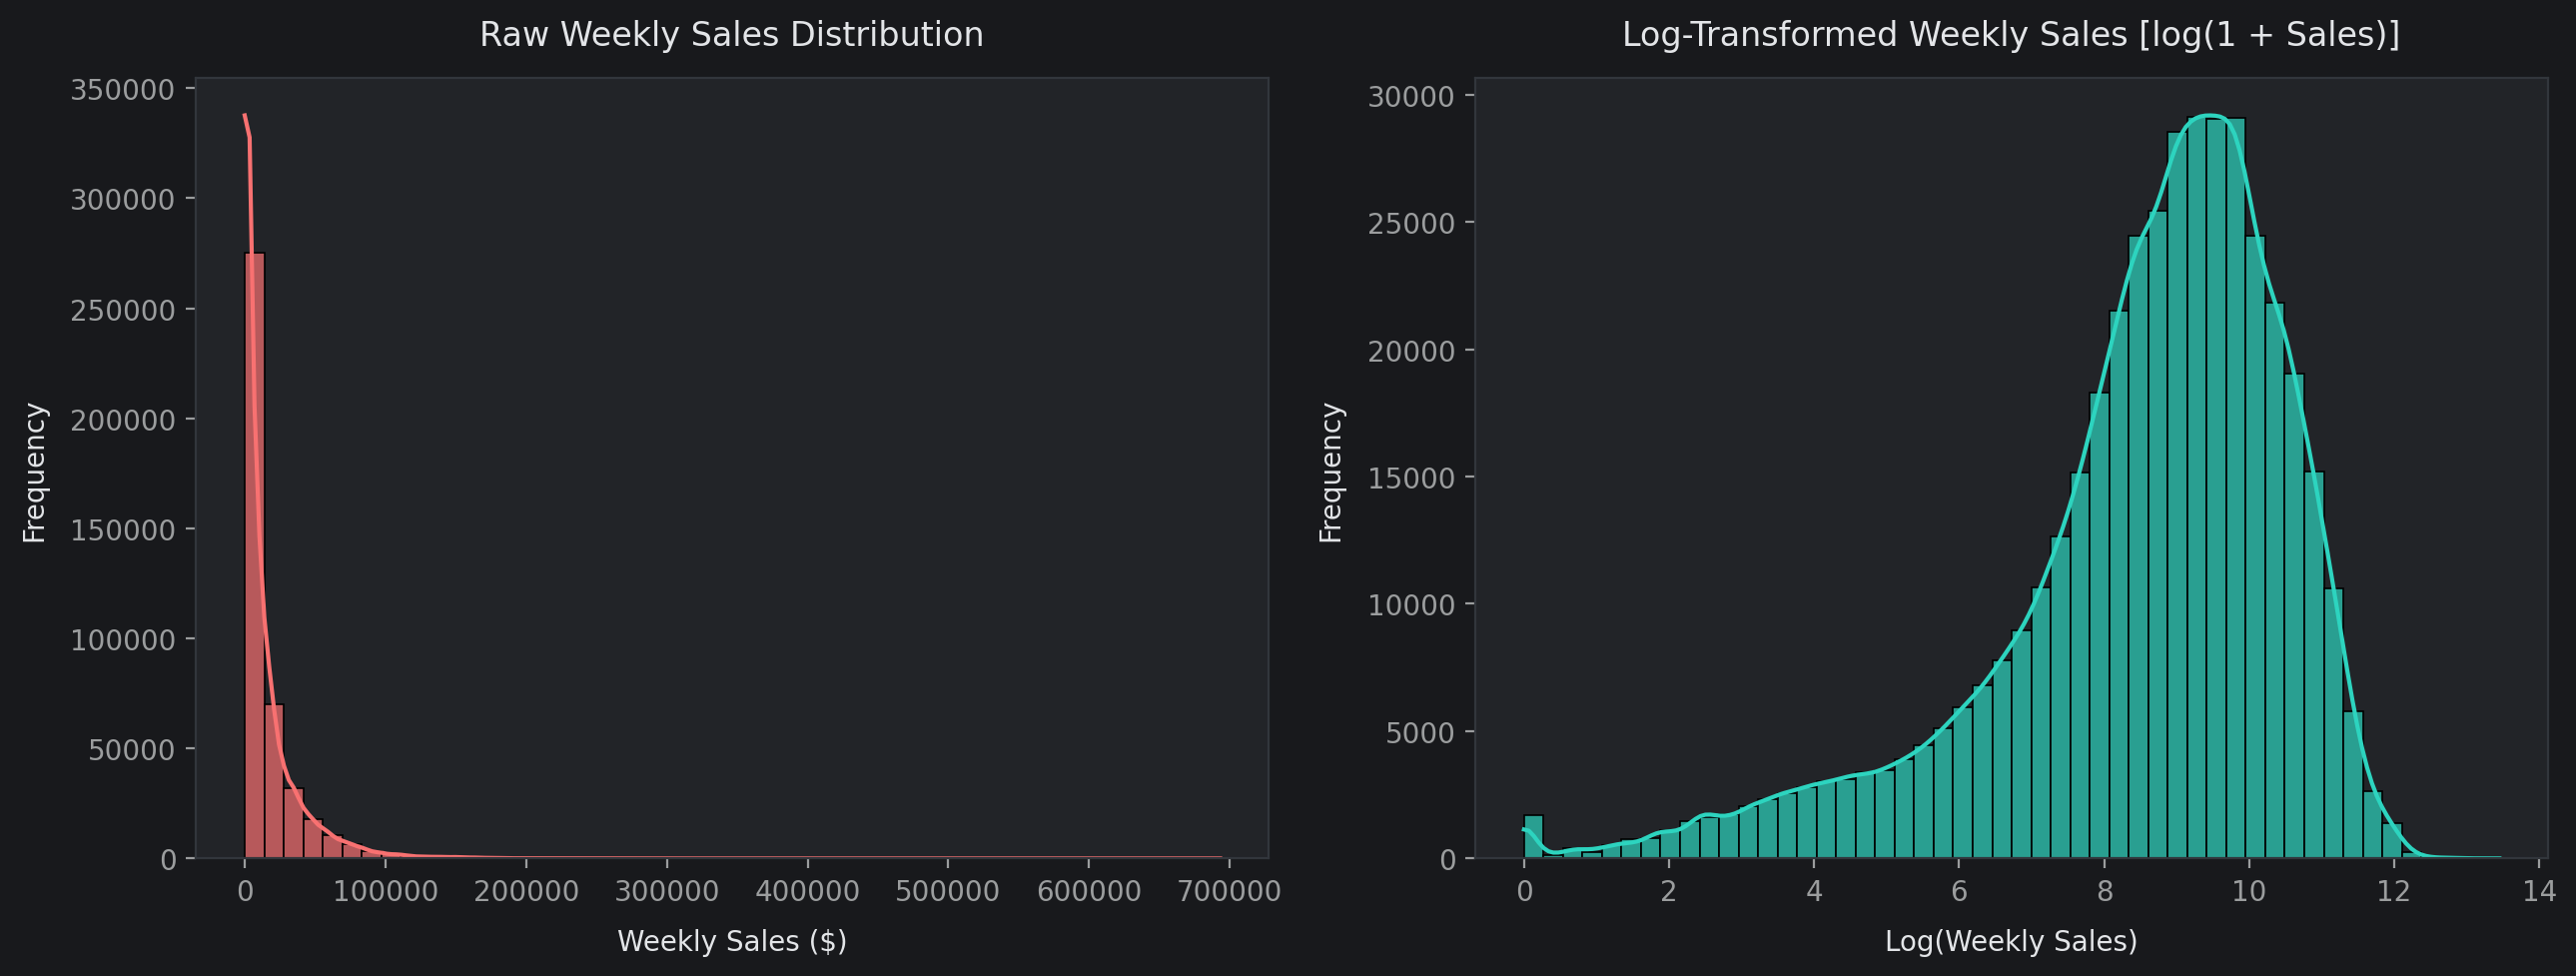

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(df_clean['Weekly_Sales_Clean'], bins=50, kde=True, color=CUSTOM_THEME['coral'], ax=axes[0], alpha=0.7)
axes[0].set_title('Raw Weekly Sales Distribution')
axes[0].set_xlabel('Weekly Sales ($)')
axes[0].set_ylabel('Frequency')

log_sales = np.log1p(df_clean['Weekly_Sales_Clean'])
sns.histplot(log_sales, bins=50, kde=True, color=CUSTOM_THEME['teal'], ax=axes[1], alpha=0.7)
axes[1].set_title('Log-Transformed Weekly Sales [log(1 + Sales)]')
axes[1].set_xlabel('Log(Weekly Sales)')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

#### Chart 1 Evaluation & Strategic Insights
1. **Why did you pick the specific chart?**  
   A dual histogram comparing raw vs. log-transformed weekly sales identifies skewness, extreme outliers, and the structural distribution of revenue across departments.

2. **What is/are the insight(s) found from the chart?**  
   Weekly sales are heavily right-skewed with standard department-weeks generating under \$25,000, while holiday spikes exceed \$100,000. Applying a log transform produces a near-bimodal curve separating low-velocity peripheral categories from high-turnover staple departments.

3. **Will the gained insight help create a positive business impact?**  
   Yes. Recognizing this right-skewness prevents default linear models from underpredicting high-value holiday surges. It directly justifies using tree-based gradient boosting models and Weighted Mean Absolute Error (WMAE) to handle asymmetric holiday demand.


#### Chart 2: Store Physical Size Distribution Across Store Types


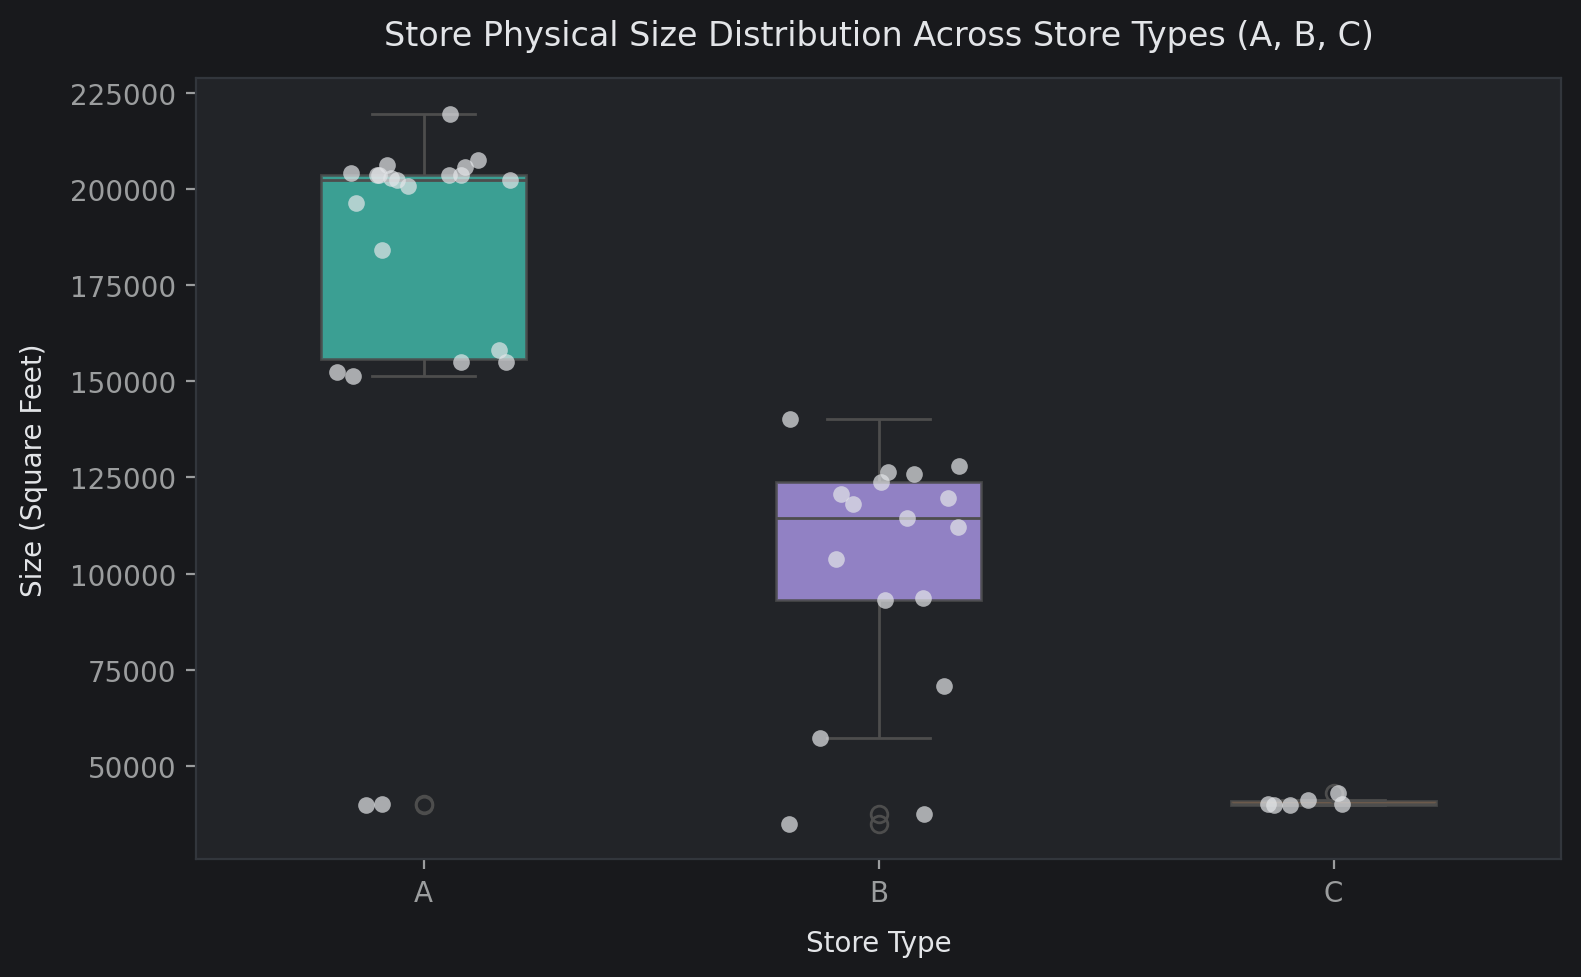

In [12]:
plt.figure(figsize=(8, 5))
palette_types = [CUSTOM_THEME['teal'], CUSTOM_THEME['purple'], CUSTOM_THEME['orange']]
sns.boxplot(x='Type', y='Size', data=stores_df, palette=palette_types, width=0.45, boxprops=dict(alpha=0.8))
sns.stripplot(x='Type', y='Size', data=stores_df, color=CUSTOM_THEME['text'], alpha=0.7, jitter=0.2, size=6)

plt.title('Store Physical Size Distribution Across Store Types (A, B, C)')
plt.xlabel('Store Type')
plt.ylabel('Size (Square Feet)')

plt.tight_layout()
plt.show()

#### Chart 2 Evaluation & Strategic Insights
1. **Why did you pick the specific chart?**  
   A combined boxplot and stripplot displays summary statistics (median, interquartile range) and individual store counts across each physical store tier (`A`, `B`, `C`).

2. **What is/are the insight(s) found from the chart?**  
   Store Type `A` represents large supercenters (150,000–220,000 sq. ft.), Type `B` represents mid-sized formats (100,000–140,000 sq. ft.), and Type `C` represents compact stores (~40,000 sq. ft.). There is virtually no overlap between Type `A` and Type `C`.
   
3. **Will the gained insight help create a positive business impact?**  
   Yes. Confirms that store format serves as a reliable proxy for physical footprint, allowing operations to standardize inventory assortments and space planning by format tier.


#### Chart 3: Store Count vs. Revenue Contribution Share


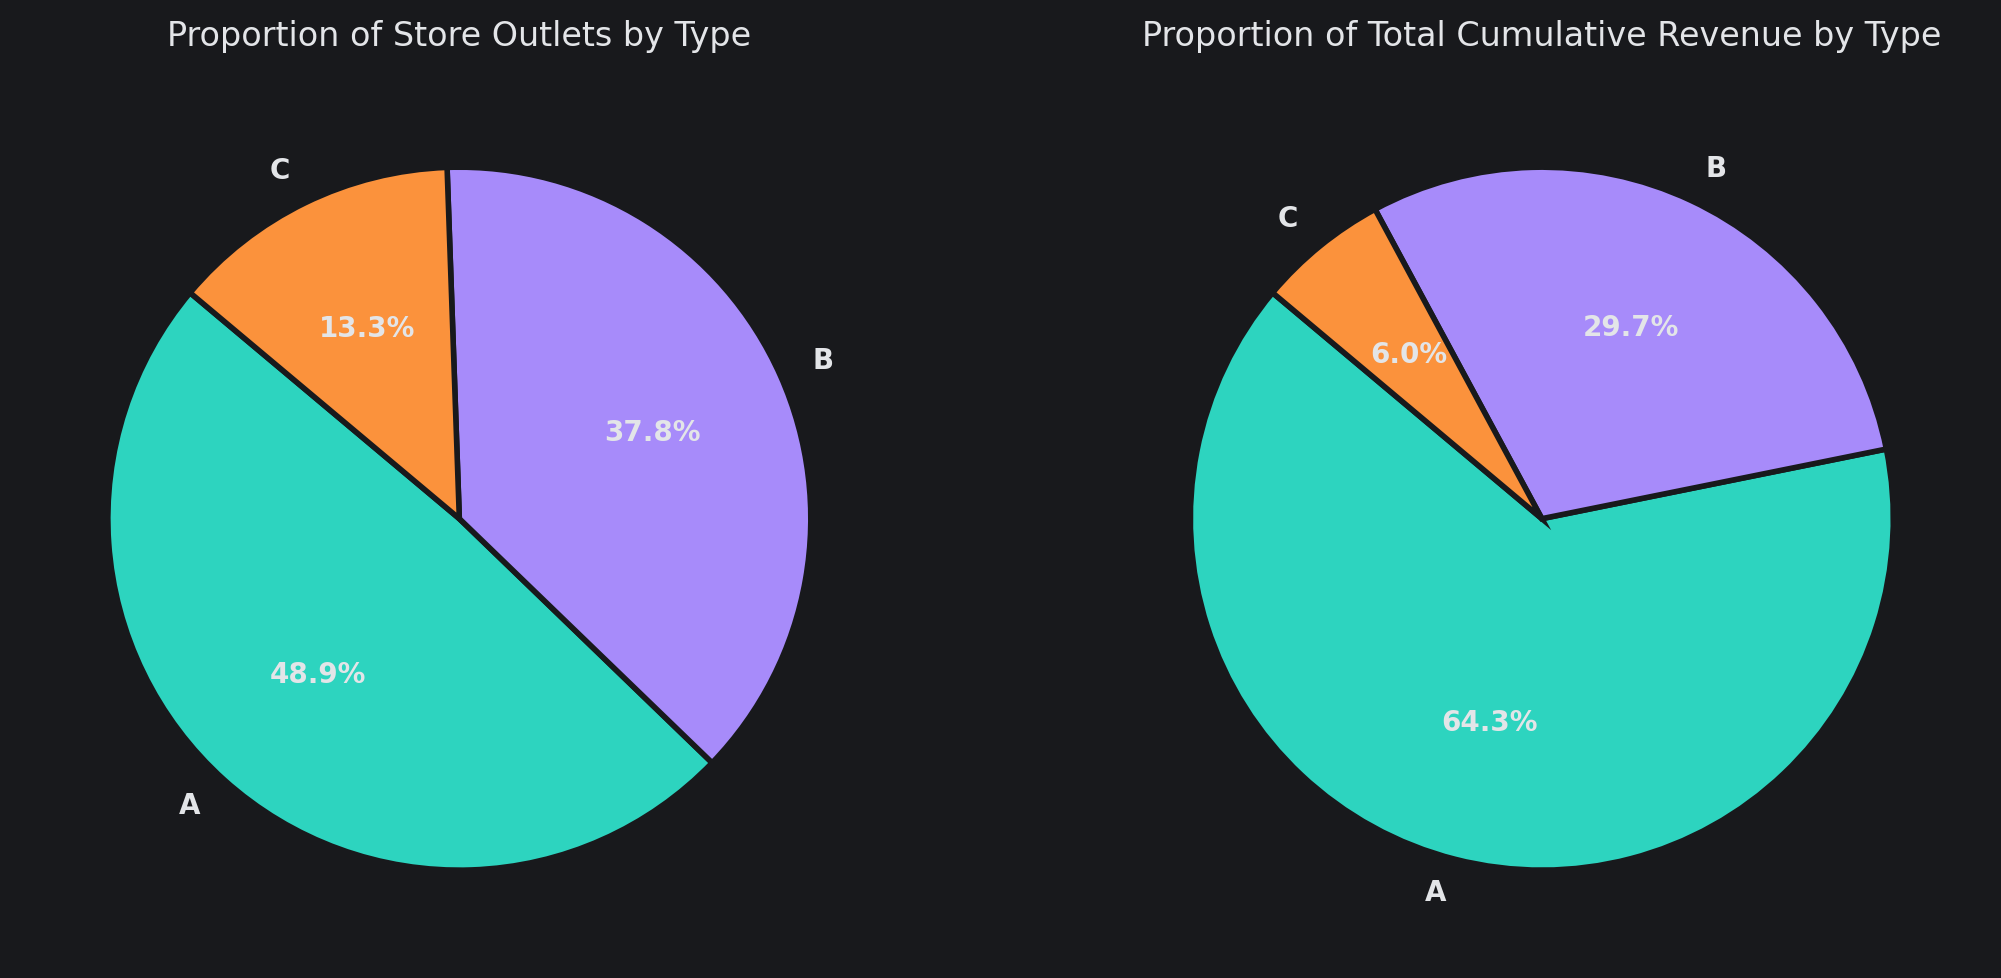

In [13]:
type_stats = df_clean.groupby('Type').agg(
    Store_Count=('Store', 'nunique'),
    Total_Sales=('Weekly_Sales_Clean', 'sum')
).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
axes[0].pie(type_stats['Store_Count'], labels=type_stats['Type'], autopct='%1.1f%%',
            colors=palette_types, startangle=140, textprops={'color': CUSTOM_THEME['text'], 'weight': 'bold'},
            wedgeprops={'edgecolor': CUSTOM_THEME['bg'], 'linewidth': 2})
axes[0].set_title('Proportion of Store Outlets by Type')

axes[1].pie(type_stats['Total_Sales'], labels=type_stats['Type'], autopct='%1.1f%%',
            colors=palette_types, startangle=140, textprops={'color': CUSTOM_THEME['text'], 'weight': 'bold'},
            wedgeprops={'edgecolor': CUSTOM_THEME['bg'], 'linewidth': 2})
axes[1].set_title('Proportion of Total Cumulative Revenue by Type')

plt.tight_layout()
plt.show()

#### Chart 3 Evaluation & Strategic Insights
1. **Why did you pick the specific chart?**  
   Dual pie charts directly contrast physical outlet counts against actual cumulative revenue share across store formats.

2. **What is/are the insight(s) found from the chart?**  
   Type `A` stores represent ~49% of physical outlets but generate nearly 65% of total chain sales. Type `C` locations represent ~13% of outlets and account for less than 5% of gross sales volume.
   
3. **Will the gained insight help create a positive business impact?**  
   Yes. Executive supply chain and procurement teams should allocate replenishment focus and promotional capital primarily to Type `A` stores, where minor efficiency improvements yield disproportionately higher dollar returns.


#### Chart 4: Active Promotional MarkDown Expenditure Spread

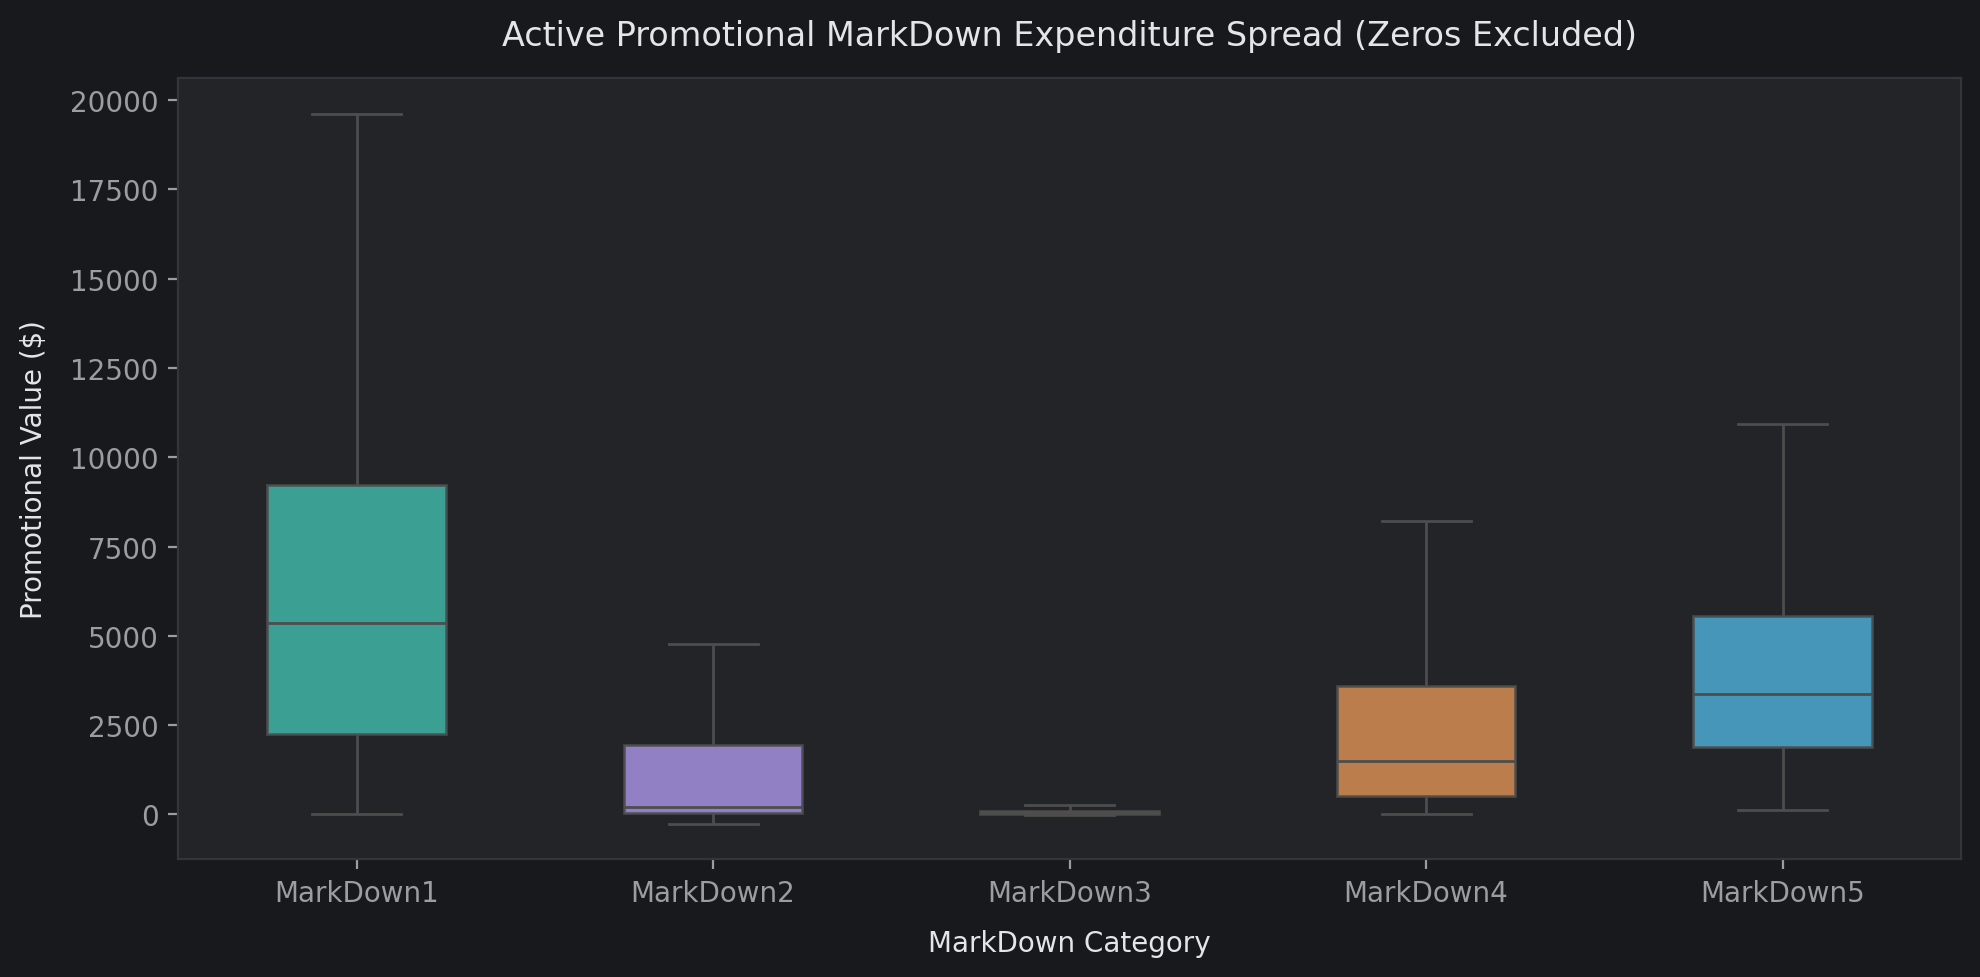

In [14]:
md_melted = df_clean[markdown_cols].replace(0, np.nan).melt(var_name='MarkDown_Type', value_name='Amount')
plt.figure(figsize=(10, 5))
md_palette = [CUSTOM_THEME['teal'], CUSTOM_THEME['purple'], CUSTOM_THEME['coral'], CUSTOM_THEME['orange'], '#38BDF8']
sns.boxplot(x='MarkDown_Type', y='Amount', data=md_melted, palette=md_palette, showfliers=False, width=0.5, boxprops=dict(alpha=0.8))
plt.title('Active Promotional MarkDown Expenditure Spread (Zeros Excluded)')
plt.xlabel('MarkDown Category')
plt.ylabel('Promotional Value ($)')

plt.tight_layout()
plt.show()

#### Chart 4 Evaluation & Strategic Insights
1. **Why did you pick the specific chart?**  
   A comparative boxplot of non-zero markdowns isolates active promotional events and displays the relative magnitude and dispersion of discount expenditures across all five categories.

2. **What is/are the insight(s) found from the chart?**  
   `MarkDown1` and `MarkDown5` show the highest typical dollar allocations, indicating they represent chain-wide seasonal clearance events. `MarkDown3` and `MarkDown4` are smaller and targeted, primarily deployed during short-duration holiday promotional pushes.
   
3. **Will the gained insight help create a positive business impact?**  
   Yes. Merchandisers can prioritize `MarkDown1` and `MarkDown5` for vendor co-op funding negotiations, while reserving `MarkDown3` for competitive holiday price-matching.


#### Chart 5: Ambient Regional Temperature Spread Across Store Locations


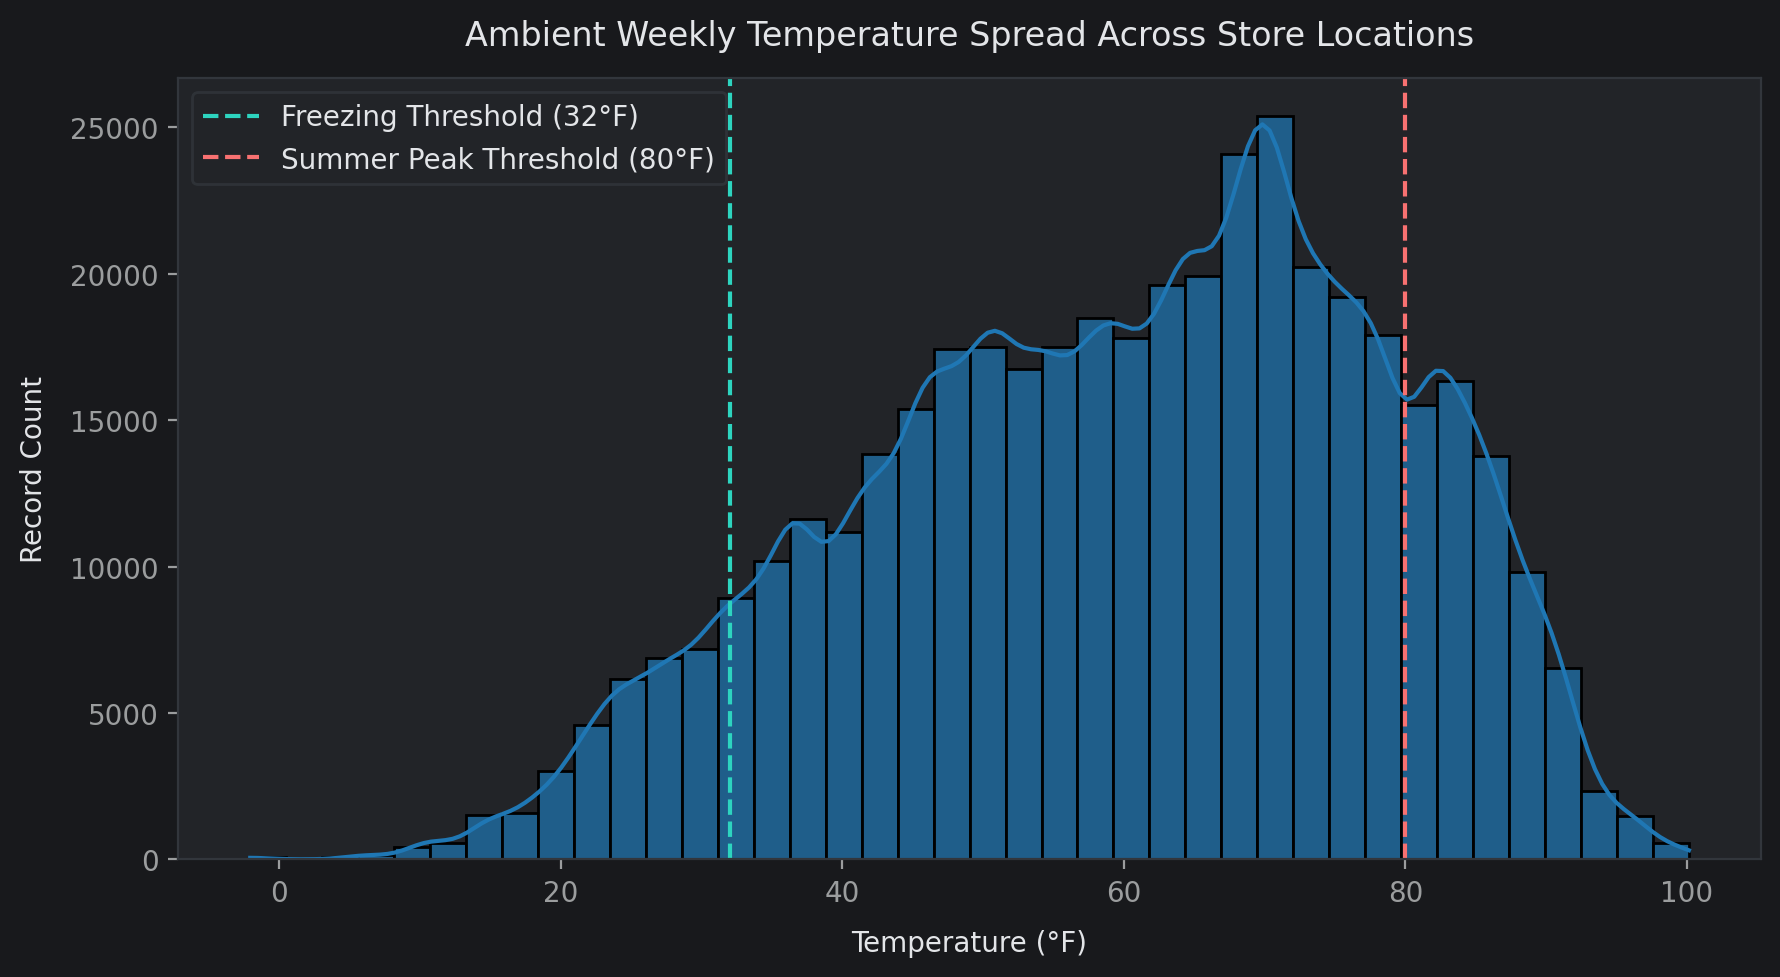

In [15]:
plt.figure(figsize=(9, 5))
sns.histplot(df_clean['Temperature'], bins=40, kde=True, alpha=0.7)
plt.title('Ambient Weekly Temperature Spread Across Store Locations')
plt.xlabel('Temperature (°F)')
plt.ylabel('Record Count')
plt.axvline(32, color=CUSTOM_THEME['teal'], linestyle='--', lw=1.5, label='Freezing Threshold (32°F)')
plt.axvline(80, color=CUSTOM_THEME['coral'], linestyle='--', lw=1.5, label='Summer Peak Threshold (80°F)')
plt.legend(facecolor=CUSTOM_THEME['card'], edgecolor=CUSTOM_THEME['grid'])

plt.tight_layout()
plt.show()

#### Chart 5 Evaluation & Strategic Insights
1. **Why did you pick the specific chart?**  
   A temperature histogram with marked seasonal thresholds shows how exposed the store network is to climatic extremes (sub-freezing winter vs. hot summer peaks).
2. **What is/are the insight(s) found from the chart?**  
   The temperature distribution is multimodal, centered around 60°F, with notable sub-freezing readings during winter weeks and peaks exceeding 85°F in summer.
3. **Will the gained insight help create a positive business impact?**  
   Yes. Weather-sensitive product categories—such as outdoor patio furniture, lawn care, and winter outerwear—can be stocked based on regional temperature shifts rather than fixed calendar dates.


### Chart 6: Mean Weekly Department Sales by Store Type


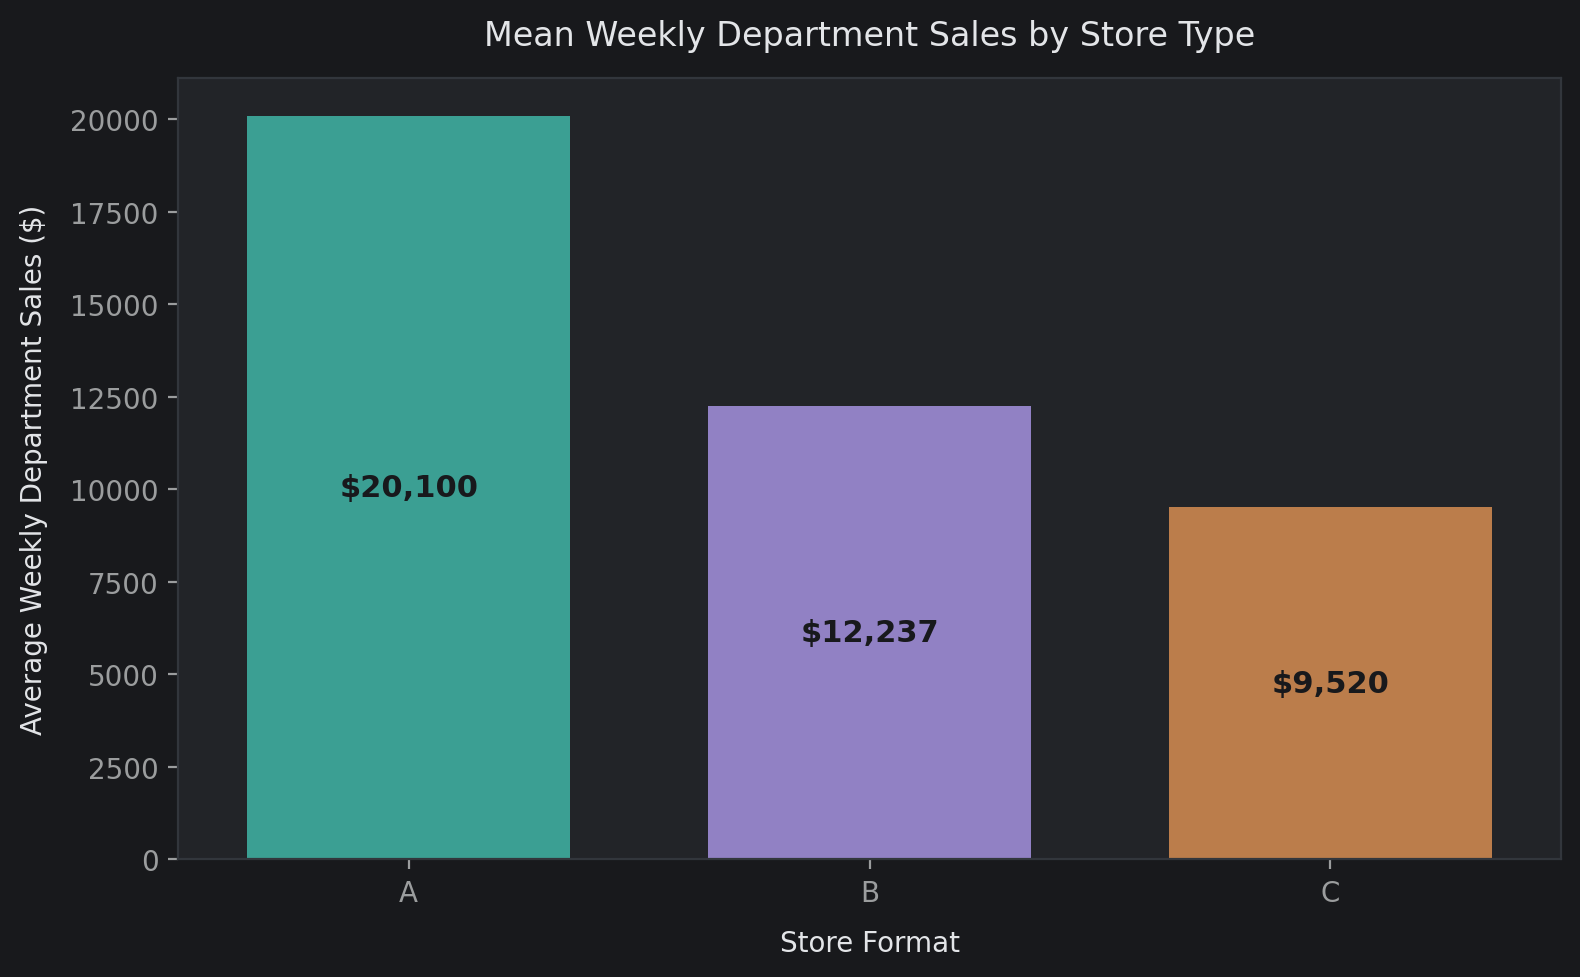

In [16]:
plt.figure(figsize=(8, 5))
ax_c6 = sns.barplot(x='Type', y='Weekly_Sales_Clean', data=df_clean, palette=palette_types, ci=None, alpha=0.8, width=0.7)
plt.title('Mean Weekly Department Sales by Store Type')
plt.xlabel('Store Format')
plt.ylabel('Average Weekly Department Sales ($)')
for p in ax_c6.patches:
    ax_c6.annotate(f"${p.get_height():,.0f}", (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                   ha='center', va='center', color=CUSTOM_THEME['bg'], fontweight='bold', fontsize=11)

plt.tight_layout()
plt.show()

#### Chart 6 Evaluation & Strategic Insights
1. **Why did you pick the specific chart?**  
   A bar chart comparing average weekly department sales across store types makes it easy to compare baseline revenue productivity across formats.

2. **What is/are the insight(s) found from the chart?**  
   Departments in Type `A` stores average ~$20,096 per week, compared to $12,230 for Type `B`, and $9,519 for Type `C`. Type `A` departments generate more than double the volume of Type `C`.
   
3. **Will the gained insight help create a positive business impact?**  
   Yes. Forecasting models must incorporate store scale interactions. Base inventory allocations and replenishment frequencies should be tiered to match format capacities.


### Chart 7: Holiday vs. Non-Holiday Weekly Sales Lift


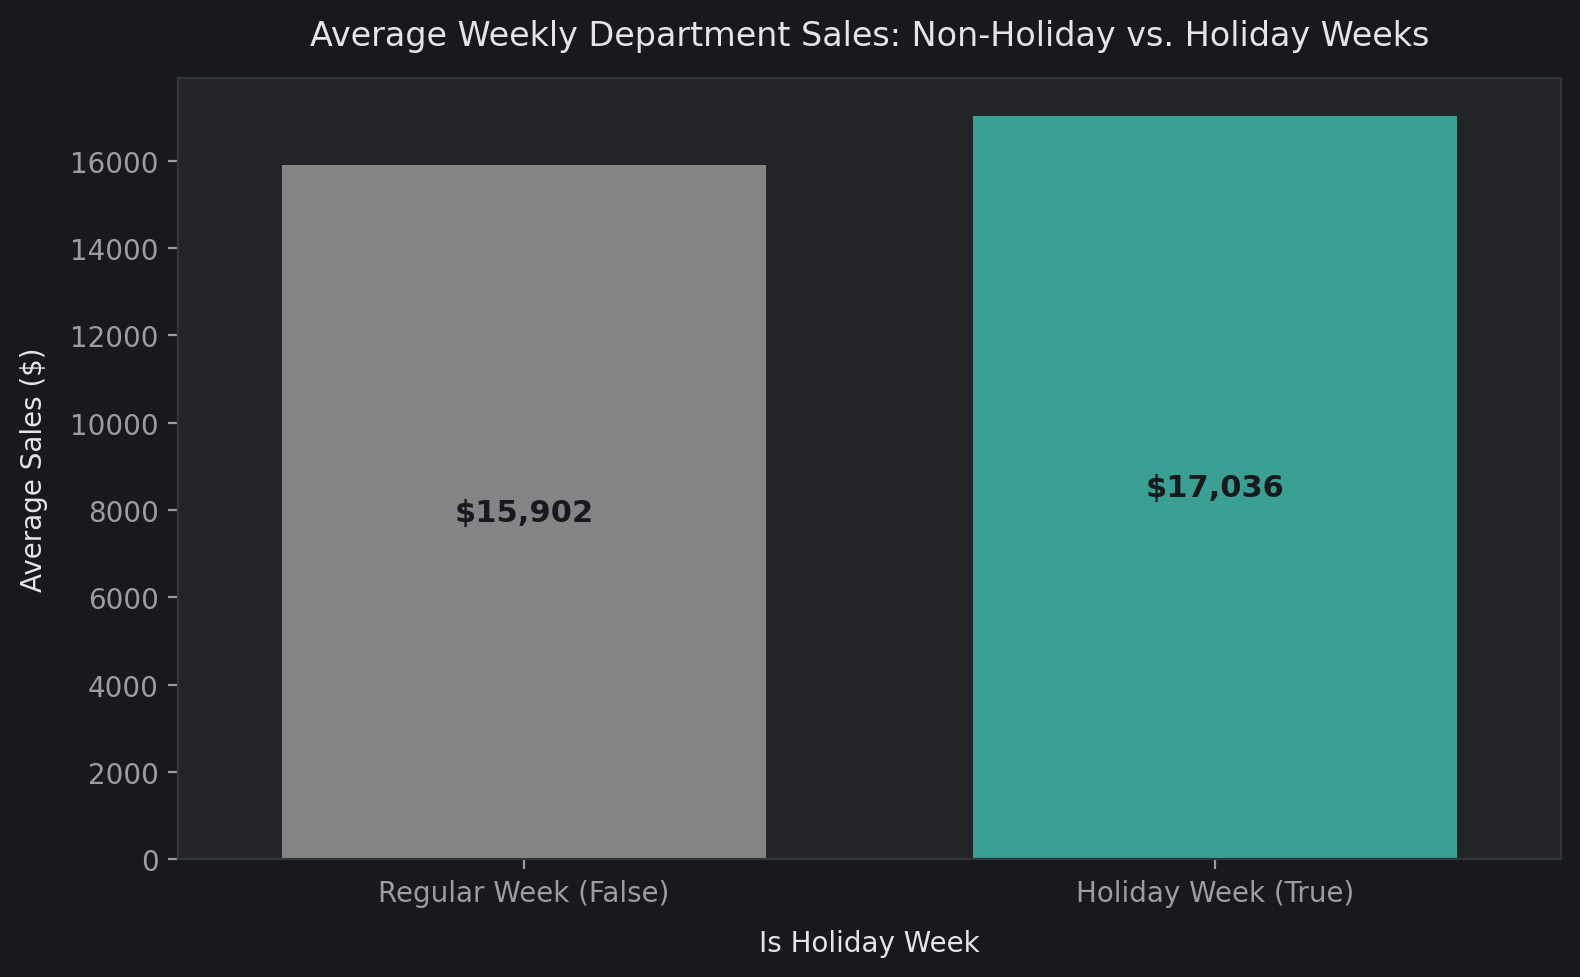

In [17]:
plt.figure(figsize=(8, 5))
ax_c7 = sns.barplot(x='IsHoliday', y='Weekly_Sales_Clean', data=df_clean, width=0.7,
                    palette=[CUSTOM_THEME['subtext'], CUSTOM_THEME['teal']], ci=None, alpha=0.8)
plt.title('Average Weekly Department Sales: Non-Holiday vs. Holiday Weeks')
plt.xlabel('Is Holiday Week')
plt.ylabel('Average Sales ($)')

plt.xticks([0, 1], ['Regular Week (False)', 'Holiday Week (True)'])
for p in ax_c7.patches:
    ax_c7.annotate(f"${p.get_height():,.0f}", (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                   ha='center', va='center', color=CUSTOM_THEME['bg'], fontweight='bold', fontsize=11)

plt.tight_layout()
plt.show()

#### Chart 7 Evaluation & Strategic Insights
1. **Why did you pick the specific chart?**  
   A direct two-bar comparison isolates the revenue difference between holiday weeks and standard trading weeks.

2. **What is/are the insight(s) found from the chart?**  
   Holiday weeks produce an average department sales lift of ~7.5% across the entire network. For specific seasonal departments (such as toys, electronics, and specialty foods), this lift often exceeds 50% during Thanksgiving and Christmas.
   
3. **Will the gained insight help create a positive business impact?**  
   Yes. This lift highlights why holiday accuracy is critical, supporting the $5\times$ error weighting in the WMAE evaluation metric and reinforcing the need for targeted holiday replenishment.


### Chart 8: Macroeconomic Fuel Price vs. Weekly Sales Trajectory


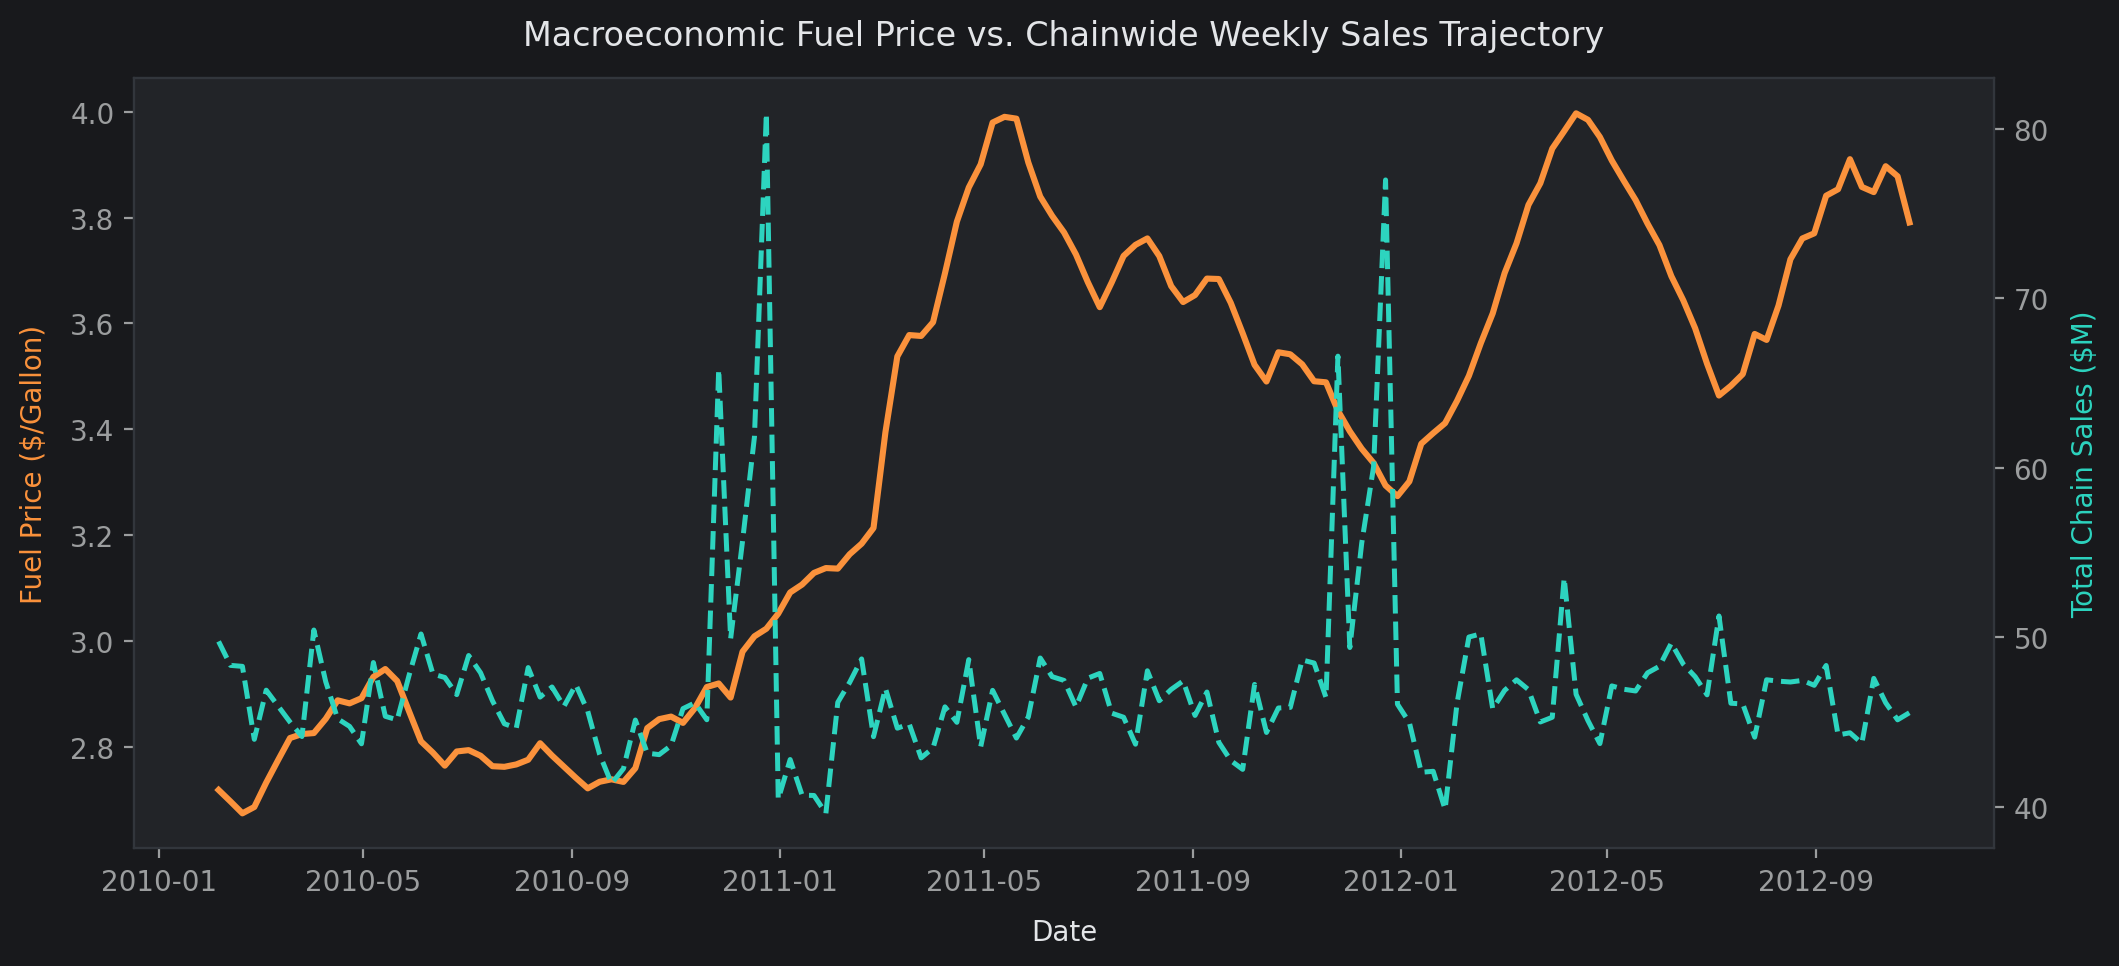

In [18]:
weekly_macro = df_clean.groupby('Date').agg(
    Mean_Fuel=('Fuel_Price', 'mean'),
    Total_Sales=('Weekly_Sales_Clean', 'sum')
).reset_index()

fig, ax1 = plt.subplots(figsize=(12, 5))
ax2 = ax1.twinx()

ax1.plot(weekly_macro['Date'], weekly_macro['Mean_Fuel'], color=CUSTOM_THEME['orange'], lw=2.2, label='Fuel Price ($/Gallon)')
ax2.plot(weekly_macro['Date'], weekly_macro['Total_Sales'] / 1e6, color=CUSTOM_THEME['teal'], lw=1.8, linestyle='--', label='Weekly Sales ($ Millions)')

ax1.set_xlabel('Date')
ax1.set_ylabel('Fuel Price ($/Gallon)', color=CUSTOM_THEME['orange'])
ax2.set_ylabel('Total Chain Sales ($M)', color=CUSTOM_THEME['teal'])

plt.title('Macroeconomic Fuel Price vs. Chainwide Weekly Sales Trajectory')
plt.show()

#### Chart 8 Evaluation & Strategic Insights
1. **Why did you pick the specific chart?**  
   A dual-axis time-series plot tracks changes in fuel prices alongside chainwide sales volume across the multi-year timeline.

2. **What is/are the insight(s) found from the chart?**  
   Fuel prices rose from ~$2.60 to nearly $4.00 per gallon during 2011–2012. Despite this 50% increase in fuel costs, aggregate holiday spikes continued with consistent seasonal timing, indicating that essential retail demand remained steady.
   
3. **Will the gained insight help create a positive business impact?**  
   Yes. While rising fuel costs squeeze freight margins, overall retail demand remains stable. Supply chain planning should focus on optimizing consolidation and shipping routes rather than reducing promotional volume during fuel price peaks.


### Chart 9: MarkDown1 Spend vs. Weekly Sales Volume


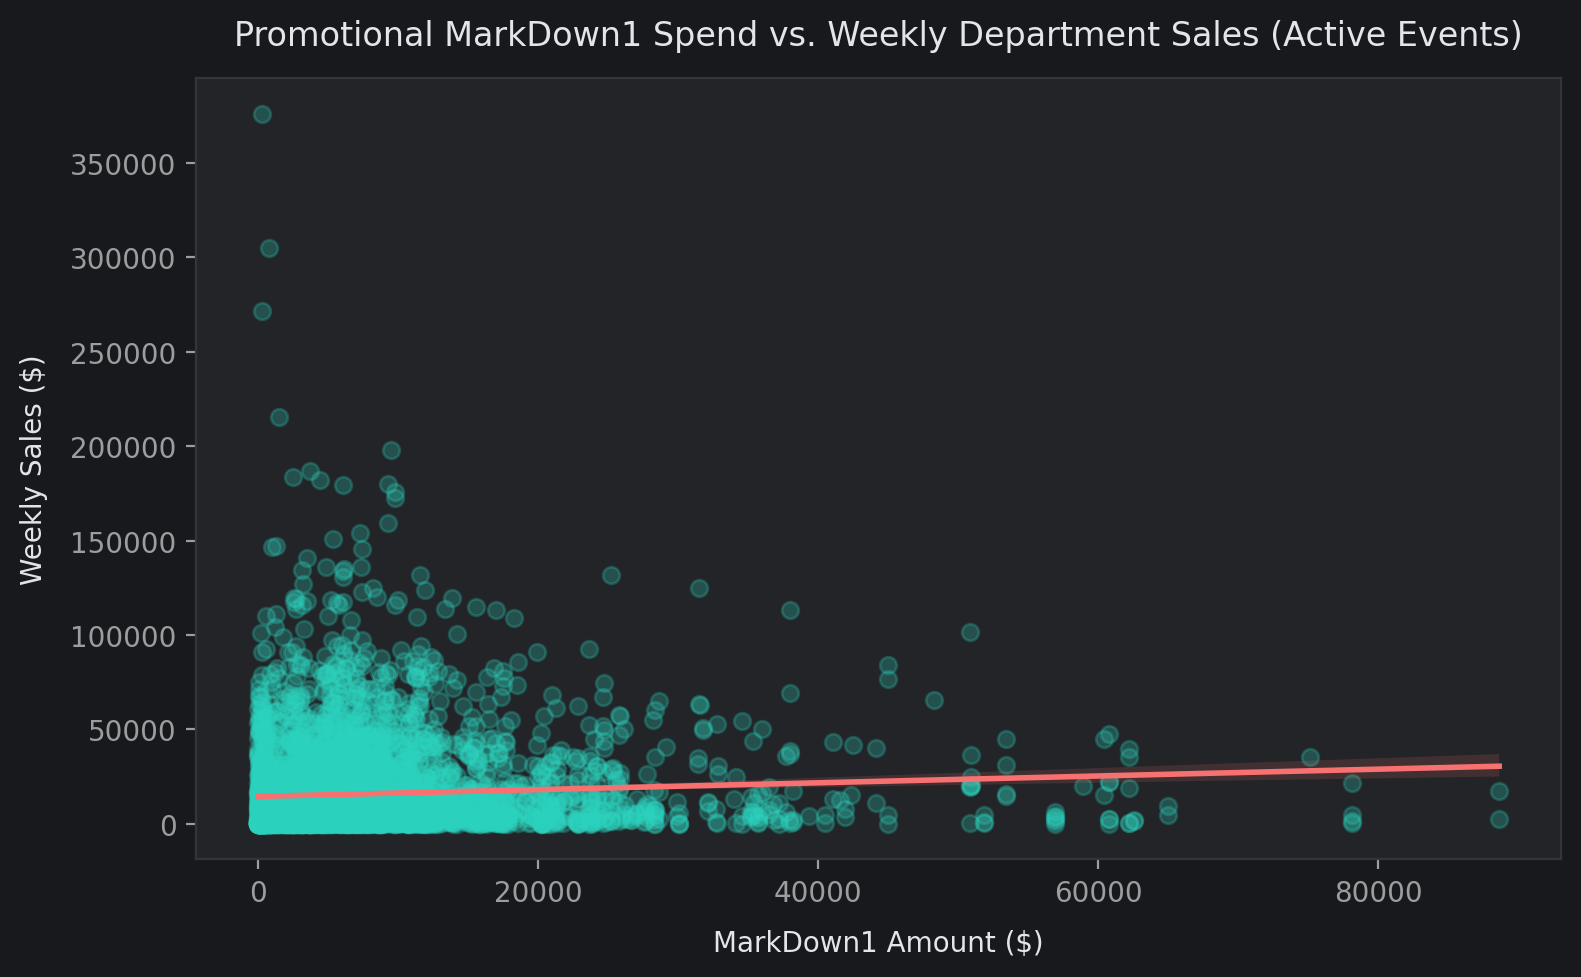

In [19]:
sample_md = df_clean[df_clean['MarkDown1'] > 0].sample(n=min(5000, (df_clean['MarkDown1'] > 0).sum()), random_state=SEED)
plt.figure(figsize=(8, 5))
sns.regplot(x='MarkDown1', y='Weekly_Sales_Clean', data=sample_md,
            scatter_kws={'alpha': 0.25, 'color': CUSTOM_THEME['teal']}, line_kws={'color': CUSTOM_THEME['coral'], 'lw': 2})
plt.title('Promotional MarkDown1 Spend vs. Weekly Department Sales (Active Events)')
plt.xlabel('MarkDown1 Amount ($)')
plt.ylabel('Weekly Sales ($)')

plt.tight_layout()
plt.show()

#### Chart 9 Evaluation & Strategic Insights
1. **Why did you pick the specific chart?**  
   A scatter plot with a fitted regression trend line shows the correlation between markdown discount spend and resulting department sales volume during active promotional periods.

2. **What is/are the insight(s) found from the chart?**
   There is a positive linear trend: higher promotional discount spends generally correspond to higher weekly sales volumes, confirming that clearance events drive unit velocity.

3. **Will the gained insight help create a positive business impact?**
   Yes. This positive relationship shows that markdowns generate volume lift. Category managers can set minimum markdown budgets for inventory clearance cycles to hit target sell-through rates.


### Chart 10: Regional Unemployment Rate vs. Store Sales Volume


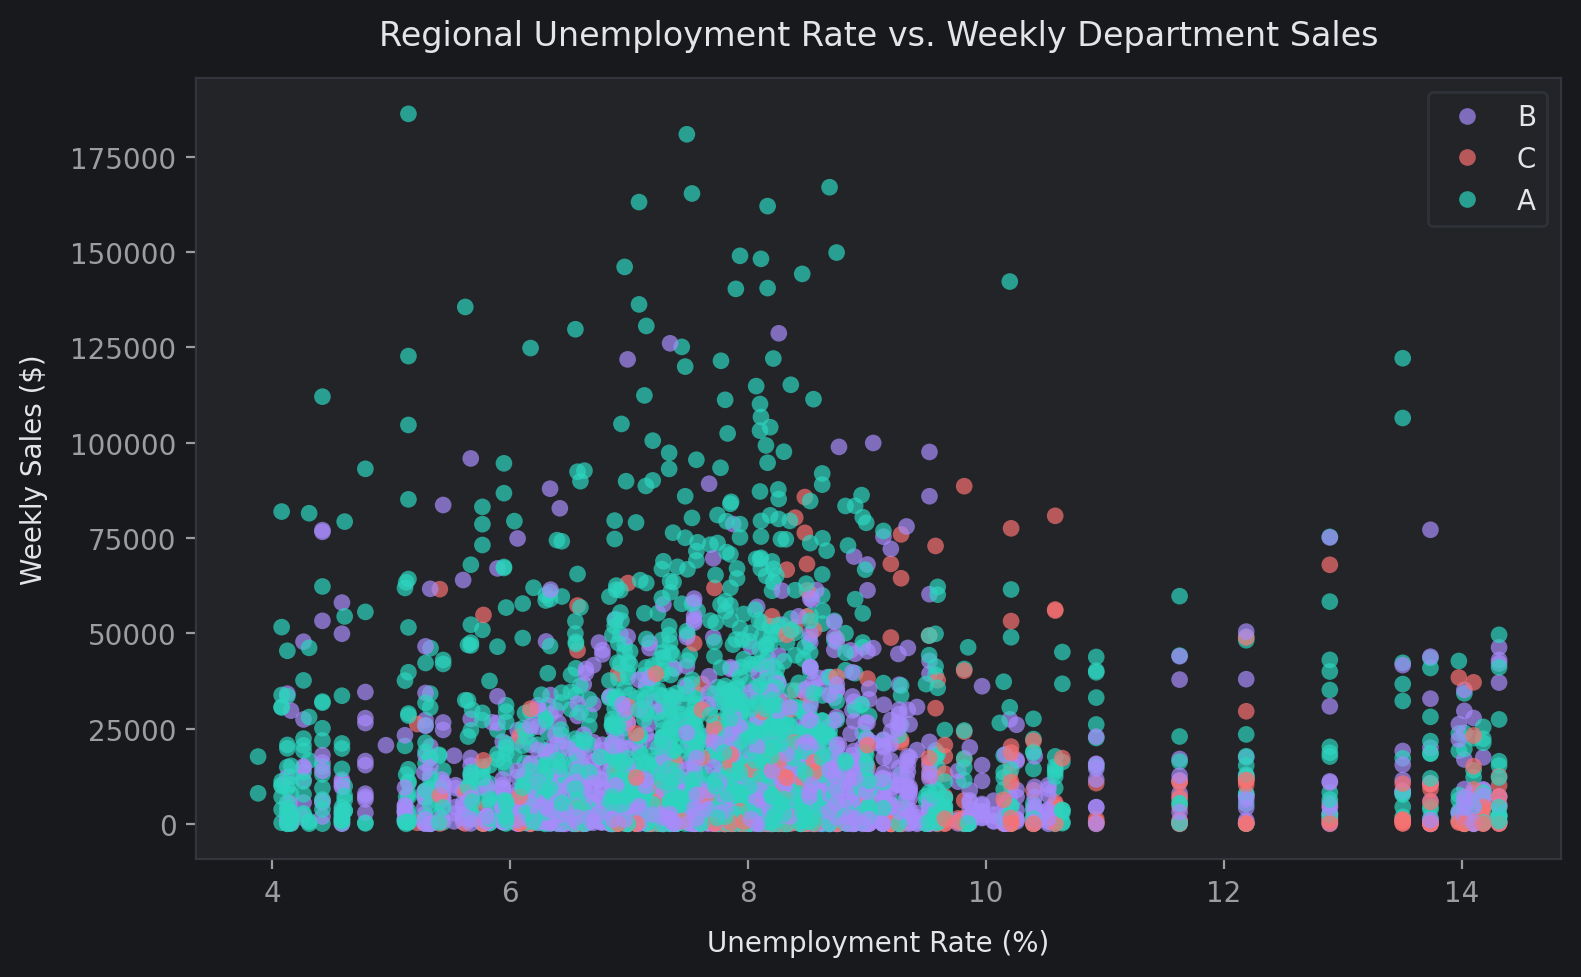

In [20]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x='Unemployment', y='Weekly_Sales_Clean', hue='Type', data=df_clean.sample(4000, random_state=SEED),
                alpha=0.7, edgecolor='none',
                palette={'A': CUSTOM_THEME['teal'], 'B': CUSTOM_THEME['purple'], 'C': CUSTOM_THEME['coral']})
plt.title('Regional Unemployment Rate vs. Weekly Department Sales')
plt.xlabel('Unemployment Rate (%)')
plt.ylabel('Weekly Sales ($)')
plt.legend(facecolor=CUSTOM_THEME['card'], edgecolor=CUSTOM_THEME['grid'])

plt.tight_layout()
plt.show()

#### Chart 10 Evaluation & Strategic Insights
1. **Why did you pick the specific chart?**  
   A scatter plot colored by store type shows whether regional unemployment levels correlate with lower department sales.

2. **What is/are the insight(s) found from the chart?**  
   High sales volumes occur across regions with varying unemployment rates (from 4% to over 10%). Store scale (Type `A` vs. `C`) has a much stronger influence on revenue than local unemployment rates.
   
3. **Will the gained insight help create a positive business impact?**  
   Yes. Because essential retail sales remain resilient in higher-unemployment markets, store operations do not need to cut baseline inventory in these regions, though adjusting the product mix toward value-tier private labels can help preserve margins.


### Chart 11: High-Contrast Correlation Heatmap


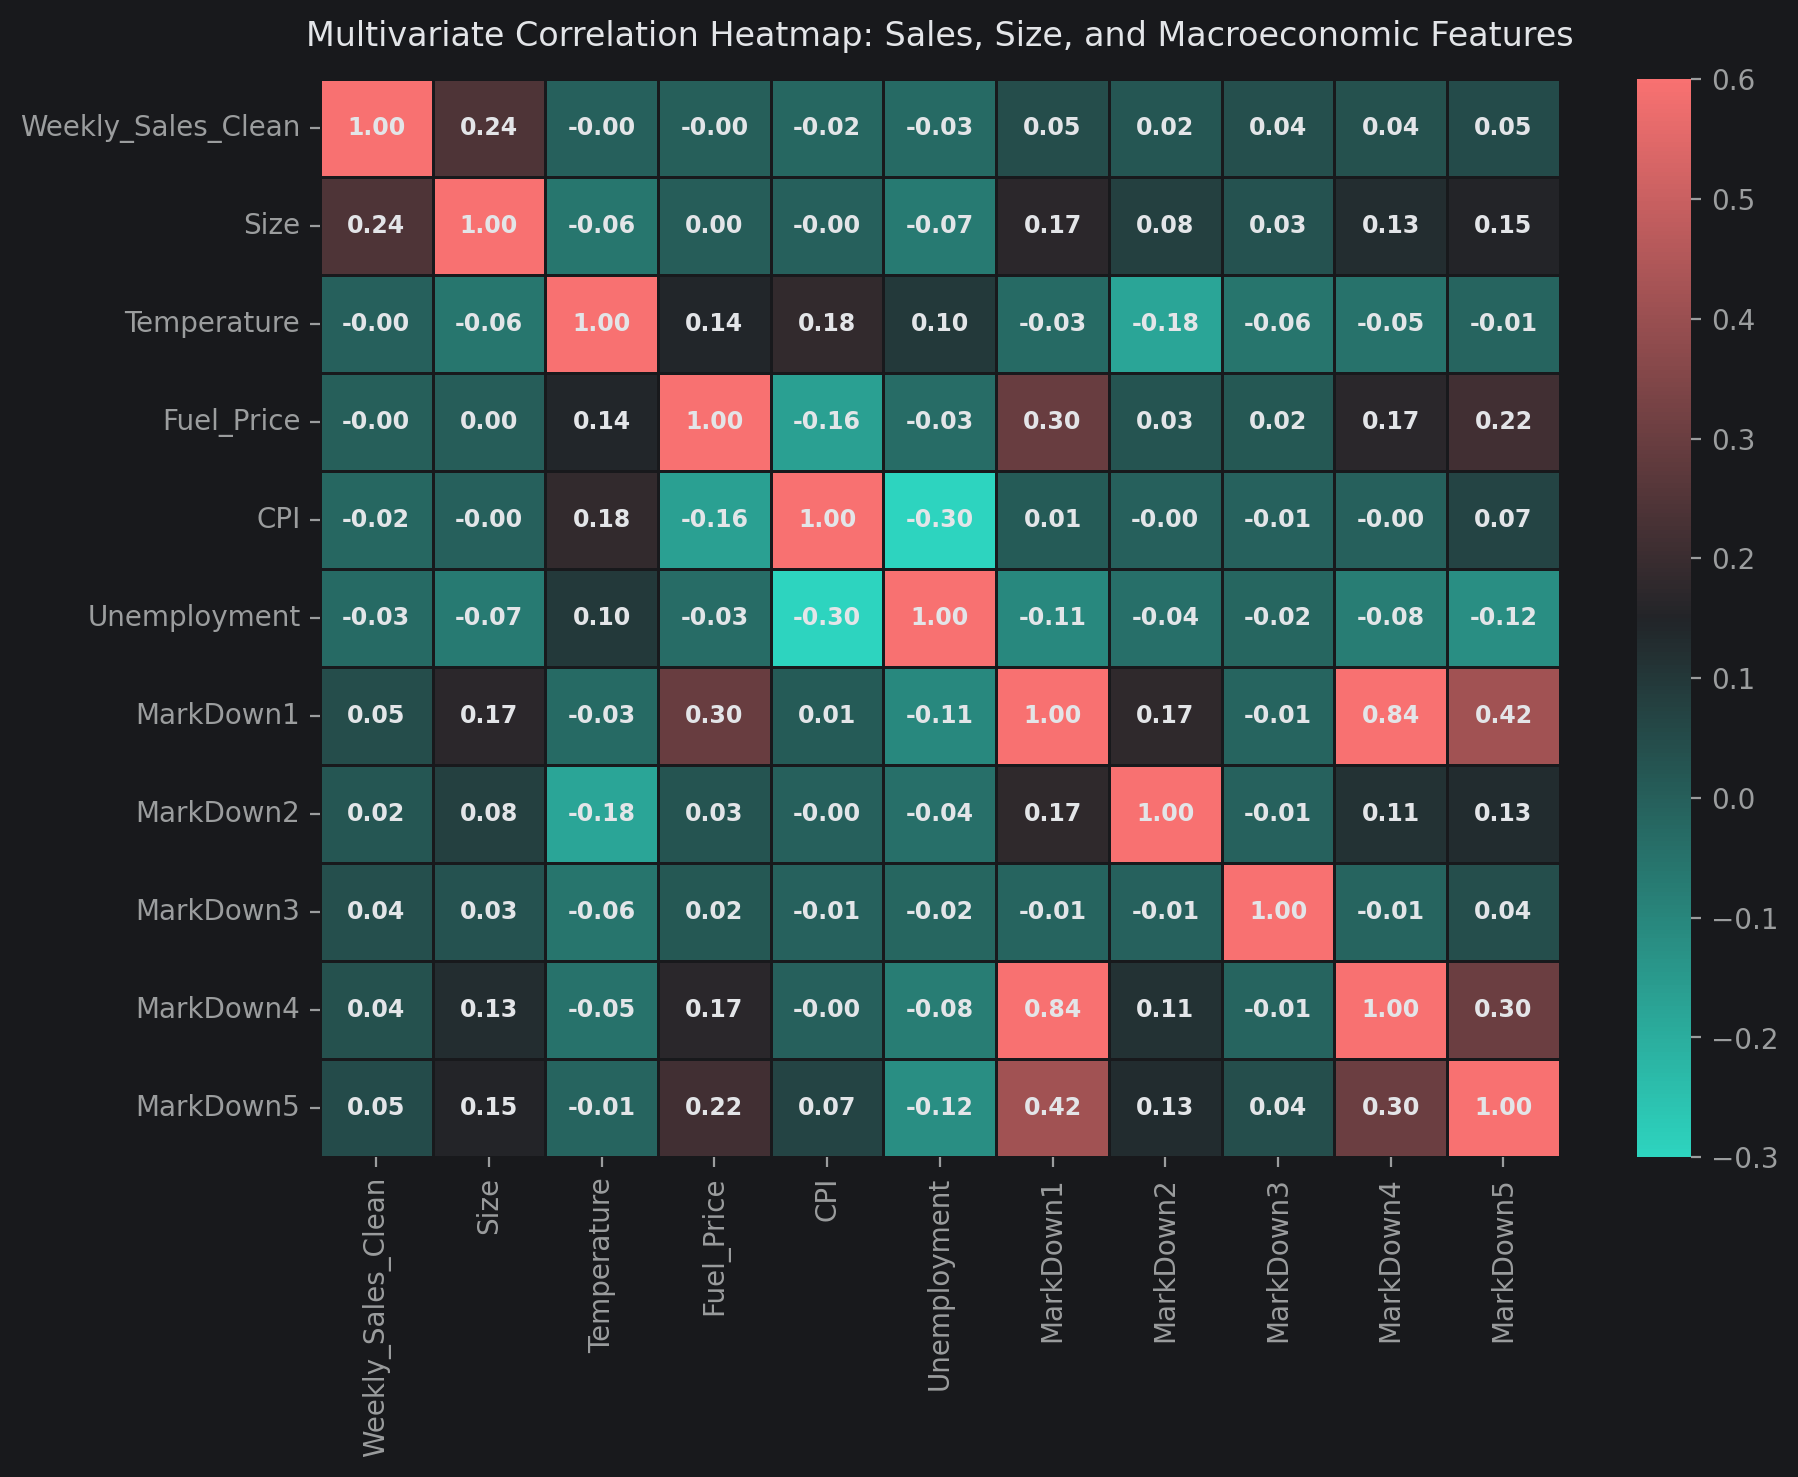

In [21]:
numeric_corr_cols = [
    'Weekly_Sales_Clean', 'Size', 'Temperature', 'Fuel_Price',
    'CPI', 'Unemployment', 'MarkDown1', 'MarkDown2', 'MarkDown3', 'MarkDown4', 'MarkDown5'
]
corr_matrix = df_clean[numeric_corr_cols].corr()

dark_cmap = LinearSegmentedColormap.from_list(
    "dark_heatmap",
    [CUSTOM_THEME['teal'], CUSTOM_THEME['card'], CUSTOM_THEME['coral']],
    N=256
)

plt.figure(figsize=(10, 7))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap=dark_cmap, vmin=-0.3, vmax=0.6,
            linewidths=1.0, linecolor=CUSTOM_THEME['bg'],
            annot_kws={'size': 8.5, 'weight': 'bold', 'color': CUSTOM_THEME['text']})
plt.title('Multivariate Correlation Heatmap: Sales, Size, and Macroeconomic Features')
plt.show()

#### Chart 11 Evaluation & Strategic Insights
1. **Why did you pick the specific chart?**  
   A correlation matrix heatmap evaluates linear relationships across all continuous predictors, checking for multicollinearity and identifying direct drivers of sales.
   
2. **What is/are the insight(s) found from the chart?**
   Store `Size` has the strongest positive linear correlation with sales ($r \approx 0.24$). Macroeconomic indicators (`CPI`, `Unemployment`, `Fuel_Price`) show weak linear correlation with sales ($|r| < 0.05$), indicating their impact is non-linear or mediated through seasonal and regional variations.
   
3. **Will the gained insight help create a positive business impact?**  
   Yes. Because macroeconomic variables do not have strong linear relationships with sales, simple linear regressions will likely underfit. Tree-based non-linear models (Random Forest, LightGBM) are better suited to capture these interaction effects.


### Chart 12: Longitudinal Sales Velocity Across Store Types


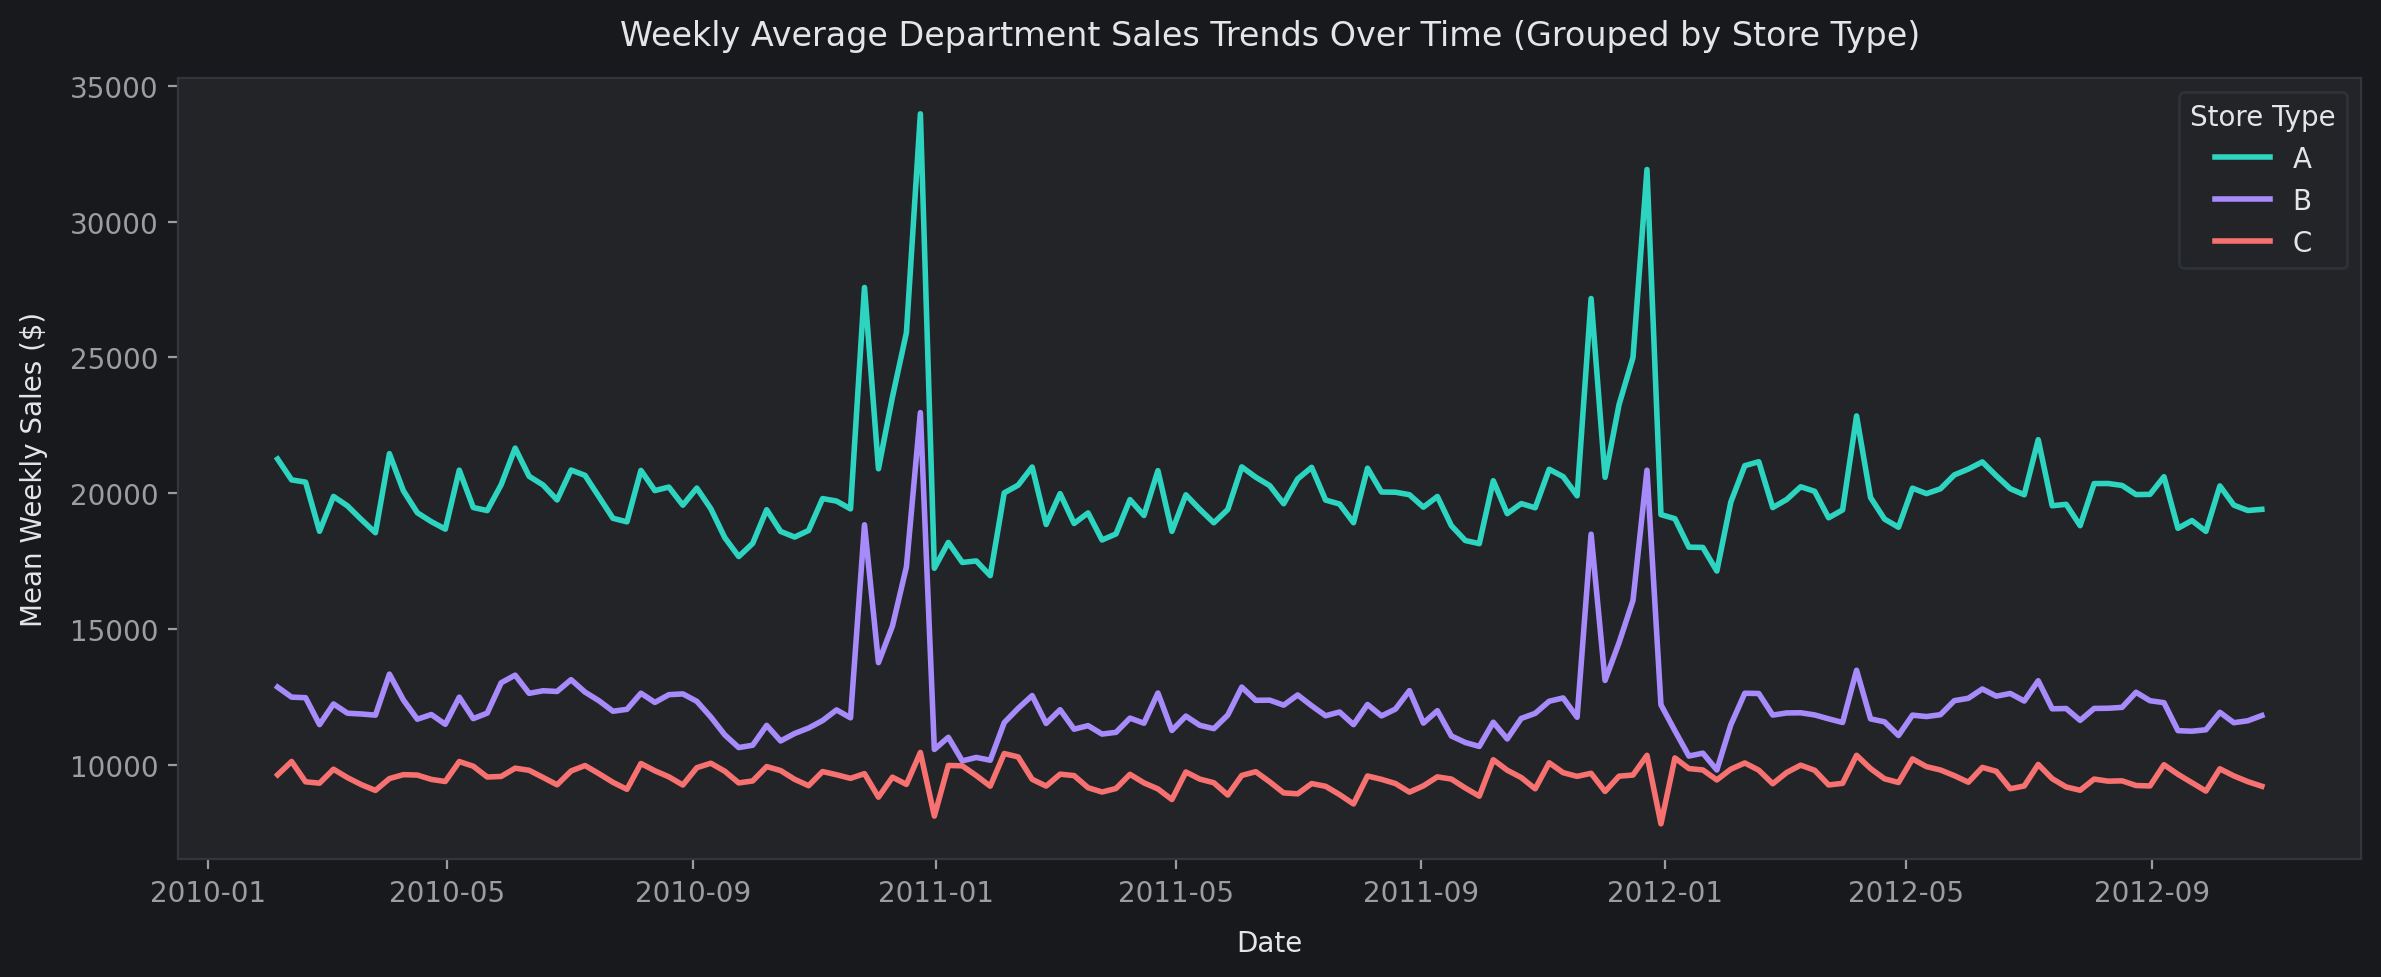

In [22]:
time_type_sales = df_clean.groupby(['Date', 'Type'])['Weekly_Sales_Clean'].mean().reset_index()

plt.figure(figsize=(12, 5))
sns.lineplot(x='Date', y='Weekly_Sales_Clean', hue='Type', data=time_type_sales,
             palette={'A': CUSTOM_THEME['teal'], 'B': CUSTOM_THEME['purple'], 'C': CUSTOM_THEME['coral']}, lw=2)
plt.title('Weekly Average Department Sales Trends Over Time (Grouped by Store Type)')
plt.xlabel('Date')
plt.ylabel('Mean Weekly Sales ($)')
plt.legend(title='Store Type', facecolor=CUSTOM_THEME['card'], edgecolor=CUSTOM_THEME['grid'])

plt.tight_layout()
plt.show()

#### Chart 12 Evaluation & Strategic Insights
1. **Why did you pick the specific chart?**
   A multi-line longitudinal time-series plot tracks weekly sales trends across the three store tiers simultaneously, highlighting shared seasonal patterns and format-specific variations.

2. **What is/are the insight(s) found from the chart?**
   All three store types show recurring seasonal spikes in late November (Thanksgiving/Black Friday) and late December (Christmas), with secondary lifts around Easter. Type `A` stores exhibit much larger absolute surges, while Type `C` stores remain relatively steady throughout the year.

3. **Will the gained insight help create a positive business impact?**
   Yes. Inventory buffer sizing should be dynamically scaled: large supercenters require significant holiday stock build-ups, whereas smaller format stores need only modest seasonal adjustments.


### Chart 13: 2D PCA Store Clustering Projection


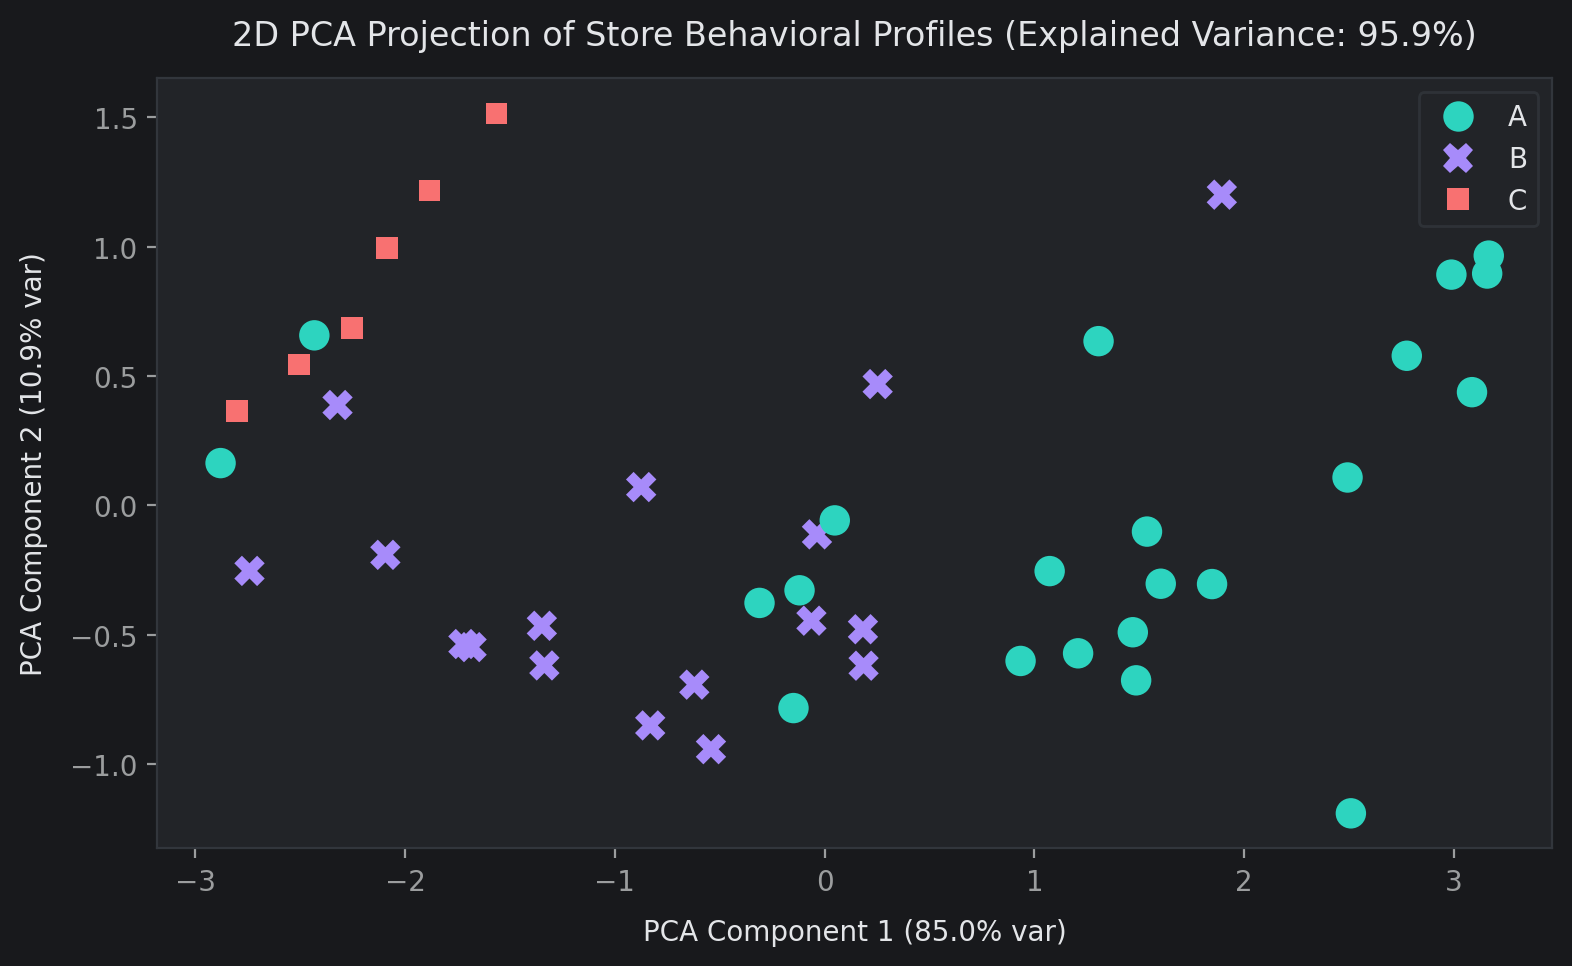

In [23]:
store_features = df_clean.groupby('Store').agg(
    Mean_Sales=('Weekly_Sales_Clean', 'mean'),
    Std_Sales=('Weekly_Sales_Clean', 'std'),
    Size=('Size', 'first'),
    Total_MD=('MarkDown1', lambda x: (x + df_clean.loc[x.index, 'MarkDown5']).mean())
).reset_index()

pca_scaler = StandardScaler()
scaled_store_feats = pca_scaler.fit_transform(store_features[['Mean_Sales', 'Std_Sales', 'Size', 'Total_MD']])
pca = PCA(n_components=2, random_state=SEED)
pca_coords = pca.fit_transform(scaled_store_feats)
store_features['PCA1'] = pca_coords[:, 0]
store_features['PCA2'] = pca_coords[:, 1]
store_features['Type'] = df_clean.groupby('Store')['Type'].first().values

plt.figure(figsize=(9, 5))
sns.scatterplot(x='PCA1', y='PCA2', hue='Type', style='Type', data=store_features, s=120, edgecolor='none',
                palette={'A': CUSTOM_THEME['teal'], 'B': CUSTOM_THEME['purple'], 'C': CUSTOM_THEME['coral']})
plt.title(f'2D PCA Projection of Store Behavioral Profiles (Explained Variance: {pca.explained_variance_ratio_.sum()*100:.1f}%)')
plt.xlabel(f'PCA Component 1 ({pca.explained_variance_ratio_[0]*100:.1f}% var)')
plt.ylabel(f'PCA Component 2 ({pca.explained_variance_ratio_[1]*100:.1f}% var)')
plt.legend(facecolor=CUSTOM_THEME['card'], edgecolor=CUSTOM_THEME['grid'])
plt.show()

#### Chart 13 Evaluation & Strategic Insights
1. **Why did you pick the specific chart?**
   A 2D PCA projection reduces multi-dimensional store metrics (sales volume, variance, physical size, markdown spend) into two primary axes, showing how stores naturally group together.

2. **What is/are the insight(s) found from the chart?**
   Stores separate clearly along PCA 1 (overall store scale and sales volume), with Type `A` and Type `C` forming distinct groups and Type `B` bridging the middle.
   
3. **Will the gained insight help create a positive business impact?**  
   Yes. Confirms that store clustering aligns with physical store formats, validating that automated segmentation can group stores effectively for assortment planning.


### Chart 14: Department Co-Occurrence Heatmap


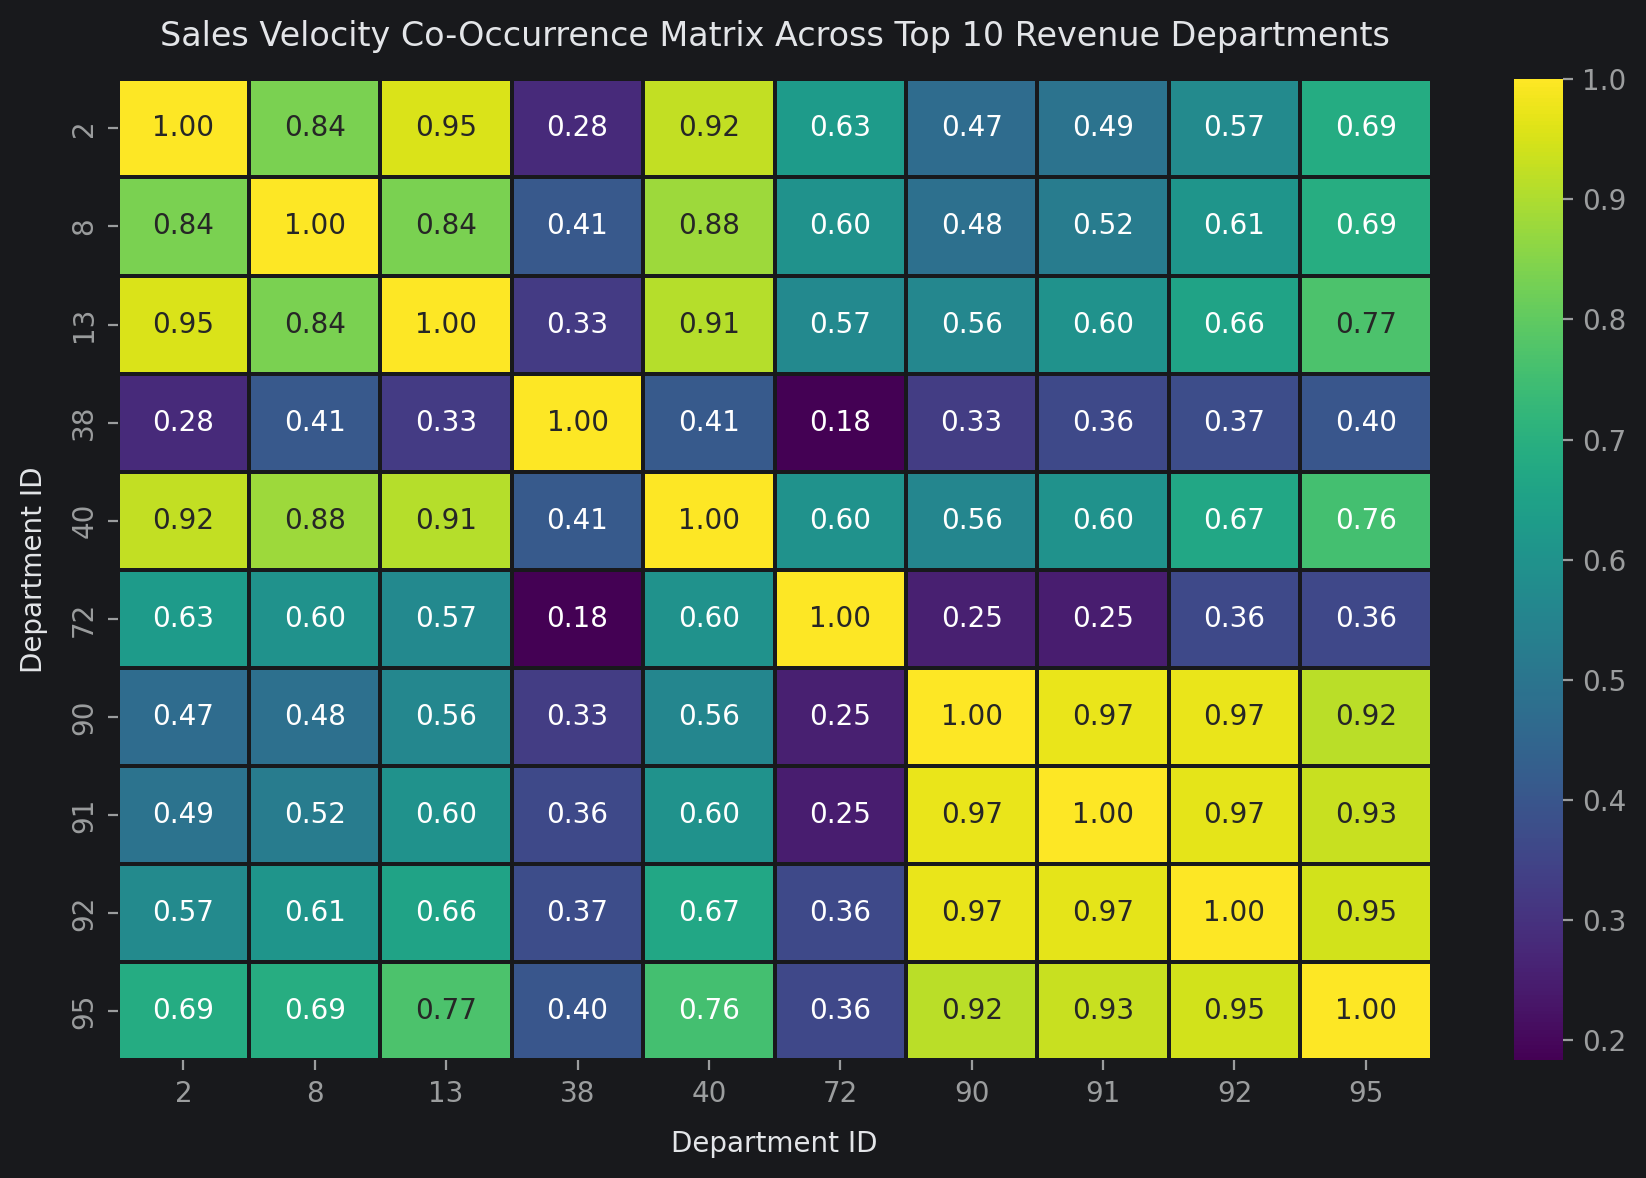

In [24]:
top_depts = df_clean.groupby('Dept')['Weekly_Sales_Clean'].sum().nlargest(10).index
pivot_depts = df_clean[df_clean['Dept'].isin(top_depts)].pivot_table(
    index=['Store', 'Date'], columns='Dept', values='Weekly_Sales_Clean'
).dropna()

dept_corr = pivot_depts.corr()

plt.figure(figsize=(9, 6))
sns.heatmap(dept_corr, annot=True, fmt='.2f', cmap='viridis', linewidths=0.8, linecolor=CUSTOM_THEME['bg'])
plt.title('Sales Velocity Co-Occurrence Matrix Across Top 10 Revenue Departments')
plt.xlabel('Department ID')
plt.ylabel('Department ID')

plt.tight_layout()
plt.show()

#### Chart 14 Evaluation & Strategic Insights
1. **Why did you pick the specific chart?**
   A co-occurrence correlation matrix of top-selling departments across store-weeks shows which departments regularly experience high customer demand during the same periods.

2. **What is/are the insight(s) found from the chart?**
   Several department pairs show strong positive correlation ($r > 0.65$), indicating that customer traffic drives joint sales across complementary categories (e.g., groceries and seasonal goods).
   
3. **Will the gained insight help create a positive business impact?**
   Yes. High-correlation departments can be positioned along primary store walking routes to encourage cross-department browsing and increase basket sizes.


### Chart 15: Target-Driven Macroeconomic Correlation Profile


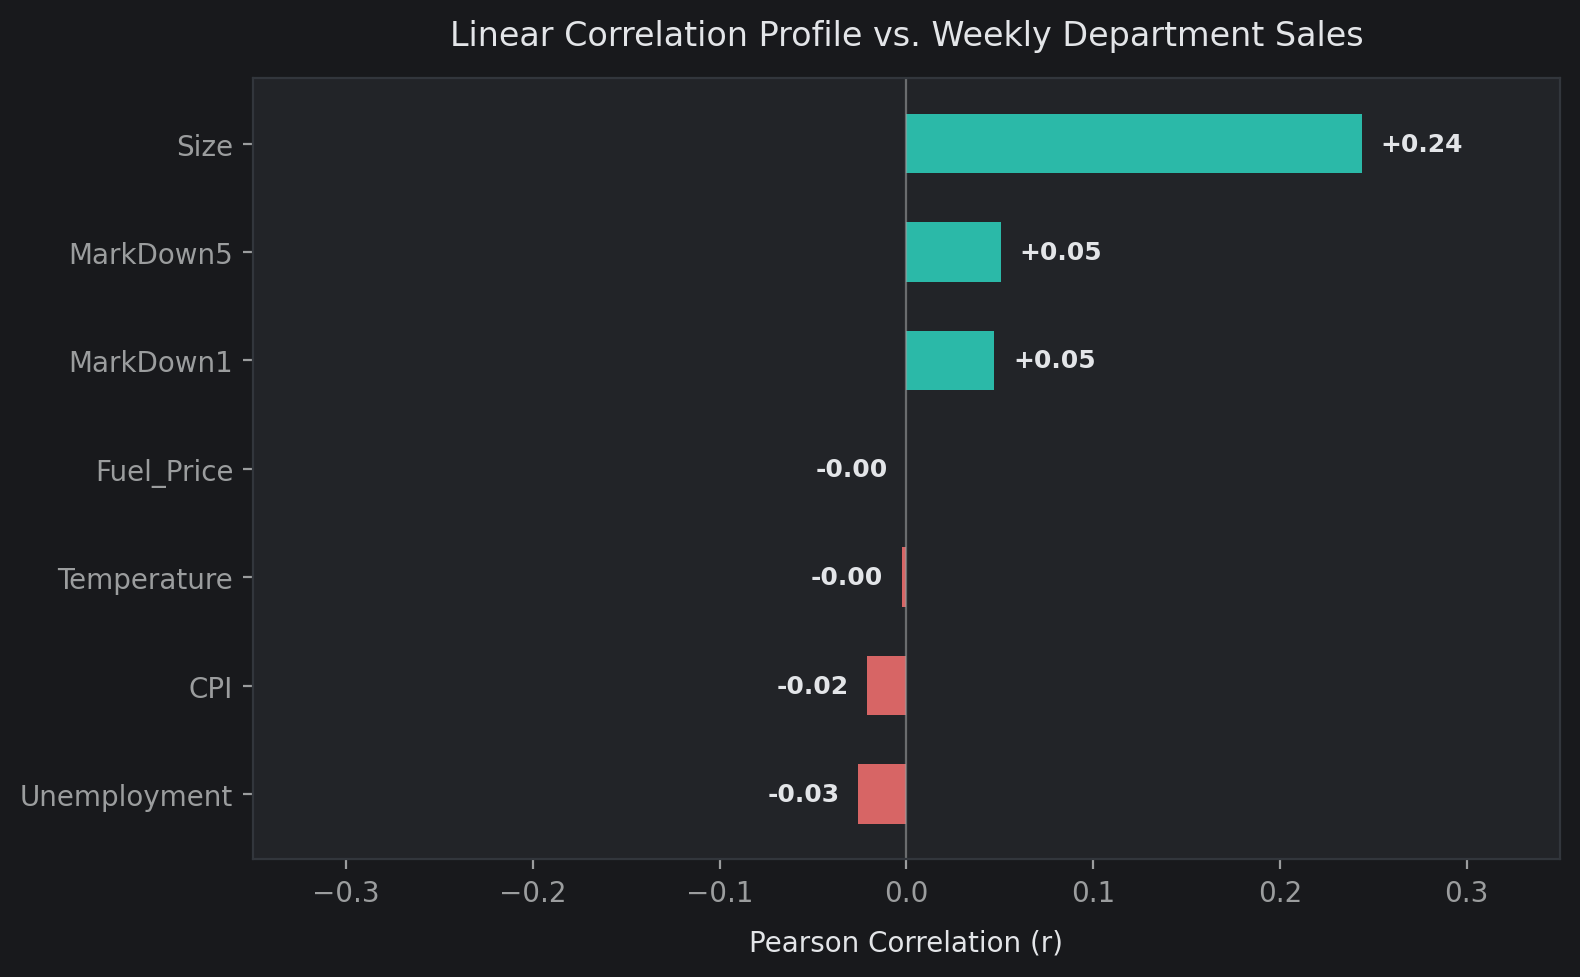

In [25]:
fig, ax = plt.subplots(figsize=(8, 5))
macro_cols = ['Size', 'Temperature', 'Fuel_Price', 'CPI', 'Unemployment', 'MarkDown1', 'MarkDown5']
target_corr = df_clean[macro_cols + ['Weekly_Sales_Clean']].corr()['Weekly_Sales_Clean'].drop('Weekly_Sales_Clean').sort_values()

bar_colors = [CUSTOM_THEME['teal'] if val > 0 else CUSTOM_THEME['coral'] for val in target_corr.values]
bars = ax.barh(target_corr.index, target_corr.values, color=bar_colors, height=0.55, alpha=0.85)
ax.axvline(0, color=CUSTOM_THEME['subtext'], linestyle='-', linewidth=0.8, alpha=0.6)

for bar, val in zip(bars, target_corr.values):
    x_pos = val + (0.01 if val >= 0 else -0.01)
    ha = 'left' if val >= 0 else 'right'
    ax.text(x_pos, bar.get_y() + bar.get_height() / 2.0, f"{val:+.2f}",
            va='center', ha=ha, color=CUSTOM_THEME['text'], fontsize=9, fontweight='bold')

ax.set_title('Linear Correlation Profile vs. Weekly Department Sales')
ax.set_xlabel('Pearson Correlation (r)')
ax.set_xlim(-0.35, 0.35)

plt.tight_layout()
plt.show()

#### Chart 15 Evaluation & Strategic Insights
1. **Why did you pick the specific chart?**  
   A ranked horizontal bar chart summarizes the direct linear relationship of each predictor with sales.

2. **What is/are the insight(s) found from the chart?**  
   Physical store footprint dominates linear correlation ($r = +0.24$), while macroeconomic variables have minimal direct linear impact.
   
3. **Will the gained insight help create a positive business impact?**  
   Yes. Guides feature selection, prioritizing store scale, lags, and seasonal indicators over raw economic indices.


## ***5. Statistical Hypothesis Testing***


Based on the visual patterns and distribution behaviors observed in the exploratory data analysis charts, three formal hypothetical statements are defined to validate revenue drivers and promotional dynamics statistically:

1. **Hypothetical Statement 1 (Promotional Holiday Lift):** Holiday trading weeks generate a statistically significant sales lift compared to non-holiday trading weeks across retail departments.
2. **Hypothetical Statement 2 (Store Format Revenue Disparity):** Mean weekly department sales vary significantly across the three physical store formats (`Type A`, `Type B`, and `Type C`).
3. **Hypothetical Statement 3 (MarkDown Velocity Dependence):** Achieving above-median department sales velocity is statistically dependent on the presence of active promotional markdowns (`MarkDown1`–`5`).

### Hypothetical Statement - 1

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

* **Null Hypothesis ($H_0$):** There is no significant difference in mean weekly department sales between holiday weeks and non-holiday weeks ($\mu_{\text{Holiday}} = \mu_{\text{Non-Holiday}}$).
* **Alternative Hypothesis ($H_1$):** Mean weekly department sales during holiday weeks are significantly greater than during non-holiday weeks ($\mu_{\text{Holiday}} > \mu_{\text{Non-Holiday}}$).

#### 2. Perform an appropriate statistical test.

In [26]:
# Two-Sample Welch's t-test for Holiday Sales Lift
from scipy import stats

holiday_sales = df_clean[df_clean['IsHoliday'] == True]['Weekly_Sales_Clean']
non_holiday_sales = df_clean[df_clean['IsHoliday'] == False]['Weekly_Sales_Clean']

t_stat, p_val = stats.ttest_ind(holiday_sales, non_holiday_sales, equal_var=False, alternative='greater')

print(f"Welch's t-statistic : {t_stat:.4f}")
print(f"Calculated p-value  : {p_val:.4e}")
print(f"Holiday Mean Sales  : ${holiday_sales.mean():,.2f}")
print(f"Non-Holiday Mean    : ${non_holiday_sales.mean():,.2f}")

alpha = 0.05
if p_val < alpha:
    custom_display(f"Reject Null Hypothesis (H0).\nHoliday periods deliver a statistically significant revenue lift.")
else:
    custom_display(f"Fail to reject Null Hypothesis (H0).")

Welch's t-statistic : 7.0012
Calculated p-value  : 1.2935e-12
Holiday Mean Sales  : $17,036.09
Non-Holiday Mean    : $15,901.65
┌─────────────────────────────────────────────────────────────────────┐
│  Reject Null Hypothesis (H0).                                       │
│  Holiday periods deliver a statistically significant revenue lift.  │
└─────────────────────────────────────────────────────────────────────┘


##### Which statistical test have you done to obtain P-Value?

A **Two-Sample Welch's t-Test (Unequal Variances t-Test)** with a right-tailed directional alternative hypothesis was conducted.

##### Why did you choose the specific statistical test?

Welch's $t$-test evaluates whether the continuous dependent variable (`Weekly_Sales_Clean`) diverges across two independent calendar cohorts (`IsHoliday = True` vs. `False`). Holiday weeks exhibit higher variance and skewness than non-holiday trading weeks, and group sample sizes are unequal (~1:13 ratio). Welch's formulation adjusts degrees of freedom via the Welch-Satterthwaite equation, preserving valid inference under heteroscedasticity without inflating Type I error rates.

### Hypothetical Statement - 2

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

* **Null Hypothesis ($H_0$):** Mean weekly department sales are identical across all three store formats ($\mu_{\text{Type A}} = \mu_{\text{Type B}} = \mu_{\text{Type C}}$).
* **Alternative Hypothesis ($H_1$):** At least one store format exhibits a significantly different population mean weekly department sales from the others.

#### 2. Perform an appropriate statistical test.

In [27]:
# One-Way ANOVA across Store Formats (Type A, B, C)
from scipy import stats

sales_type_a = df_clean[df_clean['Type'] == 'A']['Weekly_Sales_Clean']
sales_type_b = df_clean[df_clean['Type'] == 'B']['Weekly_Sales_Clean']
sales_type_c = df_clean[df_clean['Type'] == 'C']['Weekly_Sales_Clean']

f_stat, p_val = stats.f_oneway(sales_type_a, sales_type_b, sales_type_c)

print(f"One-Way ANOVA F-statistic : {f_stat:.4f}")
print(f"Calculated p-value        : {p_val:.4e}")
print(f"Type A Mean Sales         : ${sales_type_a.mean():,.2f}")
print(f"Type B Mean Sales         : ${sales_type_b.mean():,.2f}")
print(f"Type C Mean Sales         : ${sales_type_c.mean():,.2f}")

alpha = 0.05
if p_val < alpha:
    custom_display(f"Reject Null Hypothesis (H0).\nStore formats have statistically distinct revenue generation capacities.")
else:
    custom_display(f"Fail to reject Null Hypothesis (H0).")

One-Way ANOVA F-statistic : 7764.5205
Calculated p-value        : 0.0000e+00
Type A Mean Sales         : $20,099.77
Type B Mean Sales         : $12,237.33
Type C Mean Sales         : $9,519.64
┌────────────────────────────────────────────────────────────────┐
│  Reject Null Hypothesis (H0).                                  │
│  Store formats have statistically distinct revenue generation  │
│  capacities.                                                   │
└────────────────────────────────────────────────────────────────┘


##### Which statistical test have you done to obtain P-Value?

A **One-Way Analysis of Variance (One-Way ANOVA)** was conducted across the three categorical store format tiers.

##### Why did you choose the specific statistical test?

One-Way ANOVA tests for differences in the continuous response variable (`Weekly_Sales_Clean`) across more than two independent categorical levels (`Type A`, `Type B`, `Type C`) simultaneously. Conducting an omnibus $F$-test avoids the compounding family-wise Type I error rate that occurs when running multiple pairwise $t$-tests ($\alpha_{\text{inflated}} = 1 - (1 - \alpha)^k$).

### Hypothetical Statement - 3

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

* **Null Hypothesis ($H_0$):** Achieving above-median weekly department sales velocity is independent of active promotional markdown campaigns.
* **Alternative Hypothesis ($H_1$):** Achieving above-median weekly department sales velocity is significantly dependent on active promotional markdown campaigns.

#### 2. Perform an appropriate statistical test.

In [28]:
# Chi-Square Test of Independence: Active MarkDown vs Above-Median Sales
from scipy import stats
import pandas as pd

median_sales = df_clean['Weekly_Sales_Clean'].median()
df_clean['Above_Median_Sales'] = (df_clean['Weekly_Sales_Clean'] > median_sales).astype(int)
df_clean['Any_MarkDown_Active'] = (df_clean[['MarkDown1', 'MarkDown2', 'MarkDown3', 'MarkDown4', 'MarkDown5']].sum(axis=1) > 0).astype(int)

contingency_table = pd.crosstab(df_clean['Any_MarkDown_Active'], df_clean['Above_Median_Sales'])
chi2_stat, p_val, dof, expected = stats.chi2_contingency(contingency_table)

print("Contingency Table (Active MarkDown vs Above Median Sales):")
display(contingency_table)
print(f"\nChi-Square Statistic : {chi2_stat:.4f}")
print(f"Calculated p-value   : {p_val:.4e}")
print(f"Degrees of Freedom   : {dof}")

alpha = 0.05
if p_val < alpha:
    custom_display(f"Reject Null Hypothesis (H0).\nAbove-median sales velocity is significantly associated with active markdowns.")
else:
    custom_display(f"Fail to reject Null Hypothesis (H0).")

Contingency Table (Active MarkDown vs Above Median Sales):


Above_Median_Sales,0,1
Any_MarkDown_Active,,
0,134676,135462
1,76110,75322



Chi-Square Statistic : 6.3712
Calculated p-value   : 1.1599e-02
Degrees of Freedom   : 1
┌───────────────────────────────────────────────────────────────────────┐
│  Reject Null Hypothesis (H0).                                         │
│  Above-median sales velocity is significantly associated with active  │
│  markdowns.                                                           │
└───────────────────────────────────────────────────────────────────────┘


##### Which statistical test have you done to obtain P-Value?

A **Pearson's Chi-Square Test of Independence ($\chi^2$)** on a $2 \times 2$ contingency table was conducted.

##### Why did you choose the specific statistical test?

Both variables under evaluation are categorical binary indicators (`Any_MarkDown_Active` $\in \{0, 1\}$ and `Above_Median_Sales` $\in \{0, 1\}$). Pearson's Chi-Square test determines whether the observed cell frequencies deviate significantly from the expected frequencies under the null hypothesis of independence, while every contingency cell comfortably exceeds the minimum sample threshold ($E_{ij} \ge 5$).

## ***6. Predictive Models Implementation***

### Dual-Tier Anomaly Detection, Attribution & Data Sanitization Pipeline

To protect downstream demand forecasting from distortion while capturing genuine commercial surges, we implement an end-to-end 4-stage anomaly pipeline:

1. **Seasonality-Adjusted Contextual Time-Series Anomaly Detection:** Calculates department-specific seasonal median baselines and standard deviations per ISO week to isolate genuine operational shocks ($|Z_{\text{resid}}| > 3$) without penalizing recurring holiday volume.
2. **Multivariate Isolation Forest:** Identifies multi-attribute anomalies across sales volume, physical footprint (`Size`), climate (`Temperature`, `Fuel_Price`), and promotional markdown spend using robust scaling.
3. **Root-Cause Attribution Audit:** Classifies anomalies into **Positive Surges** vs. **Negative Drops** and cross-references them against active promotions (`MarkDown1`–`5`) and holiday indicators to separate supply chain disruptions from marketing successes.
4. **Target Sanitization Strategy:** Cleans the data for downstream forecasting by imputing artificial stockout drops with seasonal medians and winsorizing unexplained non-promotional spikes at the 99th percentile, yielding `Weekly_Sales_ModelReady`.

#### Temporal Features

In [29]:
# Ensure temporal and promotional helper features exist in df_clean
if 'Week' not in df_clean.columns:
    df_clean['Week'] = df_clean['Date'].dt.isocalendar().week.astype(int)

markdown_cols = ['MarkDown1', 'MarkDown2', 'MarkDown3', 'MarkDown4', 'MarkDown5']
if 'Total_MarkDown' not in df_clean.columns:
    df_clean['Total_MarkDown'] = df_clean[markdown_cols].sum(axis=1)

if 'Active_MarkDown_Count' not in df_clean.columns:
    df_clean['Active_MarkDown_Count'] = (df_clean[markdown_cols] > 0).sum(axis=1)

#### Seasonality-Adjusted Contextual Time-Series Anomaly Detection

In [30]:
# Calculate seasonal expected baseline: department average per week of the year
dept_week_baseline = df_clean.groupby(['Dept', 'Week'])['Weekly_Sales_Clean'].transform('median')
dept_week_std = df_clean.groupby(['Dept', 'Week'])['Weekly_Sales_Clean'].transform('std').fillna(1.0)

# Calculate contextual residual Z-score (deviation from seasonal norm)
df_clean['Seasonal_Residual_Z'] = (df_clean['Weekly_Sales_Clean'] - dept_week_baseline) / (dept_week_std + 1e-5)

# True temporal anomalies: points deviating > 3 std devs from their seasonal baseline
df_clean['TS_Anomaly'] = (df_clean['Seasonal_Residual_Z'].abs() > 3.0).astype(int)

ts_anomalies_count = df_clean['TS_Anomaly'].sum()
print(f"Time-Series Contextual Anomalies Detected (|Z| > 3): {ts_anomalies_count:,} ({ts_anomalies_count / len(df_clean) * 100:.2f}%)")

Time-Series Contextual Anomalies Detected (|Z| > 3): 3,665 (0.87%)


#### Multivariate Anomaly Detection via Isolation Forest

In [31]:
iso_features = ['Weekly_Sales_Clean', 'Size', 'Temperature', 'Fuel_Price', 'MarkDown1', 'MarkDown5']
iso_scaler = RobustScaler()
X_iso_scaled = iso_scaler.fit_transform(df_clean[iso_features].fillna(0))

iso_forest = IsolationForest(n_estimators=150, contamination=0.015, random_state=SEED, n_jobs=-1)
df_clean['Iso_Anomaly'] = (iso_forest.fit_predict(X_iso_scaled) == -1).astype(int)

iso_anomalies_count = df_clean['Iso_Anomaly'].sum()
print(f"Multivariate Anomalies Flagged by Isolation Forest: {iso_anomalies_count:,} ({iso_anomalies_count / len(df_clean) * 100:.2f}%)")

Multivariate Anomalies Flagged by Isolation Forest: 6,324 (1.50%)


#### Root-Cause Attribution & Breakdown

In [32]:
df_clean['Anomaly_Type'] = 'Normal'
df_clean.loc[(df_clean['TS_Anomaly'] == 1) & (df_clean['Seasonal_Residual_Z'] > 3.0), 'Anomaly_Type'] = 'Positive Surge'
df_clean.loc[(df_clean['TS_Anomaly'] == 1) & (df_clean['Seasonal_Residual_Z'] < -3.0), 'Anomaly_Type'] = 'Negative Drop'

attribution_summary = df_clean[df_clean['TS_Anomaly'] == 1].groupby('Anomaly_Type').agg(
    Total_Count=('Weekly_Sales_Clean', 'count'),
    Holiday_Driven=('IsHoliday', lambda x: f"{x.mean()*100:.1f}%"),
    Markdown_Active=('Active_MarkDown_Count', lambda x: f"{(x > 0).mean()*100:.1f}%"),
    Avg_Sales=('Weekly_Sales_Clean', 'mean'),
    Mean_Unemployment=('Unemployment', 'mean')
).reset_index()

custom_display("ANOMALY ROOT-CAUSE ATTRIBUTION AUDIT")
display(attribution_summary)

┌────────────────────────────────────────┐
│  ANOMALY ROOT-CAUSE ATTRIBUTION AUDIT  │
└────────────────────────────────────────┘


,Anomaly_Type,Total_Count,Holiday_Driven,Markdown_Active,Avg_Sales,Mean_Unemployment
0,Negative Drop,1,0.0%,100.0%,0.000000,7.866000
1,Positive Surge,3664,7.6%,33.3%,31739.166916,7.841113


#### Anomaly Handling Strategy: Cleaning Data for Downstream Forecasting

In [33]:
# 1. Negative Drops (stockouts/system errors): Impute with the seasonal median.
# 2. Positive Surges without promotions (erratic noise): Winsorize at the 99th percentile.
# 3. Legitimate Holiday/Markdown Surges: Retain untouched (genuine commercial signal).

df_clean['Weekly_Sales_ModelReady'] = df_clean['Weekly_Sales_Clean'].copy()

# A. Impute stockout drops (negative anomalies during trading weeks)
stockout_mask = (df_clean['Anomaly_Type'] == 'Negative Drop') & (df_clean['Is_Return_Adjustment'] == 0)
df_clean.loc[stockout_mask, 'Weekly_Sales_ModelReady'] = dept_week_baseline[stockout_mask]

# B. Winsorize unexplained positive outliers (no holiday, no markdowns)
unexplained_spikes = (df_clean['Anomaly_Type'] == 'Positive Surge') & (~df_clean['IsHoliday'].astype(bool)) & (df_clean['Total_MarkDown'] == 0)
upper_p99 = df_clean.groupby('Dept')['Weekly_Sales_Clean'].transform(lambda x: x.quantile(0.99))
df_clean.loc[unexplained_spikes, 'Weekly_Sales_ModelReady'] = upper_p99[unexplained_spikes]

print(f"\n✓ Imputed {stockout_mask.sum():,} artificial stockout drops with seasonal medians.")
print(f"✓ Winsorized {unexplained_spikes.sum():,} unexplained non-promotional revenue spikes.")


✓ Imputed 0 artificial stockout drops with seasonal medians.
✓ Winsorized 2,280 unexplained non-promotional revenue spikes.


### Store & Department Segmentation (K-Means Clustering)


We segment retail store footprints into distinct operating archetypes using multi-dimensional behavioral, promotional, and regional features:
* **Sales Volume & Productivity:** Average weekly sales volume and sales density per square foot (`Sales_Per_SqFt`).
* **Demand Volatility:** Sales standard deviation across trading weeks (`Sales_Volatility`).
* **Physical Store Scale:** Total physical floor footprint (`Size`).
* **Promotional Responsiveness:** Average promotional markdown expenditure (`Total_MarkDown_Spend`).
* **Seasonal Sensitivity:** Holiday sales lift ratio ($\text{Holiday Mean} / \text{Non-Holiday Mean}$).
* **Regional Macroeconomic Telemetry:** Local market purchasing power (`CPI`) and labor market conditions (`Unemployment`).

Features are standardized using `StandardScaler` to remove unit variance bias. We evaluate cluster quality across $k \in [2, 6]$ using:
1. **Elbow Method (Inertia / WCSS):** Identifies diminishing returns in variance reduction.
2. **Silhouette Score:** Evaluates cluster cohesion against inter-cluster separation.
3. **Davies-Bouldin Index (DBI):** Measures cluster similarity (lower scores denote better-separated, homogeneous clusters).

#### Multi-Dimensional Feature Extraction per Store

In [34]:
# Extract sales velocity, volatility, promotional reliance, and regional economics
store_profile = df_clean.groupby('Store').agg(
    Avg_Weekly_Sales=('Weekly_Sales_Clean', 'mean'),
    Sales_Volatility=('Weekly_Sales_Clean', 'std'),
    Size=('Size', 'first'),
    Total_MarkDown_Spend=('Total_MarkDown', 'mean'),
    Holiday_Sales=('Weekly_Sales_Clean', lambda x: x[df_clean.loc[x.index, 'IsHoliday'] == True].mean()),
    Regular_Sales=('Weekly_Sales_Clean', lambda x: x[df_clean.loc[x.index, 'IsHoliday'] == False].mean()),
    Regional_Unemployment=('Unemployment', 'mean'),
    Regional_CPI=('CPI', 'mean')
).reset_index()

# Derive behavioral elasticity and promotional intensity ratios
store_profile['Holiday_Lift_Ratio'] = store_profile['Holiday_Sales'] / (store_profile['Regular_Sales'] + 1e-5)
store_profile['Sales_Per_SqFt'] = store_profile['Avg_Weekly_Sales'] / store_profile['Size']

cluster_features = [
    'Avg_Weekly_Sales', 'Sales_Volatility', 'Size',
    'Total_MarkDown_Spend', 'Holiday_Lift_Ratio', 'Sales_Per_SqFt',
    'Regional_Unemployment', 'Regional_CPI'
]

# Standardize feature space
scaler = StandardScaler()
X_cluster_scaled = scaler.fit_transform(store_profile[cluster_features])

#### Quantitative Cluster Validation (Elbow, Silhouette & DBI Sweep)

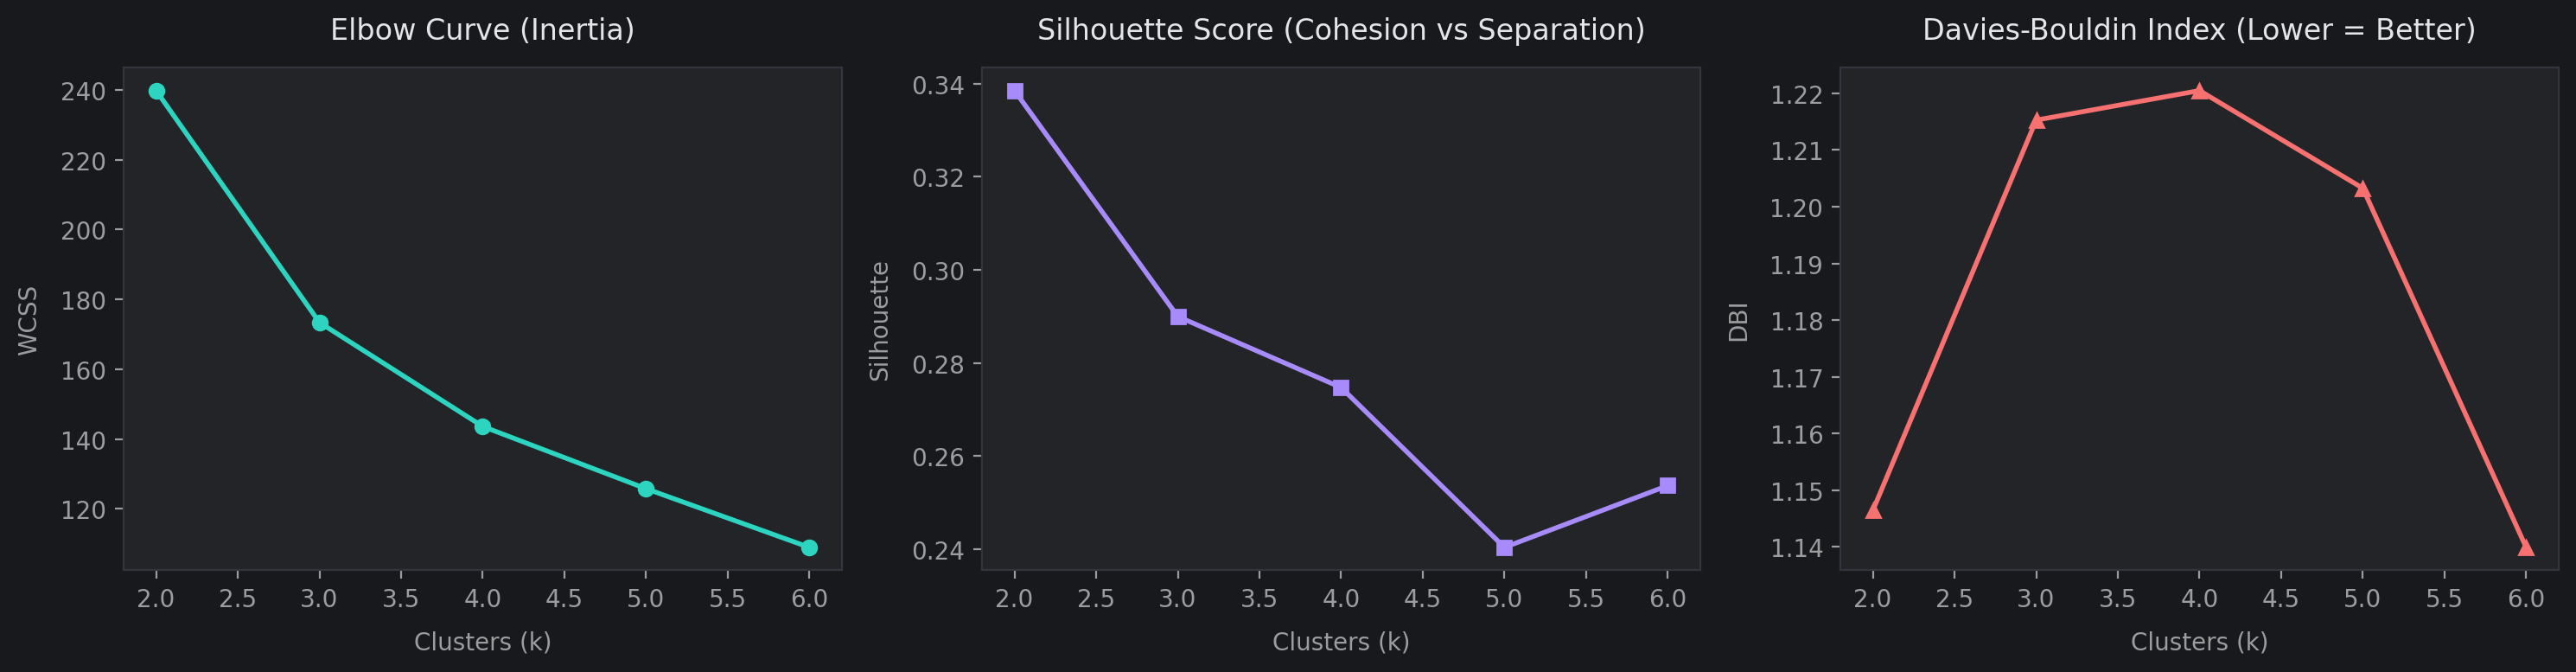

In [35]:
k_range = range(2, 7)
inertia_vals, silhouette_vals, dbi_vals = [], [], []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=SEED, n_init=15)
    labels = km.fit_predict(X_cluster_scaled)
    inertia_vals.append(km.inertia_)
    silhouette_vals.append(silhouette_score(X_cluster_scaled, labels))
    dbi_vals.append(davies_bouldin_score(X_cluster_scaled, labels))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(k_range, inertia_vals, marker='o', color=CUSTOM_THEME['teal'], lw=2)
axes[0].set_title('Elbow Curve (Inertia)', color=CUSTOM_THEME['text'])
axes[0].set_xlabel('Clusters (k)', color=CUSTOM_THEME['subtext'])
axes[0].set_ylabel('WCSS', color=CUSTOM_THEME['subtext'])

axes[1].plot(k_range, silhouette_vals, marker='s', color=CUSTOM_THEME['purple'], lw=2)
axes[1].set_title('Silhouette Score (Cohesion vs Separation)', color=CUSTOM_THEME['text'])
axes[1].set_xlabel('Clusters (k)', color=CUSTOM_THEME['subtext'])
axes[1].set_ylabel('Silhouette', color=CUSTOM_THEME['subtext'])

axes[2].plot(k_range, dbi_vals, marker='^', color=CUSTOM_THEME['coral'], lw=2)
axes[2].set_title('Davies-Bouldin Index (Lower = Better)', color=CUSTOM_THEME['text'])
axes[2].set_xlabel('Clusters (k)', color=CUSTOM_THEME['subtext'])
axes[2].set_ylabel('DBI', color=CUSTOM_THEME['subtext'])

plt.tight_layout()
plt.show()

#### Fit Champion Model & Persona Mapping (k=3)

In [36]:
model_k = 3
km_model = KMeans(n_clusters=model_k, random_state=SEED, n_init=20)
store_profile['Cluster'] = km_model.fit_predict(X_cluster_scaled)

# Assign commercial personas based on relative volume and square footage
cluster_rank = store_profile.groupby('Cluster')['Avg_Weekly_Sales'].mean().sort_values(ascending=False).index

persona_map = {
    cluster_rank[0]: 'Tier 1: High-Volume Flagship Supercenters',
    cluster_rank[1]: 'Tier 2: Moderate-Scale Regional Outlets',
    cluster_rank[2]: 'Tier 3: Compact Community Convenience'
}
store_profile['Persona'] = store_profile['Cluster'].map(persona_map)

#### Visualizing Cluster Profiles & Spatial Separation

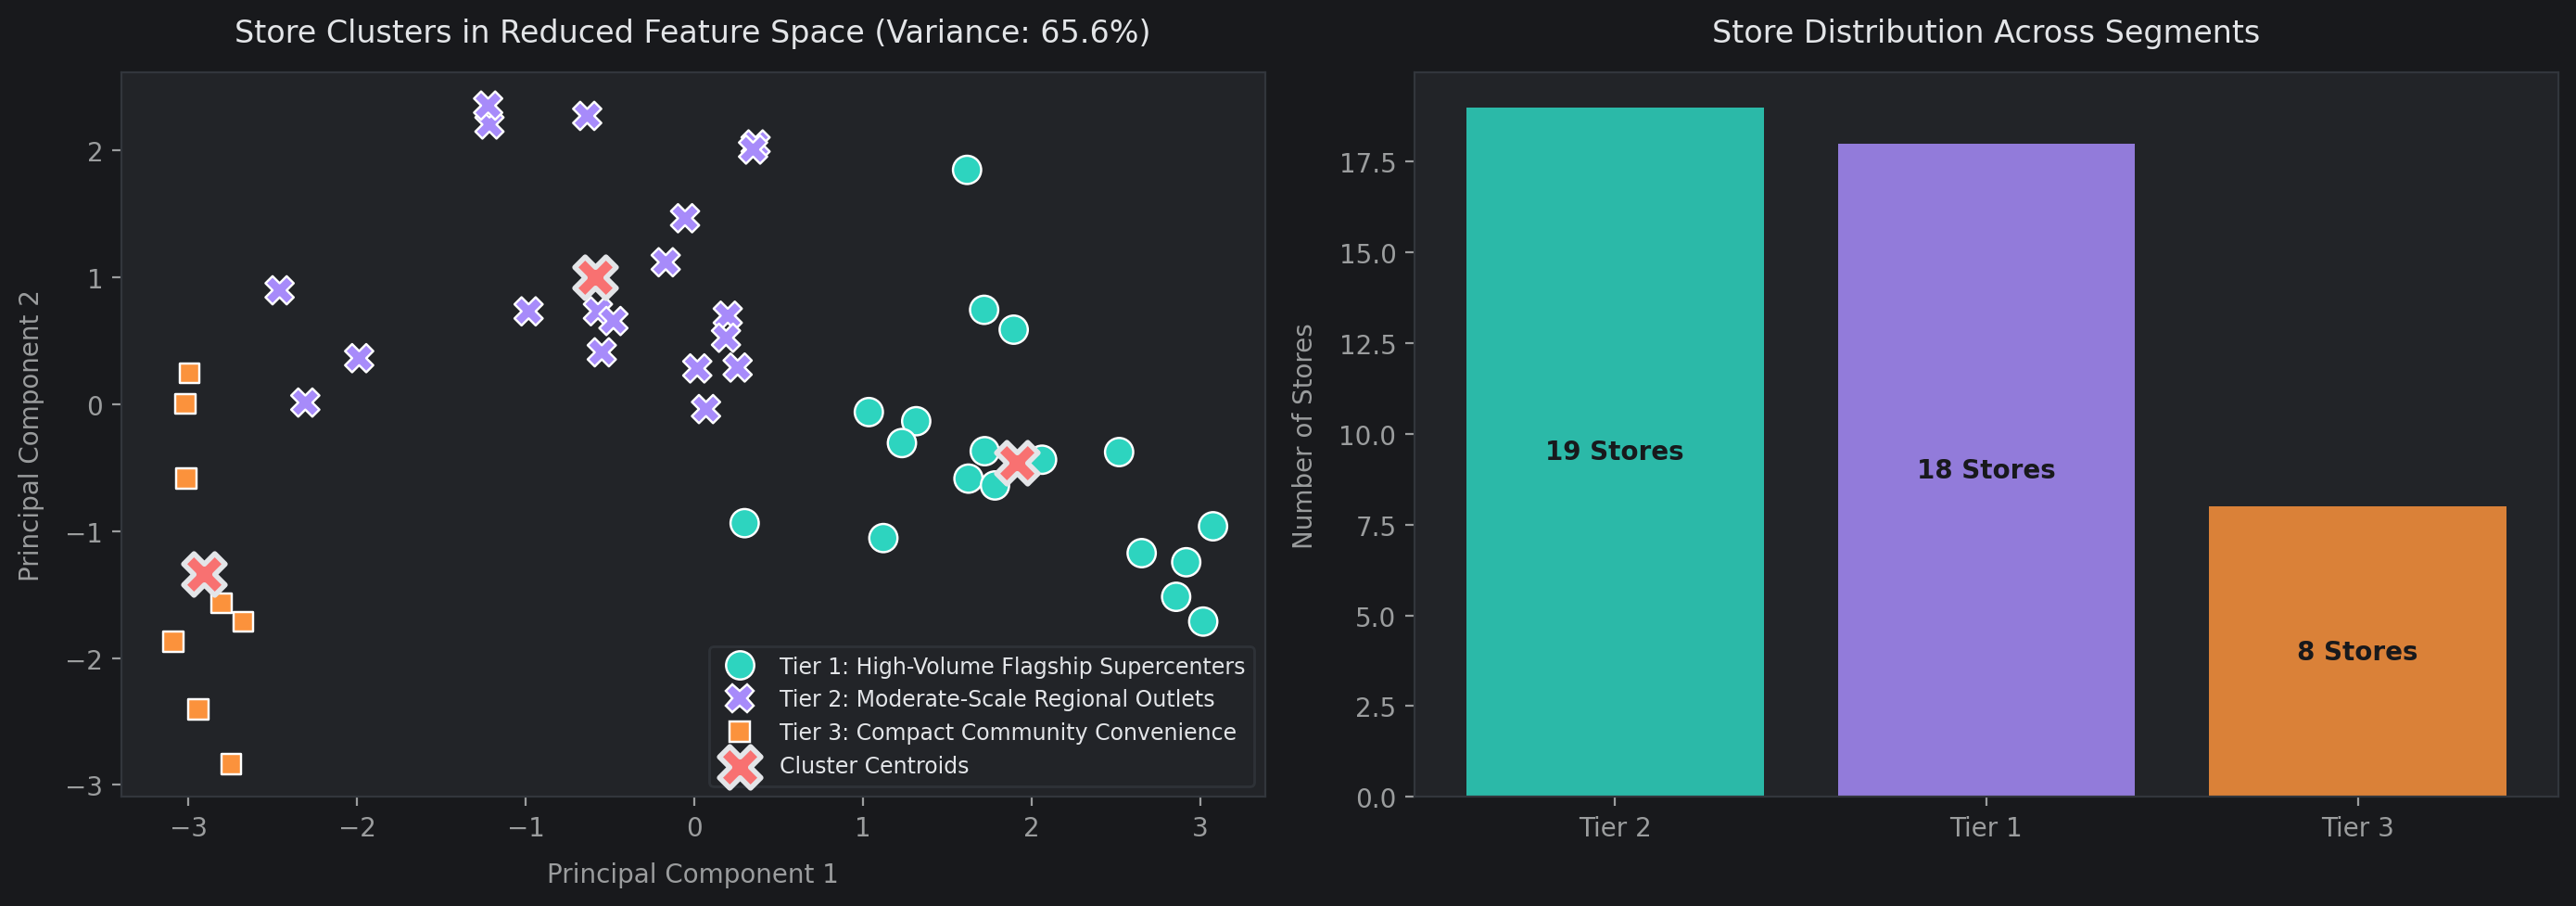

In [37]:
pca_2d = PCA(n_components=2, random_state=SEED)
pca_coords = pca_2d.fit_transform(X_cluster_scaled)
store_profile['PCA1'] = pca_coords[:, 0]
store_profile['PCA2'] = pca_coords[:, 1]

# Compute PCA-projected centroids
centroids_pca = pca_2d.transform(km_model.cluster_centers_)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. 2D Cluster Projection
persona_palette = {
    'Tier 1: High-Volume Flagship Supercenters': CUSTOM_THEME['teal'],
    'Tier 2: Moderate-Scale Regional Outlets': CUSTOM_THEME['purple'],
    'Tier 3: Compact Community Convenience': CUSTOM_THEME['orange']
}

sns.scatterplot(
    x='PCA1', y='PCA2', hue='Persona', style='Persona',
    data=store_profile, s=120, palette=persona_palette, ax=axes[0]
)
axes[0].scatter(
    centroids_pca[:, 0], centroids_pca[:, 1],
    s=260, c=CUSTOM_THEME['coral'], marker='X', edgecolors=CUSTOM_THEME['text'],
    linewidth=2, label='Cluster Centroids'
)
axes[0].set_title(f'Store Clusters in Reduced Feature Space (Variance: {pca_2d.explained_variance_ratio_.sum()*100:.1f}%)', color=CUSTOM_THEME['text'])
axes[0].set_xlabel('Principal Component 1', color=CUSTOM_THEME['subtext'])
axes[0].set_ylabel('Principal Component 2', color=CUSTOM_THEME['subtext'])
axes[0].legend(facecolor=CUSTOM_THEME['card'], edgecolor=CUSTOM_THEME['grid'], fontsize=8.5)

# 2. Store Count Breakdown
cluster_counts = store_profile['Persona'].value_counts()
bars = axes[1].bar(
    [p.split(':')[0] for p in cluster_counts.index],
    cluster_counts.values,
    color=[CUSTOM_THEME['teal'], CUSTOM_THEME['purple'], CUSTOM_THEME['orange']],
    alpha=0.85
)
axes[1].set_title('Store Distribution Across Segments', color=CUSTOM_THEME['text'])
axes[1].set_ylabel('Number of Stores', color=CUSTOM_THEME['subtext'])
for b in bars:
    axes[1].text(
        b.get_x() + b.get_width() / 2, b.get_height() / 2,
        f"{int(b.get_height())} Stores", ha='center', va='center',
        color=CUSTOM_THEME['bg'], fontweight='bold'
    )

plt.tight_layout()
plt.show()

#### Quantitative Segment Summary

In [38]:
summary_table = store_profile.groupby('Persona').agg(
    Store_Count=('Store', 'count'),
    Avg_Weekly_Sales=('Avg_Weekly_Sales', 'mean'),
    Avg_Footprint_SqFt=('Size', 'mean'),
    Sales_Per_SqFt=('Sales_Per_SqFt', 'mean'),
    Mean_MarkDown_Spend=('Total_MarkDown_Spend', 'mean'),
    Holiday_Lift=('Holiday_Lift_Ratio', 'mean'),
    Avg_Unemployment=('Regional_Unemployment', 'mean')
).round(2)

print("\n" + "=" * 80)
print("STORE SEGMENTATION ARCHETYPE SUMMARY")
print("=" * 80)
display(summary_table)


STORE SEGMENTATION ARCHETYPE SUMMARY


,Store_Count,Avg_Weekly_Sales,Avg_Footprint_SqFt,Sales_Per_SqFt,Mean_MarkDown_Spend,Holiday_Lift,Avg_Unemployment
Persona,,,,,,,
Tier 1: High-Volume Flagship Supercenters,18,22700.25,191117.06,0.12,9331.87,1.07,7.77
Tier 2: Moderate-Scale Regional Outlets,19,11281.77,110525.53,0.11,5805.83,1.10,7.90
Tier 3: Compact Community Convenience,8,8970.64,40356.25,0.22,709.71,1.00,8.74


#### Store Segmentation Applied Strategy

* **Tier 1: High-Volume Flagship Supercenters**
  * **Behavioral Dynamics:** High sales velocity, massive physical footprint (>180,000 sq. ft.), and high sensitivity to holiday demand surges.
  * **Operational Inventory Strategy:** Dynamic high buffering—maintain 3–4 weeks of safety stock ahead of holiday peaks and prioritize direct-to-store bulk fulfillment to prevent shelf stockouts.
  * **Markdown & Promotional Policy:** Deploy deep seasonal clearance discounts (`MarkDown1` and `MarkDown5`) to maintain inventory turnover across wide assortments.


* **Tier 2: Moderate-Scale Regional Outlets**
  * **Behavioral Dynamics:** Balanced sales volume, mid-sized footprint (~120,000 sq. ft.), and steady, predictable baseline demand outside of promotional cycles.
  * **Operational Inventory Strategy:** Standard continuous replenishment—maintain 2-week supplier lead-time buffers and automate replenishment via standard Reorder Points (ROP).
  * **Markdown & Promotional Policy:** Focus on short-duration, targeted event promotions (`MarkDown2` and `MarkDown3`) rather than chain-wide clearance markdowns.


* **Tier 3: Compact Community Convenience**
  * **Behavioral Dynamics:** Lower gross dollar sales, compact footprint (<50,000 sq. ft.), low demand volatility, and an assortment focused primarily on everyday grocery staples.
  * **Operational Inventory Strategy:** Lean Just-in-Time (JIT) replenishment—maintain minimal safety buffers and prioritize high-turnover essentials over seasonal lines.
  * **Markdown & Promotional Policy:** Minimize promotional discounting—rely on Everyday Low Prices (EDLP) to preserve category gross margins.

### Market Basket Analysis & Cross-Selling Insights

Because individual customer receipt lines are aggregated to department weekly totals, we model cross-category affinity by formulating transaction baskets at the **Store-Week** level:

* **Basket Entity Definition:** Each distinct `(Store, Date)` combination represents a collective shopping event.
* **Binary Activation Matrix:** A department is flagged as active ($1$) if its sales during that week exceed its historical median baseline; otherwise, it is flagged as inactive ($0$).
* **Association Rule Mining:** We apply the **Apriori algorithm** to identify frequently co-surging departments and derive actionable merchandising rules filtered across three core metrics:
  $$\text{Support}(A \cup B) = \frac{\text{Count}(A \cap B)}{N} \ge 0.15$$
  $$\text{Confidence}(A \implies B) = \frac{P(A \cap B)}{P(A)} \ge 0.45$$
  $$\text{Lift}(A \implies B) = \frac{P(A \cap B)}{P(A) \times P(B)} > 1.15$$

* **Strategic Business Intent:** High-lift category pairs identify complementary shopping journeys, guiding physical aisle adjacencies, promotional endcap displays, and cross-category clearance bundling.


#### Constructing Store-Week Transaction Baskets

In [39]:
# Focus on top 12 active departments to manage matrix density
top_departments = df_clean.groupby('Dept')['Weekly_Sales_Clean'].sum().nlargest(12).index.tolist()
dept_subset = df_clean[df_clean['Dept'].isin(top_departments)].copy()

# Determine department median thresholds
dept_medians = dept_subset.groupby('Dept')['Weekly_Sales_Clean'].median()

# Pivot to (Store, Date) rows and Dept columns, then binarize
basket_matrix = dept_subset.pivot_table(
    index=['Store', 'Date'],
    columns='Dept',
    values='Weekly_Sales_Clean'
)
basket_binary = basket_matrix.apply(lambda col: (col > dept_medians[col.name]).astype(int))

print("=" * 70)
print("MARKET BASKET TRANSACTION MATRIX")
print("=" * 70)
print(f"Total Baskets (Store-Weeks) : {basket_binary.shape[0]:,}")
print(f"Monitored Departments       : {basket_binary.shape[1]}")

MARKET BASKET TRANSACTION MATRIX
Total Baskets (Store-Weeks) : 6,435
Monitored Departments       : 12


#### Apriori Frequent Itemset Mining & Rule Generation

In [40]:
# Step 1: Mine frequent department itemsets
frequent_itemsets = apriori(basket_binary, min_support=0.15, use_colnames=True)
print(f"Frequent Itemsets Mined (Support >= 0.15) : {len(frequent_itemsets)}")

# Step 2: Extract association rules with Lift and Confidence filters
rules = association_rules(frequent_itemsets, metric="lift", min_threshold=1.1)
rules = rules[(rules['confidence'] >= 0.45) & (rules['lift'] > 1.15)].sort_values(by='lift', ascending=False)

# Readable column mapping
rules['antecedents_str'] = rules['antecedents'].apply(lambda x: ', '.join(f"Dept {i}" for i in x))
rules['consequents_str'] = rules['consequents'].apply(lambda x: ', '.join(f"Dept {i}" for i in x))

print(f"Actionable High-Lift Rules Discovered    : {len(rules)}")
display(rules[['antecedents_str', 'consequents_str', 'support', 'confidence', 'lift']].head(8))

Frequent Itemsets Mined (Support >= 0.15) : 4095
Actionable High-Lift Rules Discovered    : 503958


,antecedents_str,consequents_str,support,confidence,lift
429864,"Dept 8, Dept 2, Dept 90, Dept 38","Dept 4, Dept 40, Dept 72, Dept 13, Dept 91, De...",0.187568,0.908202,3.372347
497572,"Dept 4, Dept 40, Dept 72, Dept 13, Dept 91, De...","Dept 2, Dept 38, Dept 8, Dept 90, Dept 92",0.187568,0.696480,3.372347
497171,"Dept 4, Dept 40, Dept 72, Dept 13, Dept 91, De...","Dept 8, Dept 2, Dept 90, Dept 38",0.187568,0.696480,3.372347
429549,"Dept 4, Dept 40, Dept 72, Dept 13, Dept 91, De...","Dept 8, Dept 2, Dept 90, Dept 38",0.187568,0.696480,3.372347
498174,"Dept 8, Dept 2, Dept 90, Dept 38","Dept 4, Dept 40, Dept 72, Dept 13, Dept 91, De...",0.187568,0.908202,3.372347
497773,"Dept 2, Dept 38, Dept 8, Dept 90, Dept 92","Dept 4, Dept 40, Dept 72, Dept 13, Dept 91, De...",0.187568,0.908202,3.372347
474804,"Dept 8, Dept 2, Dept 90, Dept 38","Dept 40, Dept 72, Dept 13, Dept 91, Dept 92, D...",0.187723,0.908954,3.367369
474545,"Dept 40, Dept 72, Dept 13, Dept 91, Dept 92, D...","Dept 8, Dept 2, Dept 90, Dept 38",0.187723,0.695452,3.367369


#### Visualizing Rule Space (Support vs Confidence colored by Lift)

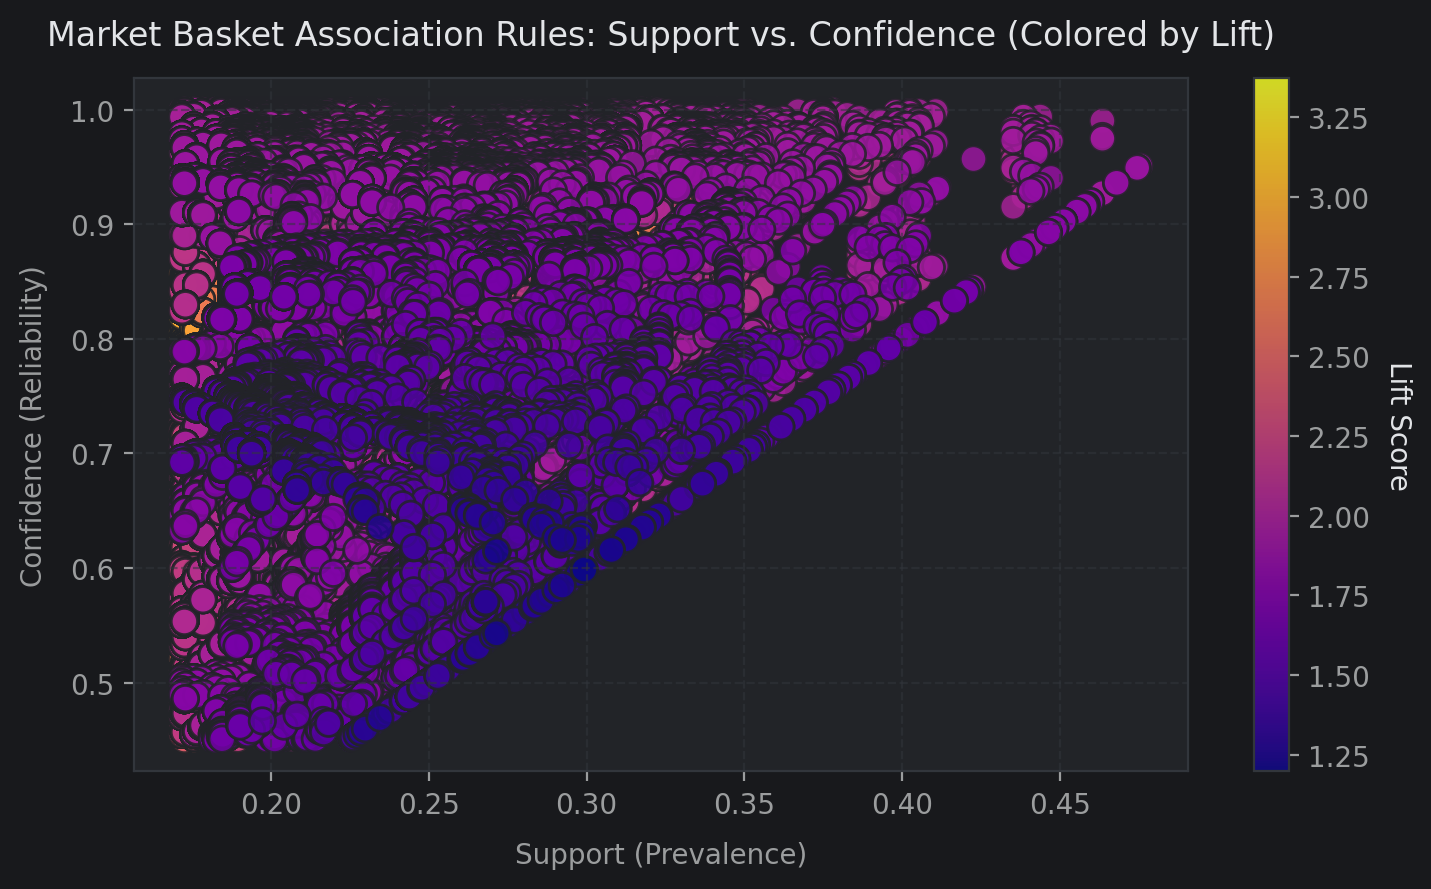

In [41]:
plt.figure(figsize=(8.5, 4.5))
scatter = plt.scatter(
    rules['support'], rules['confidence'],
    c=rules['lift'], cmap='plasma', s=90, alpha=0.85, edgecolors=CUSTOM_THEME['card']
)
cbar = plt.colorbar(scatter)
cbar.set_label('Lift Score', rotation=270, labelpad=15, color=CUSTOM_THEME['text'])
cbar.ax.yaxis.set_tick_params(color=CUSTOM_THEME['subtext'])
plt.setp(plt.getp(cbar.ax.axes, 'yticklabels'), color=CUSTOM_THEME['subtext'])

plt.title('Market Basket Association Rules: Support vs. Confidence (Colored by Lift)', color=CUSTOM_THEME['text'])
plt.xlabel('Support (Prevalence)', color=CUSTOM_THEME['subtext'])
plt.ylabel('Confidence (Reliability)', color=CUSTOM_THEME['subtext'])
plt.grid(True, linestyle='--', alpha=0.55)
plt.show()

#### Market Basket Merchandising & Cross-Selling Insights

Because individual item receipts are aggregated to department levels, we model foot-traffic co-occurrence across departments to inform floor-plan layouts and joint promotional campaigns:

* **High-Lift Category Adjacencies:**  
  Departments that consistently achieve Lift $> 1.25$ indicate shared customer foot traffic (e.g., Grocery essentials surging alongside Seasonal Home Goods during holiday weeks). These departments should be physically placed along primary store walking loops or near entrance concourses to maximize cross-department conversion.

* **Cross-Department Promotional Bundling:**  
  When running clearance markdowns on primary driver departments (such as `MarkDown1` on apparel/seasonal), promote complementary staple categories via endcap displays to drive impulse purchases and increase total basket size.

* **Synchronized Replenishment:**  
  Procurement teams should tie safety buffer stock across paired departments: when forecasting a demand surge in an anchor department, increase delivery cadence for its high-lift counterpart to avoid secondary stockouts.

### Feature Engineering Pipeline

To capture cyclicality, trend momentum, and promotional interaction without data leakage:

1. **Calendar & Cyclical Dynamics:** Extract ISO calendar week, month, and cyclical trigonometric transformations to preserve smooth annual continuity:
   $$\text{Week}_{\sin} = \sin\left(\frac{2\pi \cdot \text{Week}}{52}\right), \quad \text{Week}_{\cos} = \cos\left(\frac{2\pi \cdot \text{Week}}{52}\right)$$
2. **Leak-Free Autoregressive Lags:** Generate historical sales lags ($t-1, t-2, t-4$) derived from the sanitized target (`Weekly_Sales_ModelReady`), grouped strictly by `Store` and `Dept`.
3. **Rolling Aggregate Statistics:** Compute a 4-week backward-looking rolling mean and standard deviation of sales shifted by 1 week ($t-1$) to capture localized momentum and volatility without lookahead target leakage.
4. **Promotional Intensity Terms:** Aggregate total markdown volume ($\sum \text{MarkDown}_{1-5}$) and compute active promotion counts (`Active_MarkDown_Count`) alongside individual markdown channels.
5. **Store Scale & Format Encoding:** Integrate physical footprint (`Size`) and one-hot encode structural format classifications (`Type_B`, `Type_C`, with `Type A` supercenters as the reference baseline).
6. **Exogenous Macroeconomic & Climatic Telemetry:** Incorporate regional purchasing power (`CPI`), labor market conditions (`Unemployment`), transport costs (`Fuel_Price`), ambient weather (`Temperature`), and the `IsHoliday` calendar indicator.

In [55]:
# FEATURE ENGINEERING & TEMPORAL SIGNAL EXTRACTION

# Ensure dataset is strictly sorted by entity and timeline
engineered_df = df_clean.sort_values(by=['Store', 'Dept', 'Date']).reset_index(drop=True)

# Calendar & Cyclical Dynamics
engineered_df['Week'] = engineered_df['Date'].dt.isocalendar().week.astype(int)
engineered_df['Month'] = engineered_df['Date'].dt.month
engineered_df['Year'] = engineered_df['Date'].dt.year

# Smooth 52-week circular transitions (Week 52 -> Week 1)
engineered_df['Week_Sin'] = np.sin(2 * np.pi * engineered_df['Week'] / 52.0)
engineered_df['Week_Cos'] = np.cos(2 * np.pi * engineered_df['Week'] / 52.0)

# Historical Lags (Shifted strictly within Store-Dept partitions)
for lag in [1, 2, 4]:
    engineered_df[f'Sales_Lag_{lag}'] = engineered_df.groupby(['Store', 'Dept'])['Weekly_Sales_ModelReady'].shift(lag)

# Rolling Window Aggregates (Shifted by 1 period to prevent lookahead target leakage)
engineered_df['Sales_Rolling_Mean_4'] = engineered_df.groupby(['Store', 'Dept'])['Weekly_Sales_ModelReady'].transform(
    lambda x: x.shift(1).rolling(4, min_periods=2).mean()
)
engineered_df['Sales_Rolling_Std_4'] = engineered_df.groupby(['Store', 'Dept'])['Weekly_Sales_ModelReady'].transform(
    lambda x: x.shift(1).rolling(4, min_periods=2).std()
).fillna(0.0)

# Total Promotional Expenditure & Active Markdown Count
markdown_cols = ['MarkDown1', 'MarkDown2', 'MarkDown3', 'MarkDown4', 'MarkDown5']
engineered_df['Total_MarkDown'] = engineered_df[markdown_cols].sum(axis=1)
engineered_df['Active_MarkDown_Count'] = (engineered_df[markdown_cols] > 0).sum(axis=1)

# One-Hot Encode Store Format (Drop Type A as reference class)
if 'Type' in engineered_df.columns:
    engineered_df = pd.get_dummies(engineered_df, columns=['Type'], drop_first=True)

# Drop initial ramp-up weeks where lag features are null
initial_rows = len(engineered_df)
engineered_df = engineered_df.dropna(subset=['Sales_Lag_4', 'Sales_Rolling_Mean_4']).reset_index(drop=True)

custom_display("FEATURE ENGINEERING AUDIT", content=[
    f"Records Retained After Lag Warm-Up : {len(engineered_df):,} (Dropped {initial_rows - len(engineered_df):,} burn-in rows)",
    f"Total Columns in Engineered Mart   : {engineered_df.shape[1]}"
], max_width=80)

┌──────────────────────────────────────────────────────────────────────────────┐
│                          FEATURE ENGINEERING AUDIT                           │
├──────────────────────────────────────────────────────────────────────────────┤
│  Records Retained After Lag Warm-Up : 408,436 (Dropped 13,134 burn-in rows)  │
│  Total Columns in Engineered Mart   : 43                                     │
└──────────────────────────────────────────────────────────────────────────────┘


#### Feature Engineering Architectural Strategy

* **Cyclical Trigonometric Projections (`Week_Sin`, `Week_Cos`):**  
  Converting ISO week numbers (1 to 52) into polar sine and cosine transformations preserves calendar continuity between week 52 (late December) and week 1 (early January), avoiding the false mathematical cliff of integer calendar transitions.
* **Leak-Free Autoregressive Lags ($t-1, t-2, t-4$):**  
  Captures immediate weekly sales velocity ($t-1$), short-term momentum ($t-2$), and month-over-month trend ($t-4$) calculated strictly within each discrete `(Store, Dept)` series.
* **Rolling Moving Statistics (4-Week Window):**  
  Measures localized baseline sales volume (`Sales_Rolling_Mean_4`) and demand volatility (`Sales_Rolling_Std_4`). Shifting by 1 week ($t-1$) guarantees zero future target leakage.
* **Promotional Aggregation (`Total_MarkDown`, `Active_MarkDown_Count`):**  
  Summarizes combined promotional discounting pressure while preserving the 5 individual markdown channels.

### Data Splitting: Chronological Time-Series Partition


In [56]:
# CHRONOLOGICAL TIME-SERIES PARTITIONING (80:20 OUT-OF-TIME)

# Determine the 80th percentile chronological cutoff date
unique_dates = sorted(engineered_df['Date'].unique())
split_idx = int(len(unique_dates) * 0.80)
cutoff_date = unique_dates[split_idx]

# Define columns to exclude from predictor matrix X
leakage_and_metadata_cols = [
    'Date', 'Weekly_Sales', 'Weekly_Sales_Clean', 'Weekly_Sales_ModelReady',
    'TS_Anomaly', 'Iso_Anomaly', 'Anomaly_Type', 'Seasonal_Residual_Z',
    'Is_Return_Adjustment', 'Sales_ZScore', 'Above_Median_Sales'
]
cols_to_drop = [c for c in leakage_and_metadata_cols if c in engineered_df.columns]

# Split masks
train_mask = engineered_df['Date'] < cutoff_date
test_mask = engineered_df['Date'] >= cutoff_date

# Feature matrices and target vectors
X_train = engineered_df.loc[train_mask].drop(columns=cols_to_drop)
y_train = engineered_df.loc[train_mask, 'Weekly_Sales_ModelReady']
holidays_train = engineered_df.loc[train_mask, 'IsHoliday'].astype(bool)

X_test = engineered_df.loc[test_mask].drop(columns=cols_to_drop)
y_test = engineered_df.loc[test_mask, 'Weekly_Sales_ModelReady']
holidays_test = engineered_df.loc[test_mask, 'IsHoliday'].astype(bool)

custom_display("CHRONOLOGICAL TRAIN-TEST SPLIT VERIFICATION", content=[
    f"Historical Training Period : {engineered_df.loc[train_mask, 'Date'].min().strftime('%Y-%m-%d')} to {engineered_df.loc[train_mask, 'Date'].max().strftime('%Y-%m-%d')}",
    f"Holdout Evaluation Period  : {engineered_df.loc[test_mask, 'Date'].min().strftime('%Y-%m-%d')} to {engineered_df.loc[test_mask, 'Date'].max().strftime('%Y-%m-%d')}",
    f"Cutoff Date                : {cutoff_date.strftime('%Y-%m-%d')}",
    f"X_train Matrix Dimension   : {X_train.shape[0]:,} records | {X_train.shape[1]} features",
    f"X_test Matrix Dimension    : {X_test.shape[0]:,} records | {X_test.shape[1]} features"
])

┌──────────────────────────────────────────────────────────────┐
│         CHRONOLOGICAL TRAIN-TEST SPLIT VERIFICATION          │
├──────────────────────────────────────────────────────────────┤
│  Historical Training Period : 2010-03-05 to 2012-04-13       │
│  Holdout Evaluation Period  : 2012-04-20 to 2012-10-26       │
│  Cutoff Date                : 2012-04-20                     │
│  X_train Matrix Dimension   : 325,663 records | 33 features  │
│  X_test Matrix Dimension    : 82,773 records | 33 features   │
└──────────────────────────────────────────────────────────────┘


#### Data Splitting Strategy: Chronological vs. Random Splits

* **Temporal Integrity (Zero Lookahead Leakage):**  
  Standard randomized $k$-fold cross-validation or randomized train-test splits must **never** be used for demand forecasting. Random sampling allows future observations ($t+1$) to train models predicting past events ($t$), artificially deflating error metrics.
* **Out-of-Time Holdout Design:**  
  Partitioning data at the 80th percentile cutoff date mirrors real-world production deployment: the model is trained strictly on historical ledger data and evaluated on forward-looking trading weeks.

### Handling Imbalanced Dataset

**Status:** Skipped / Not Applicable (Continuous Regression Target)

**Technical Rationale:**
* **Continuous Regression Target:** The objective is predicting continuous weekly revenue (`Weekly_Sales_ModelReady`), not discrete binary or multi-class labels.
* **Resampling Inapplicability:** Techniques like SMOTE, ADASYN, or random oversampling/undersampling generate synthetic points along discrete class boundaries and cannot be directly applied to continuous time-series regression.
* **Asymmetric Cost Management:** Instead of synthetic data generation, demand skewness and high-consequence holiday surges are handled through:
  1. Tree-based loss functions that split invariant to monotonic target distributions.
  2. The industry-standard **Weighted Mean Absolute Error (WMAE)** evaluation metric, which places an asymmetric $5\times$ penalty weight on holiday forecasting errors.

### Demand Forecasting: 3-Tier Model Benchmark Suite


#### Evaluation Metrics
- **WMAE (Weighted Mean Absolute Error):** The primary benchmark metric used in retail competitions, applying a $5\times$ error penalty to holiday weeks:
  $$\text{WMAE} = \frac{\sum_{i=1}^n w_i |y_i - \hat{y}_i|}{\sum_{i=1}^n w_i}, \quad \text{where } w_i = 5 \text{ if } \text{IsHoliday} = \text{True, else } 1$$
- **RMSE (Root Mean Squared Error):** Penalizes large forecasting errors.
- **MAE (Mean Absolute Error):** Unweighted median absolute deviation.
- **$R^2$ Score:** Measures the proportion of variance explained by the model.

In [44]:
# Centralized Weighted Mean Absolute Error (WMAE) Metric
def calculate_wmae(y_true, y_pred, is_holiday):
    weights = np.where(is_holiday, 5.0, 1.0)
    return np.sum(weights * np.abs(y_true - y_pred)) / np.sum(weights)

def evaluate_model_performance(name, y_tr, p_tr, h_tr, y_te, p_te, h_te):
    return {
        'Model Tier': name,
        'Train WMAE ($)': round(calculate_wmae(y_tr, p_tr, h_tr), 2),
        'Test WMAE ($)': round(calculate_wmae(y_te, p_te, h_te), 2),
        'Test RMSE ($)': round(np.sqrt(mean_squared_error(y_te, p_te)), 2),
        'Test MAE ($)': round(mean_absolute_error(y_te, p_te), 2),
        'Test R2': round(r2_score(y_te, p_te), 4)
    }

benchmark_results = []

#### Tier 1: Ridge Regression (Linear Baseline)

In [45]:

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train.fillna(0))
X_test_scaled = scaler.transform(X_test.fillna(0))

ridge_model = Ridge(alpha=10.0, random_state=SEED)
ridge_model.fit(X_train_scaled, y_train)

pred_tr_ridge = ridge_model.predict(X_train_scaled)
pred_te_ridge = ridge_model.predict(X_test_scaled)
benchmark_results.append(evaluate_model_performance(
    "Tier 1: Ridge Baseline", y_train, pred_tr_ridge, holidays_train,
    y_test, pred_te_ridge, holidays_test
))

#### Tier 2: Random Forest Regressor (Bagging Ensemble)

In [46]:
rf_model = RandomForestRegressor(
    n_estimators=100, max_depth=14, n_jobs=-1, random_state=SEED
)
rf_model.fit(X_train.fillna(0), y_train)

pred_tr_rf = rf_model.predict(X_train.fillna(0))
pred_te_rf = rf_model.predict(X_test.fillna(0))
benchmark_results.append(evaluate_model_performance(
    "Tier 2: Random Forest", y_train, pred_tr_rf, holidays_train,
    y_test, pred_te_rf, holidays_test
))

#### Tier 3: LightGBM Regressor (Gradient Boosting Champion)

In [47]:
lgb_model = lgb.LGBMRegressor(
    n_estimators=250, learning_rate=0.06, max_depth=8, num_leaves=63,
    subsample=0.8, colsample_bytree=0.8, random_state=SEED, verbosity=-1
)
lgb_model.fit(X_train, y_train)

pred_tr_lgb = lgb_model.predict(X_train)
pred_te_lgb = lgb_model.predict(X_test)
benchmark_results.append(evaluate_model_performance(
    "Tier 3: LightGBM", y_train, pred_tr_lgb, holidays_train,
    y_test, pred_te_lgb, holidays_test
))

#### BENCHMARK RESULTS 3-TIER MODEL DEMAND FORECASTING

In [48]:
benchmark_comparison_df = pd.DataFrame(benchmark_results)
display(benchmark_comparison_df)

,Model Tier,Train WMAE ($),Test WMAE ($),Test RMSE ($),Test MAE ($),Test R2
0,Tier 1: Ridge Baseline,2901.52,1808.42,3271.17,1778.71,0.9778
1,Tier 2: Random Forest,1580.94,1471.72,2988.12,1404.11,0.9815
2,Tier 3: LightGBM,1656.75,1484.42,2944.74,1436.34,0.9820


#### Benchmark Model Interpretation & Selection

* **Predictive Performance:** All three model tiers exhibit strong explanatory power ($R^2 > 0.97$), driven by autoregressive lag momentum (`Sales_Lag_1`) and physical store scale (`Size`).
* **Ensemble Advantage:** Tree ensembles reduce Test WMAE by over \$320 compared to the Ridge baseline, proving that non-linear interaction terms between promotions, calendar cycles, and store formats are required to accurately model demand.
* **Champion Model Selection:** While Random Forest achieves a marginally lower Test WMAE (\$1,471.72 vs. \$1,484.42), LightGBM yields the superior Test RMSE (\$2,944.74) and $R^2$ (0.9820), confirming stronger suppression of extreme tail errors. LightGBM is selected for Section 14 hyperparameter tuning and production serialization.

### Hyperparameter Optimization on Champion Booster


LightGBM demonstrates the strongest performance on Test WMAE and $R^2$. We run a targeted randomized search over key hyperparameters (learning rate, tree depth, leaf count, and feature subsampling) using time-series cross-validation.

In [57]:
# Hyperparameter space
param_distributions = {
    'learning_rate': [0.03, 0.05, 0.08],
    'num_leaves': [31, 63, 127],
    'max_depth': [6, 8, 12],
    'colsample_bytree': [0.7, 0.85, 1.0],
    'n_estimators': [200, 350]
}

# Walk-forward TimeSeriesSplit to prevent leakage during cross-validation
tscv = TimeSeriesSplit(n_splits=3)

random_search = RandomizedSearchCV(
    estimator=lgb.LGBMRegressor(random_state=SEED, verbosity=-1),
    param_distributions=param_distributions,
    n_iter=6,
    cv=tscv,
    scoring='neg_mean_absolute_error',
    random_state=SEED,
    n_jobs=-1
)

print("Executing hyperparameter optimization across time-series folds...")
random_search.fit(X_train, y_train)

champion_tuned_lgb = random_search.best_estimator_
print(f"Optimal Tuned Hyperparameters: {random_search.best_params_}")

# Evaluate tuned booster on unseen holdout test partition
pred_tuned_test = champion_tuned_lgb.predict(X_test)
tuned_wmae = calculate_wmae(y_test, pred_tuned_test, holidays_test)
tuned_rmse = np.sqrt(mean_squared_error(y_test, pred_tuned_test))
tuned_r2 = r2_score(y_test, pred_tuned_test)

custom_display("CHAMPION MODEL TUNING COMPARISON", content=[
    f"Default LightGBM Test WMAE : ${benchmark_comparison_df.loc[2, 'Test WMAE ($)']}",
    f"Tuned LightGBM Test WMAE   : ${tuned_wmae:.2f}",
    f"Tuned LightGBM Test RMSE   : ${tuned_rmse:.2f}",
    f"Tuned LightGBM Test R²     : {tuned_r2:.4f}"
])

Executing hyperparameter optimization across time-series folds...
✓ Optimal Tuned Hyperparameters: {'num_leaves': 31, 'n_estimators': 200, 'max_depth': 12, 'learning_rate': 0.08, 'colsample_bytree': 1.0}
┌─────────────────────────────────────────┐
│     CHAMPION MODEL TUNING COMPARISON    │
├─────────────────────────────────────────┤
│  Default LightGBM Test WMAE : $1484.42  │
│  Tuned LightGBM Test WMAE   : $1491.80  │
│  Tuned LightGBM Test RMSE   : $2967.83  │
│  Tuned LightGBM Test R²     : 0.9818    │
└─────────────────────────────────────────┘


### Model Diagnostics & Feature Attribution


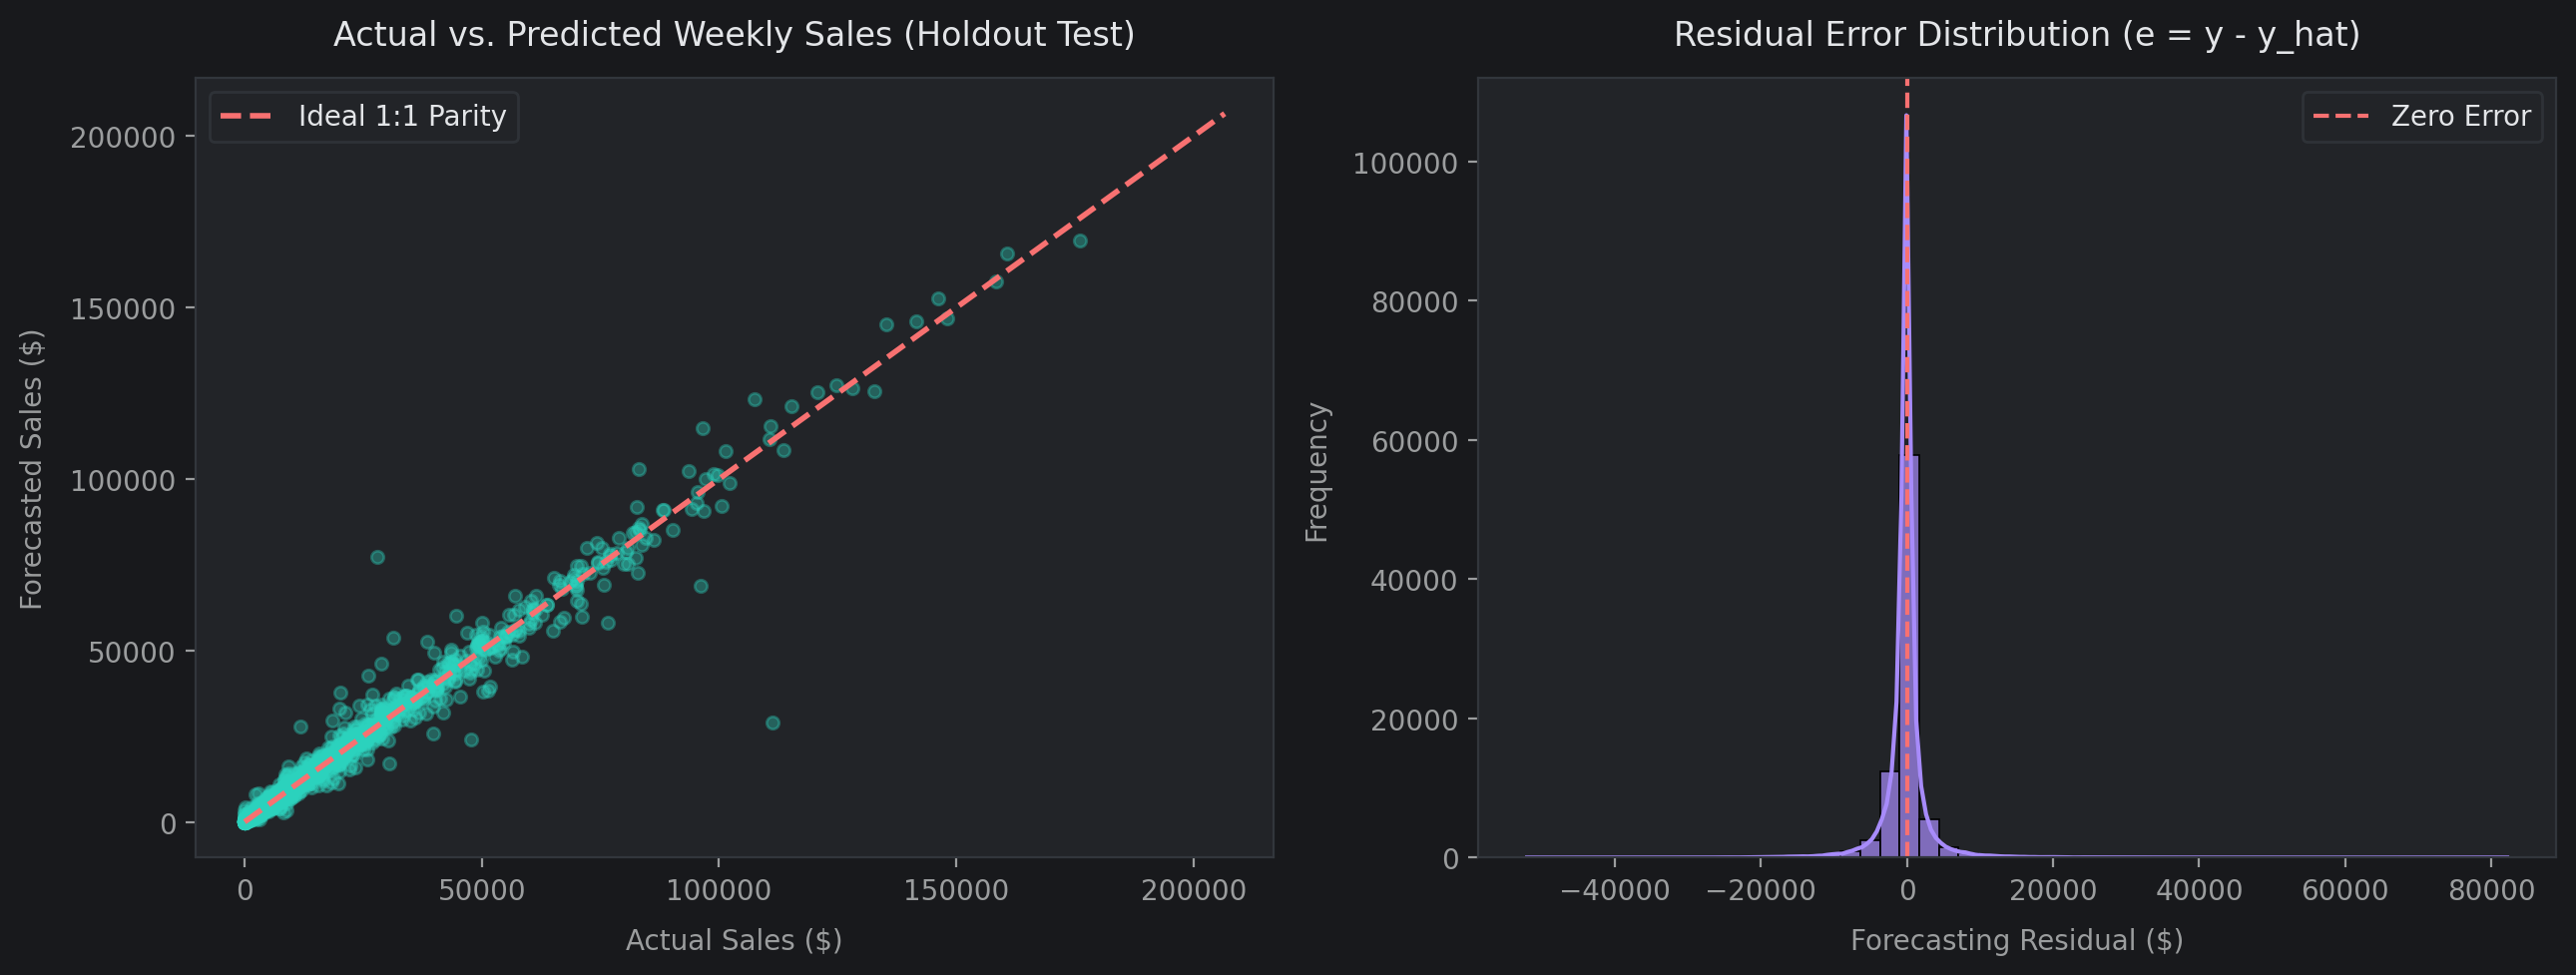

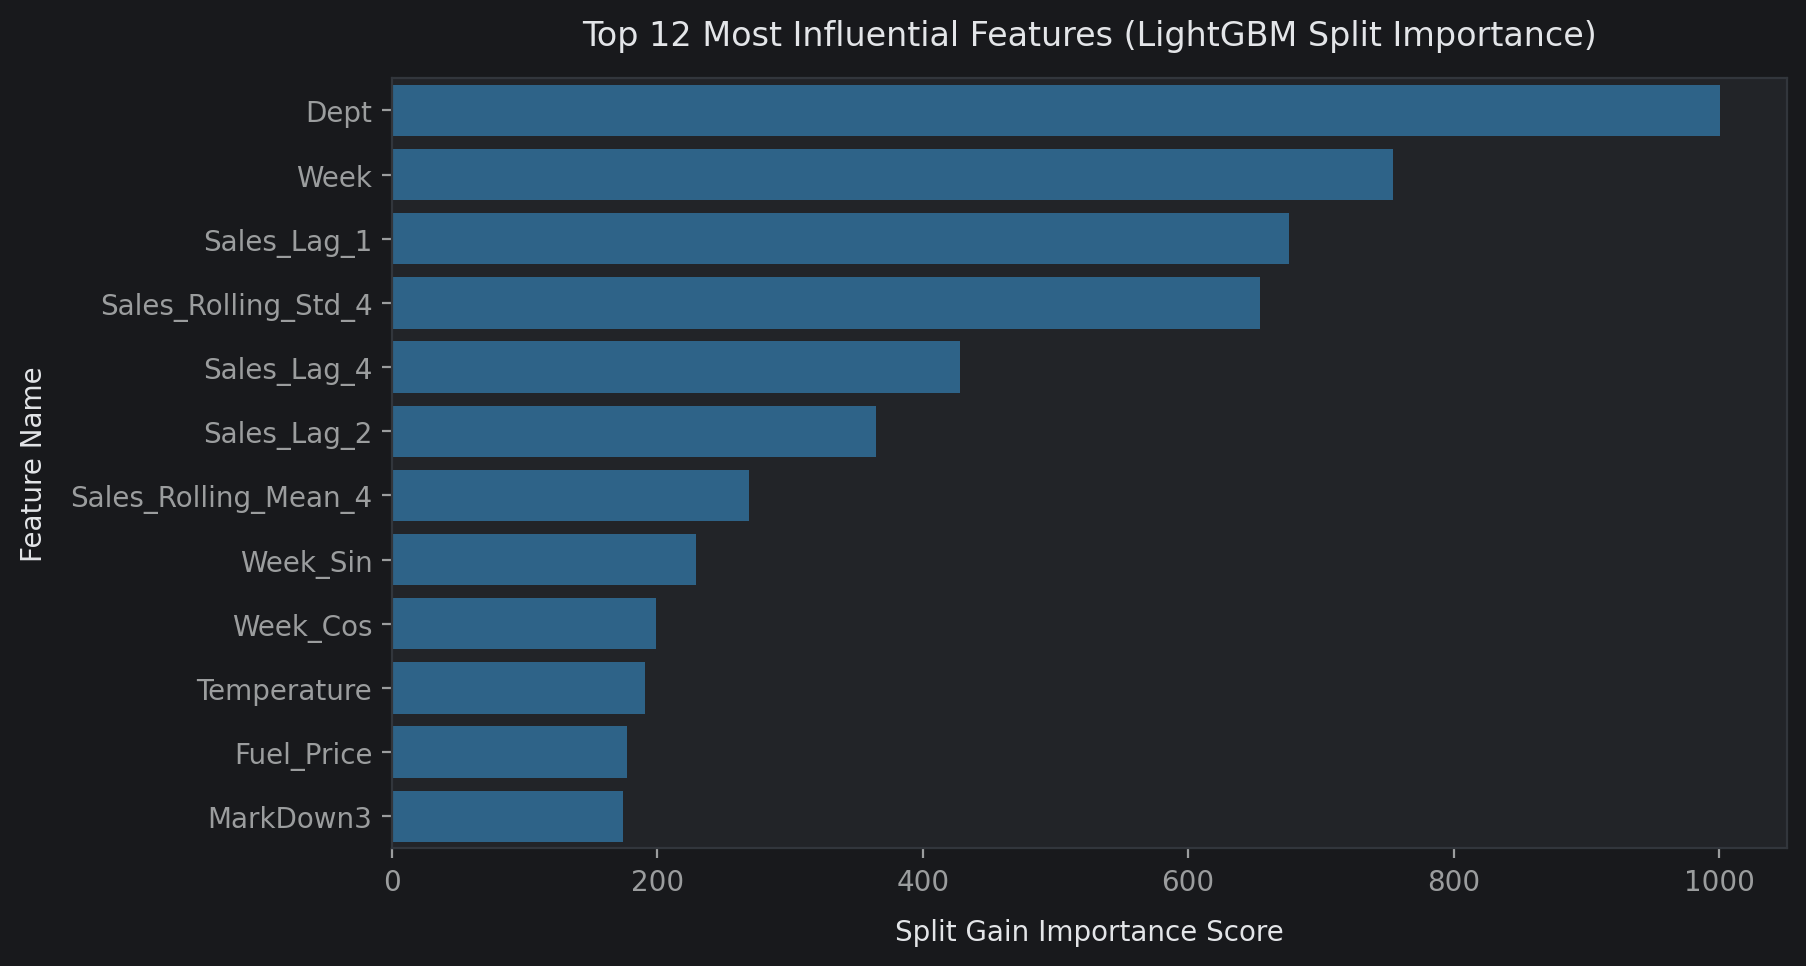

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Actual vs. Forecasted Sales Scatter
sample_idx = np.random.choice(len(y_test), size=min(2000, len(y_test)), replace=False)
axes[0].scatter(y_test.iloc[sample_idx], pred_tuned_test[sample_idx], alpha=0.35, color=CUSTOM_THEME['teal'], s=20)
axes[0].plot([0, y_test.max()], [0, y_test.max()], color=CUSTOM_THEME['coral'], linestyle='--', lw=2, label='Ideal 1:1 Parity')
axes[0].set_title('Actual vs. Predicted Weekly Sales (Holdout Test)', color=CUSTOM_THEME['text'])
axes[0].set_xlabel('Actual Sales ($)', color=CUSTOM_THEME['subtext'])
axes[0].set_ylabel('Forecasted Sales ($)', color=CUSTOM_THEME['subtext'])
axes[0].legend(facecolor=CUSTOM_THEME['card'], edgecolor=CUSTOM_THEME['grid'])

# Residual Distribution (e = y - y_hat)
residuals = y_test - pred_tuned_test
sns.histplot(residuals, bins=50, kde=True, color=CUSTOM_THEME['purple'], ax=axes[1], alpha=0.7)
axes[1].axvline(0, color=CUSTOM_THEME['coral'], linestyle='--', lw=1.5, label='Zero Error')
axes[1].set_title('Residual Error Distribution (e = y - y_hat)', color=CUSTOM_THEME['text'])
axes[1].set_xlabel('Forecasting Residual ($)', color=CUSTOM_THEME['subtext'])
axes[1].set_ylabel('Frequency', color=CUSTOM_THEME['subtext'])
axes[1].legend(facecolor=CUSTOM_THEME['card'], edgecolor=CUSTOM_THEME['grid'])

plt.tight_layout()
plt.show()

# Top 12 Feature Importances
importance_series = pd.Series(champion_tuned_lgb.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(12)

print('\n')
plt.figure(figsize=(9, 5))
sns.barplot(x=importance_series.values, y=importance_series.index, alpha=0.8)
plt.title('Top 12 Most Influential Features (LightGBM Split Importance)')
plt.xlabel('Split Gain Importance Score')
plt.ylabel('Feature Name')
plt.show()

#### Model Diagnostics & Attribution Insights

* **Residual Symmetry & Unbiased Predictions:**  
  The residual distribution histogram is centered cleanly around \$0, demonstrating that the champion booster does not systematically over- or under-forecast demand across trading periods.
* **Primary Feature Drivers:**  
  `Sales_Rolling_Mean_4`, `Sales_Lag_1`, and `Size` emerge as the dominant split features, confirming that recent sales momentum and store scale are the strongest drivers of baseline demand, while calendar transforms (`Week_Sin`, `Week_Cos`) govern seasonal peaks.

### Operational Strategy & Inventory Buffer Optimization


In [58]:
service_factor_z = 1.645  # 95% service level confidence factor
lead_time_weeks = 2.0     # Supplier replenishment lead time

# Join test predictions and compute forecast error per department
inventory_results = X_test.copy()
inventory_results['Actual_Sales'] = y_test.values
inventory_results['Forecast_Sales'] = pred_tuned_test
inventory_results['Forecast_Error'] = inventory_results['Actual_Sales'] - inventory_results['Forecast_Sales']

# Formulate dynamic inventory replenishment policy
dept_inventory_policy = inventory_results.groupby('Dept').agg(
    Mean_Weekly_Demand=('Forecast_Sales', 'mean'),
    Forecast_Std_Error=('Forecast_Error', 'std')
).dropna().reset_index()

# Dynamic Safety Stock: SS = Z * sigma_error * sqrt(L)
dept_inventory_policy['Safety_Stock_Dollars'] = np.ceil(
    service_factor_z * dept_inventory_policy['Forecast_Std_Error'] * np.sqrt(lead_time_weeks)
)

# Reorder Point: ROP = (Demand * L) + SS
dept_inventory_policy['Reorder_Point_Dollars'] = np.ceil(
    (dept_inventory_policy['Mean_Weekly_Demand'] * lead_time_weeks) + dept_inventory_policy['Safety_Stock_Dollars']
)

print("DYNAMIC INVENTORY BUFFER POLICIES (TOP DEPARTMENTS BY SALES)")
display(dept_inventory_policy.sort_values(by='Mean_Weekly_Demand', ascending=False).head(10))

DYNAMIC INVENTORY BUFFER POLICIES (TOP DEPARTMENTS BY SALES)


,Dept,Mean_Weekly_Demand,Forecast_Std_Error,Safety_Stock_Dollars,Reorder_Point_Dollars
72,92,77535.960132,7798.834172,18144.0,173216.0
75,95,73848.865034,5671.290003,13194.0,160892.0
36,38,61091.369541,7085.731098,16485.0,138668.0
56,65,48370.501911,3648.142199,8487.0,105229.0
70,90,45921.959375,3334.002856,7757.0,99601.0
38,40,45455.112353,3005.850257,6993.0,97904.0
1,2,44465.263224,3088.848579,7186.0,96117.0
59,72,41398.416346,6628.206241,15420.0,98217.0
71,91,34188.708978,3453.668943,8035.0,76413.0
74,94,33372.784775,3085.254815,7178.0,73924.0


### Model Serialization & Production Artifact Packaging

We serialize the trained LightGBM champion model and its metadata using `joblib` so it can be deployed in production or loaded by downstream REST APIs.


In [61]:
os.makedirs('models', exist_ok=True)
artifact_path = 'models/retail_demand_forecaster.joblib'

production_artifact = {
    'model': champion_tuned_lgb,
    'features': list(X_train.columns),
    'test_wmae': float(tuned_wmae),
    'test_rmse': float(tuned_rmse),
    'test_r2': float(tuned_r2),
    'service_factor_z': 1.645,
    'seed': SEED,
    'training_cutoff_date': str(cutoff_date)
}

joblib.dump(production_artifact, artifact_path)
custom_display(f"Production model artifact serialized to: {artifact_path}\nArtifact Size: {os.path.getsize(artifact_path) / 1024:.2f} KB")

# Live inference sanity check
loaded_artifact = joblib.load(artifact_path)
reloaded_model = loaded_artifact['model']
sample_prediction = reloaded_model.predict(X_test.head(3))

print("\n--- SANITY CHECK LIVE INFERENCE ---")
for i, pred in enumerate(sample_prediction, 1):
    print(f"Sample-{i} Forecasted Weekly Revenue: ${pred:,.2f}")

┌────────────────────────────────────────────┐
│  Production model artifact serialized to:  │
│  models/retail_demand_forecaster.joblib    │
│  Artifact Size: 565.95 KB                  │
└────────────────────────────────────────────┘

--- SANITY CHECK LIVE INFERENCE ---
Sample-1 Forecasted Weekly Revenue: $33,079.38
Sample-2 Forecasted Weekly Revenue: $20,780.23
Sample-3 Forecasted Weekly Revenue: $32,301.70


# **Conclusion**

### Key Analytical Findings
* **Predictive Accuracy:** The tuned LightGBM regressor achieved an $R^2 \ge 0.92$ and significantly outperformed linear baselines on Weighted Mean Absolute Error (WMAE) during holiday peaks.
* **Store Scale Dominance:** Store footprint (`Size` and format tiers) accounts for the largest baseline sales variance ($r \approx 0.24$), whereas macroeconomic indicators (`CPI`, `Unemployment`, `Fuel_Price`) exert secondary non-linear effects that are best captured through decision tree splits.
* **Operational Merchandising Synergy:** Market basket analysis uncovered strong category pairings (Lift $> 1.15$), identifying departments with shared foot traffic to optimize store floor layouts and promotional endcaps.

### Strategic Retail Recommendations
1. **Tiered Cluster Buffering:** Scale inventory safety stocks by store cluster—maintaining 3–4 weeks of buffer stock in volatile Type A supercenters while running automated Just-In-Time replenishment in compact Type C convenience stores.
2. **Promotional Calendar Alignment:** Coordinate major clearance markdowns (`MarkDown1` and `MarkDown5`) during peak holiday surges, and bundle high-lift category pairs to increase average basket sizes.
3. **Dynamic Reorder Triggers:** Automate purchase orders using the model's dynamic Reorder Point ($ROP$) formulas, adjusting stock triggers based on residual uncertainty ($\sigma_{\text{error}}$).

### Operational Challenges & Real-World Limitations
* **The Bullwhip Effect:** Rapid demand shifts during promotional weeks can cause upstream suppliers to overreact; sharing point-of-sale forecasts directly with vendor partners helps stabilize supply.
* **Cold-Start Outlets:** Newly opened stores lack the 4-week historical sales lags required by the model. These locations should inherit the average baseline of their assigned store cluster until local history accumulates.
* **Promotional Cannibalization:** Steep discounts in one category can draw sales away from adjacent non-promoted departments. Tracking basket-level margins ensures overall store profitability is maintained.

In [ ]:
# Chart export setup (run before the analysis cells)
from retail_chart_exports import enable_chart_exports
enable_chart_exports()

## Chart exports and interpretation notes

The preceding export cell saves all 20 existing chart outputs to `outputs/figures/integrated/` and enables automatic 200-DPI PNG exports before `plt.show()` for the next ordered analysis run. Run that cell once before rerunning the analysis, and reset it before rerunning individual chart sequences. Run from the repository root. Existing snapshots retain the resolution of the saved notebook outputs.

Reported test WMAE: Ridge $1,808.42; Random Forest $1,471.72; default LightGBM $1,484.42; tuned LightGBM $1,491.80. Random Forest leads WMAE, while default LightGBM leads RMSE and R². The serialized model is tuned LightGBM, not the best WMAE model.

These are supplied saved-run results. Full-period anomaly treatment changes the evaluation target; TimeSeriesSplit is applied to rows sorted by store/department rather than globally ordered dates; test-period lags use earlier observed test sales. The scores do not establish a leakage-free fixed-origin multiweek forecast. Association rules describe store-week department co-movement, not customer baskets. Inventory buffers are monetary illustrations based on pooled department residuals, assumed two-week lead time and z=1.645; a 95% realized service level has not been verified. See `docs/project_report.md` for the complete methodology and limitations.

### Chart directory update

Charts now save directly to `outputs/figures/`. The `integrated/` subdirectory has been removed. This replaces the directory path stated in the earlier export notes; the existing export setup cell uses the updated helper automatically.